# HW1 — การทำนาย Paddy Yield ด้วย Linear Regression
**FRA503 Introduction to Machine Learning (1/2569)** · Homework 1 (Ch01 Regression + Ch02 Data Preprocessing & Feature Engineering)

*สมาชิกกลุ่ม: (กรอกชื่อ / รหัสนักศึกษา)*

---
### วิธีอ่านรายงานนี้
ทุกการกระทำด้านล่างจะมี (1) **เหตุผล**, (2) **assumptions** ของเครื่องมือที่ใช้ และ (3) การตรวจสอบด้วย **ทั้งค่าสถิติและรูปภาพ** ตัวเลขทั้งหมดถูกสร้างจาก code cells (กำหนด `random_state` ตายตัว) ดังนั้นการรัน notebook ใหม่จะได้ผลเดิมทุกครั้ง

| หัวข้อใน Rubric | อยู่ที่ |
|---|---|
| 1 Problem statement | §1 |
| 2 Target exploration | §4 |
| 3 Feature exploration | §5 |
| 4 Outlier analysis | §6 |
| 5 Missing values | §7 |
| 6–8 Continuous features: visual / statistical / summary | §8 |
| 9–11 Categorical features: visual / statistical / summary | §9 |
| 12 Redundant features | §10 |
| 13 Feature extraction | §11 |
| 14 Data preprocessing | §12–13 |
| 15 Model training | §14 |
| 16 Completeness of results | §15 |
| 17 Results analysis | §15 |
| 18 Results presentation | §16 |
| 19 Discussion | §17 |
| 20 Overall ML flow | §0 (diagram) + §18 |

**ความรู้จากรายวิชาที่ใช้:** Ch01 ทั้งหมด (least squares, normal equation, gradient descent, over-fitting, train/test + K-fold CV, R², assumptions ของ regression, data representation และ scale types, encoding, normalisation/standardisation, data quality, cleaning) และ Ch02 ทั้งหมด *ยกเว้น* embedded และ wrapper feature selection (กล่าวคือใช้เฉพาะวิธีแบบ **filter**: correlation, variance threshold, ANOVA, mutual information, chi-square) + PCA + skew transforms + การจัดการ outlier / missing value

In [1]:
%matplotlib inline
import warnings; warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from scipy import stats
from scipy.sparse.csgraph import connected_components
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split, KFold, GroupKFold
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.feature_selection import VarianceThreshold, mutual_info_regression, f_regression, SelectKBest
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier

SEED = 42
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 60); pd.set_option('display.max_rows', 100)
def _fmt(v):
    if v != v: return 'nan'
    if v == 0: return '0'
    if abs(v) < 1e-4: return f'{v:.2e}'
    if abs(v) >= 1e5: return f'{v:,.0f}'
    return f'{v:,.4f}'.rstrip('0').rstrip('.') if abs(v) < 1000 else f'{v:,.2f}'.rstrip('0').rstrip('.')
pd.set_option('display.float_format', _fmt)

# ---- สไตล์กราฟ: ลำดับสีคงที่ที่ปลอดภัยต่อผู้มีภาวะตาบอดสี (น้ำเงิน, ส้ม, ฟ้าน้ำทะเล, เหลือง), grid จาง, ไม่มีเส้นขอบบน/ขวา
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREY, INK = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#8a8a85', '#0b0b0b'
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e4e3de', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.prop_cycle': plt.cycler(color=[BLUE, ORANGE, AQUA, YELLOW, MAGENTA]),
    'axes.titlesize': 10, 'axes.labelsize': 9, 'xtick.labelsize': 8, 'ytick.labelsize': 8,
    'legend.frameon': False, 'legend.fontsize': 8, 'figure.autolayout': False})
print('setup ok  | numpy', np.__version__, '| pandas', pd.__version__)

setup ok  | numpy 1.26.4 | pandas 2.1.4


In [2]:
# ---------- helper functions ที่ใช้ตลอดทั้งรายงาน (implement จากสูตรใน Ch01 ทั้งหมด) ----------
def regression_metrics(y_true, y_pred, p=None):
    """R2 = 1 - SSR/SST (Ch01), RMSE, MAE, MAPE and (optionally) adjusted R2 for p predictors."""
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    n, res = len(y_true), y_true - y_pred
    ssr, sst = (res**2).sum(), ((y_true - y_true.mean())**2).sum()
    r2 = 1 - ssr / sst
    out = dict(R2=r2, RMSE=np.sqrt(ssr / n), MAE=np.abs(res).mean(), MAPE=100 * np.mean(np.abs(res / y_true)))
    if p is not None: out['AdjR2'] = 1 - (1 - r2) * (n - 1) / (n - p - 1)
    return out

def vif_table(X):
    """Variance inflation factor: VIF_j = 1/(1-R2_j), R2_j from regressing column j on all the others."""
    Z = (X - X.mean()) / X.std(ddof=0).replace(0, 1)
    out = {}
    for c in Z.columns:
        A = np.column_stack([np.ones(len(Z)), Z.drop(columns=c).values]); yj = Z[c].values
        beta, *_ = np.linalg.lstsq(A, yj, rcond=None)
        r2 = 1 - ((yj - A @ beta)**2).sum() / ((yj - yj.mean())**2).sum()
        out[c] = np.inf if r2 > 1 - 1e-9 else 1 / (1 - r2)
    return pd.Series(out)

def cramers_v(a, b):
    ct = pd.crosstab(a, b); chi2 = stats.chi2_contingency(ct, correction=False)[0]
    k = min(ct.shape) - 1
    return np.sqrt(chi2 / (ct.values.sum() * k)) if k > 0 else np.nan

def ols_influence(X, y):
    """OLS with intercept; returns fitted, residuals, leverage h_ii, studentised residuals, Cook's distance."""
    A = np.column_stack([np.ones(len(X)), np.asarray(X, float)]); y = np.asarray(y, float)
    beta, *_ = np.linalg.lstsq(A, y, rcond=None)
    fit = A @ beta; e = y - fit; n, p = A.shape
    h = np.einsum('ij,ji->i', A, np.linalg.pinv(A.T @ A) @ A.T)
    s2 = (e**2).sum() / (n - p)
    r = e / np.sqrt(s2 * (1 - h)); cook = r**2 / p * h / (1 - h)
    return dict(beta=beta, fit=fit, resid=e, h=h, stud=r, cook=cook, p=p)

def breusch_pagan(X, resid):
    """Breusch-Pagan LM test for heteroscedasticity: regress e^2 on X; LM = n*R2 ~ chi2(k) under H0 (constant variance)."""
    A = np.column_stack([np.ones(len(X)), np.asarray(X, float)]); e2 = resid**2
    b, *_ = np.linalg.lstsq(A, e2, rcond=None)
    r2 = 1 - ((e2 - A @ b)**2).sum() / ((e2 - e2.mean())**2).sum()
    k = np.linalg.matrix_rank(A) - 1
    return len(e2) * r2, stats.chi2.sf(len(e2) * r2, k)

def durbin_watson(e): return np.sum(np.diff(e)**2) / np.sum(e**2)

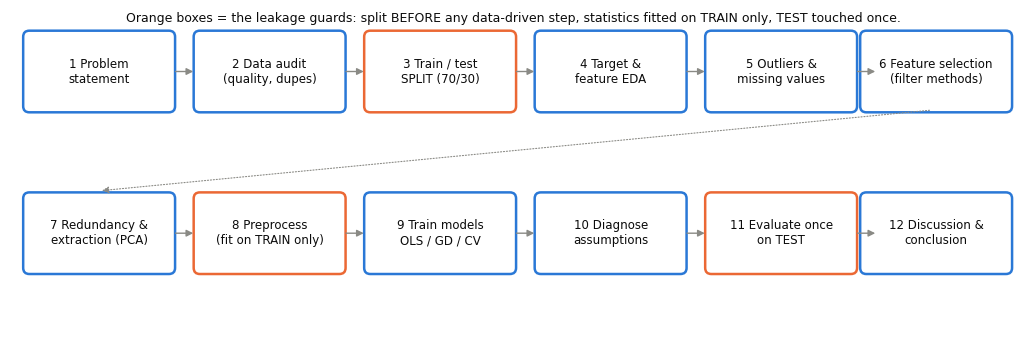

In [3]:
# ---------- §0 ภาพรวม ML flow (rubric ข้อ 20) ----------
fig, ax = plt.subplots(figsize=(13, 4.3)); ax.set_xlim(0, 13); ax.set_ylim(0, 4.3); ax.axis('off')
steps = [('1 Problem\nstatement', 0.2, 3.0, BLUE), ('2 Data audit\n(quality, dupes)', 2.4, 3.0, BLUE),
         ('3 Train / test\nSPLIT (70/30)', 4.6, 3.0, ORANGE), ('4 Target &\nfeature EDA', 6.8, 3.0, BLUE),
         ('5 Outliers &\nmissing values', 9.0, 3.0, BLUE), ('6 Feature selection\n(filter methods)', 11.0, 3.0, BLUE),
         ('7 Redundancy &\nextraction (PCA)', 0.2, 0.9, BLUE), ('8 Preprocess\n(fit on TRAIN only)', 2.4, 0.9, ORANGE),
         ('9 Train models\nOLS / GD / CV', 4.6, 0.9, BLUE), ('10 Diagnose\nassumptions', 6.8, 0.9, BLUE),
         ('11 Evaluate once\non TEST', 9.0, 0.9, ORANGE), ('12 Discussion &\nconclusion', 11.0, 0.9, BLUE)]
for t, x, y, c in steps:
    ax.add_patch(FancyBboxPatch((x, y), 1.9, 1.0, boxstyle='round,pad=0.03,rounding_size=0.08', fc='white', ec=c, lw=1.8))
    ax.text(x + 0.95, y + 0.5, t, ha='center', va='center', fontsize=8.5, color=INK)
for i in range(5): ax.add_patch(FancyArrowPatch((2.1 + 2.2*i, 3.5), (2.4 + 2.2*i, 3.5), arrowstyle='-|>', mutation_scale=10, color=GREY))
ax.add_patch(FancyArrowPatch((11.9, 3.0), (1.15, 1.95), connectionstyle='arc3,rad=0.0', arrowstyle='-|>', mutation_scale=10, color=GREY, lw=0.8, ls=':'))
for i in range(5): ax.add_patch(FancyArrowPatch((2.1 + 2.2*i, 1.4), (2.4 + 2.2*i, 1.4), arrowstyle='-|>', mutation_scale=10, color=GREY))
ax.text(6.5, 4.15, 'Orange boxes = the leakage guards: split BEFORE any data-driven step, statistics fitted on TRAIN only, TEST touched once.',
        ha='center', fontsize=9, color=INK)
plt.show()

# 1 · Problem statement  *(rubric 1)*

### 1.1 คำอธิบายข้อมูล
**Paddy dataset** (UCI Machine Learning Repository, DOI 10.24432/C55W3J, CC BY 4.0) อธิบายการเพาะปลูกข้าว ได้แก่ ขนาดแปลง, agri-block, สายพันธุ์, ชนิดดิน, ชนิดแปลงกล้า, อัตราเมล็ดพันธุ์, วัสดุเตรียมดิน, ปุ๋ย / สารกำจัดวัชพืช / สารกำจัดศัตรูพืชที่ใส่ในวันที่กำหนด, ปริมาณน้ำฝนและตัวแปร "AI" ในแต่ละช่วงการเจริญเติบโต, อุณหภูมิ / ความเร็วลม / ความชื้นในแต่ละช่วง 30 วัน, จำนวน `Trash` และ `Paddy yield` สุดท้าย UCI ระบุว่ามี 2,790 instances × 45 columns และ *ไม่มี missing values* ชื่อ agri-block (Cuddalore, Panruti, Kallakurichi …) ดูเหมือนจะเป็นเขต (district) ในรัฐ Tamil Nadu ประเทศอินเดีย

## คำอธิบายตัวแปร (Variable Description)
| ลำดับ | ชื่อ Feature | ชนิด | คำนิยาม |
|---|---|---|---|
| 1 | `Hectares` | Numerical (Integer) | ขนาดแปลงที่เพาะปลูก หน่วยเป็นเฮกตาร์ |
| 2 | `Agriblock` | Categorical | เขตเกษตร (agricultural block) / อำเภอที่แปลงตั้งอยู่ |
| 3 | `Variety` | Categorical | สายพันธุ์ข้าวที่ปลูก เช่น CO_43, ponmani, delux ponni |
| 4 | `Soil Types` | Categorical | ชนิดดินของแปลง เช่น ดินตะกอน (alluvial) หรือดินเหนียว (clay) |
| 5 | `Seedrate (in Kg)` | Numerical (Integer) | ปริมาณเมล็ดพันธุ์ที่ใช้ปลูก หน่วยเป็นกิโลกรัม |
| 6 | `LP_Mainfield (in Tonnes)` | Numerical (Continuous) | ปริมาณวัสดุ/ปุ๋ยคอกสำหรับเตรียมดินที่ใช้ในแปลงหลัก หน่วยเป็นตัน; แหล่งข้อมูลไม่ระบุชนิดวัสดุที่แน่ชัด |
| 7 | `Nursery` | Categorical | ชนิด/วิธีเตรียมแปลงกล้า เช่น แบบแห้ง (dry) หรือแบบเปียก (wet) |
| 8 | `Nursery area (Cents)` | Numerical (Integer) | พื้นที่แปลงกล้า หน่วยเป็น cents |
| 9 | `LP_nurseryarea (in Tonnes)` | Numerical (Integer) | ปริมาณปุ๋ยคอกที่ใช้เตรียมพื้นที่แปลงกล้า หน่วยเป็นตัน |
| 10 | `DAP_20days` | Numerical (Integer) | ปริมาณปุ๋ย DAP ที่ใส่ราววันที่ 20 |
| 11 | `Weed28D_thiobencarb` | Numerical | ปริมาณสารกำจัดวัชพืช thiobencarb ที่ใส่ราววันที่ 28 |
| 12 | `Urea_40Days` | Numerical (Continuous) | ปริมาณปุ๋ยยูเรียที่ใส่ราววันที่ 40 |
| 13 | `Potassh_50Days` | Numerical (Continuous) | ปริมาณปุ๋ยโพแทช/โพแทสเซียมที่ใส่ราววันที่ 50 |
| 14 | `Micronutrients_70Days` | Numerical | ปริมาณธาตุอาหารรอง (micronutrients) ที่ใส่ราววันที่ 70 |
| 15 | `Pest_60Day (in ml)` | Numerical | ปริมาณสารกำจัดศัตรูพืชที่ใส่ราววันที่ 60 หน่วยเป็นมิลลิลิตร |
| 16 | `30DRain (in mm)` | Numerical (Continuous) | ปริมาณน้ำฝนในช่วงราว 30 วันแรก หน่วยเป็นมิลลิเมตร |
| 17 | `30DAI (in mm)` | Numerical (Continuous) | ตัวแปร "AI" ในช่วงราว 30 วันแรก หน่วยเป็นมิลลิเมตร; แหล่งข้อมูลไม่ได้นิยามชัดเจนว่า AI คืออะไร |
| 18 | `30_50DRain (in mm)` | Numerical (Continuous) | ปริมาณน้ำฝนในช่วงราววันที่ 30-50 หน่วยเป็นมิลลิเมตร |
| 19 | `30_50DAI (in mm)` | Numerical (Continuous) | ตัวแปร "AI" ในช่วงราววันที่ 30-50 หน่วยเป็นมิลลิเมตร; แหล่งข้อมูลไม่ได้นิยาม AI ชัดเจน |
| 20 | `51_70DRain (in mm)` | Numerical (Continuous) | ปริมาณน้ำฝนในช่วงวันที่ 51-70 หน่วยเป็นมิลลิเมตร |
| 21 | `51_70AI (in mm)` | Numerical (Continuous) | ตัวแปร "AI" ในช่วงวันที่ 51-70 หน่วยเป็นมิลลิเมตร; แหล่งข้อมูลไม่ได้นิยาม AI ชัดเจน |
| 22 | `71_105DRain (in mm)` | Numerical (Continuous) | ปริมาณน้ำฝนในช่วงวันที่ 71-105 หน่วยเป็นมิลลิเมตร |
| 23 | `71_105DAI (in mm)` | Numerical (Continuous) | ตัวแปร "AI" ในช่วงวันที่ 71-105 หน่วยเป็นมิลลิเมตร; แหล่งข้อมูลไม่ได้นิยาม AI ชัดเจน |
| 24 | `Min temp_D1_D30` | Numerical (Continuous) | อุณหภูมิต่ำสุดในช่วงวันที่ 1-30 |
| 25 | `Max temp_D1_D30` | Numerical (Continuous) | อุณหภูมิสูงสุดในช่วงวันที่ 1-30 |
| 26 | `Min temp_D31_D60` | Numerical (Continuous) | อุณหภูมิต่ำสุดในช่วงวันที่ 31-60 |
| 27 | `Max temp_D31_D60` | Numerical (Continuous) | อุณหภูมิสูงสุดในช่วงวันที่ 31-60 |
| 28 | `Min temp_D61_D90` | Numerical (Continuous) | อุณหภูมิต่ำสุดในช่วงวันที่ 61-90 |
| 29 | `Max temp_D61_D90` | Numerical (Continuous) | อุณหภูมิสูงสุดในช่วงวันที่ 61-90 |
| 30 | `Min temp_D91_D120` | Numerical (Continuous) | อุณหภูมิต่ำสุดในช่วงวันที่ 91-120 |
| 31 | `Max temp_D91_D120` | Numerical (Continuous) | อุณหภูมิสูงสุดในช่วงวันที่ 91-120 |
| 32 | `Inst Wind Speed_D1_D30 (in Knots)` | Numerical | ความเร็วลมขณะหนึ่ง (instantaneous) ที่บันทึกในช่วงวันที่ 1-30 หน่วยเป็น knots |
| 33 | `Inst Wind Speed_D31_D60 (in Knots)` | Numerical | ความเร็วลมขณะหนึ่งที่บันทึกในช่วงวันที่ 31-60 หน่วยเป็น knots |
| 34 | `Inst Wind Speed_D61_D90 (in Knots)` | Numerical | ความเร็วลมขณะหนึ่งที่บันทึกในช่วงวันที่ 61-90 หน่วยเป็น knots |
| 35 | `Inst Wind Speed_D91_D120 (in Knots)` | Numerical | ความเร็วลมขณะหนึ่งที่บันทึกในช่วงวันที่ 91-120 หน่วยเป็น knots |
| 36 | `Wind Direction_D1_D30` | Categorical | ทิศทางลมในช่วงวันที่ 1-30 เช่น SW, NW, ENE, W |
| 37 | `Wind Direction_D31_D60` | Categorical | ทิศทางลมในช่วงวันที่ 31-60 |
| 38 | `Wind Direction_D61_D90` | Categorical | ทิศทางลมในช่วงวันที่ 61-90 |
| 39 | `Wind Direction_D91_D120` | Categorical | ทิศทางลมในช่วงวันที่ 91-120 |
| 40 | `Relative Humidity_D1_D30` | Numerical (Continuous) | ความชื้นสัมพัทธ์ในช่วงวันที่ 1-30 |
| 41 | `Relative Humidity_D31_D60` | Numerical (Continuous) | ความชื้นสัมพัทธ์ในช่วงวันที่ 31-60 |
| 42 | `Relative Humidity_D61_D90` | Numerical (Continuous) | ความชื้นสัมพัทธ์ในช่วงวันที่ 61-90 |
| 43 | `Relative Humidity_D91_D120` | Numerical (Continuous) | ความชื้นสัมพัทธ์ในช่วงวันที่ 91-120 |
| 44 | `Trash (in bundles)` | Numerical (Integer) | ปริมาณของตัวแปรที่ dataset เรียกว่า "Trash" วัดเป็นมัด (bundles); แหล่งข้อมูลไม่ได้อธิบายชัดเจนว่าหมายถึงวัสดุ / ส่วนใดของต้นพืช |
| 45 | `Paddy yield (in Kg)` | Numerical (Integer) | ผลผลิตข้าวเปลือกรวม หน่วยเป็นกิโลกรัม |

### 1.2 การนิยามปัญหา
| หัวข้อ | คำนิยาม |
|---|---|
| **ปัญหาทั่วไป** | เกษตรกร / ผู้วางแผนการเกษตรอยากรู้ว่า *แปลงนาแปลงหนึ่งจะให้ผลผลิตข้าวกี่กิโลกรัม* จากสิ่งที่ทราบเกี่ยวกับแปลง วิธีเพาะปลูก และสภาพอากาศที่แปลงนั้นเจอ เพื่อวางแผนการเก็บเกี่ยว การจัดเก็บ และการขาย |
| **ปัญหาเชิง ML** | **supervised learning, regression** (target เป็นจำนวนจริงแบบต่อเนื่อง) เรียนรู้ $f:\mathbf{x}\rightarrow \hat y$ ด้วย **linear regression** (ข้อกำหนดของ HW1, Ch01) โดย minimise ผลรวมกำลังสองของ residuals $\lVert X\mathbf a-\mathbf y\rVert_2^2$ แล้วประเมินบนข้อมูลที่โมเดลไม่เคยเห็น (R², RMSE, MAE, MAPE) |
| **Target variable** | `Paddy yield(in Kg)` (regression target ที่ UCI แนะนำ; เป็นผลผลิตรวมต่อแปลง หน่วยเป็น kg) มุมมอง *ที่แปลงมา* คือ **yield ต่อเฮกตาร์** = yield / Hectares จะถูกใช้ภายหลังเพียงเพื่อเป็นเครื่องมือวินิจฉัย (diagnostic) เท่านั้น — ไม่เคยถูกทำนาย และไม่เคยเป็น predictor — โดยจะอธิบายเหตุผลแยกต่างหากตั้งแต่ §4 |
| **Predictors (candidate features)** | คอลัมน์ที่เหลืออีก 44 คอลัมน์ *หักออก* ด้วยคอลัมน์ที่ถูกตัดจาก leakage audit ด้านล่าง |
| **Sample** | 1 แถว = บันทึกการเพาะปลูก 1 ฤดูของแปลงนา 1 แปลง (1–6 ha) ใน 1 ใน 6 agri-blocks |

### 1.3 Assumptions ของการตั้งปัญหา (แต่ละข้อจะถูกทดสอบหรืออภิปรายภายหลัง)
| # | Assumption | ทำไมจึงจำเป็น | ตรวจสอบใน |
|---|---|---|---|
| A1 | **เวลาที่ทำนาย = ปลายวงจรการเจริญเติบโต ~120 วัน ก่อนชั่งผลผลิตพอดี** ณ เวลานั้นปัจจัยการผลิตทั้งหมดและสภาพอากาศทั้ง 4 ช่วงเป็นที่ทราบแล้ว | กำหนดว่าคอลัมน์ใด *มีให้ใช้* ตอนใช้งานโมเดล; คอลัมน์ที่ยังไม่มีในเวลานั้นคือ leakage | §1.4 |
| A2 | แต่ละแถวเป็นแปลงอิสระต่อกัน (ไม่มี plot ID, วันที่ หรือปี จึงตรวจสอบ repeated measures หรือลำดับเวลาไม่ได้) | OLS inference และ K-fold CV สมมติว่า observations เป็นอิสระต่อกัน | §14.5 (Durbin–Watson), §3 |
| A3 | คอลัมน์สภาพอากาศเป็นค่าสรุประดับ block ไม่ใช่ค่าที่วัดรายแปลง | ไม่เช่นนั้นสภาพอากาศจะเป็น feature ระดับแปลง | §10 (ยืนยันแล้ว) |
| A4 | ความหมายของ `AI` ไม่มีเอกสารระบุ จึงถือเป็นตัวแปรในฤดูที่ไม่ทราบความหมายแต่มีให้ใช้ จนกว่าข้อมูลจะบอกเราเพิ่ม | ไม่สามารถตัดออกหรือเก็บไว้โดยอาศัยเอกสารอย่างเดียว | §10 (ยืนยันแล้ว) |
| A5 | ถือว่าแต่ละแถวเป็นตัวอย่างของแปลงจริง แต่ความสม่ำเสมออย่างมาก (ปัจจัยการผลิตเป็นสัดส่วนตรงกับพื้นที่เป๊ะ) ที่พบภายหลังบ่งชี้ว่าน่าจะมีการทำตารางปริมาณแนะนำต่อเฮกตาร์ไว้ ดังนั้น **ข้อสรุปอธิบาย dataset นี้** ไม่จำเป็นต้องเป็นฟาร์มจริง | จำกัดขอบเขตการ generalise ของผลลัพธ์ | §17 |

### 1.4 Data-leakage audit — predictor ใดใช้ได้ ใดใช้ไม่ได้ *(ข้อควรระวังที่ 1)*
**Target leakage** = predictor ที่มีข้อมูลเกี่ยวกับ target ซึ่ง **จะไม่มีให้ใช้ตอนใช้งานจริง** ทำให้คะแนน test สูงเกินจริงแต่ล้มเหลวในทางปฏิบัติ การ audit ด้านล่างทำ *ก่อน* การสร้างโมเดล โดยใช้เพียงเหตุผลเชิง domain (A1) ส่วนหลักฐานเชิงประจักษ์จะเพิ่มใน §8, §10 และ §15

| คอลัมน์ | การตัดสินใจ | เหตุผล |
|---|---|---|
| `Paddy yield(in Kg)` | **target** | — |
| **`Trash(in bundles)`** | **ตัดออก (leakage)** | "Trash" คือผลพลอยได้จากการนวดข้าว (มัดฟาง / แกลบ) ที่นับ **ตอนเก็บเกี่ยว** คือช่วงเวลาเดียวกับที่ชั่ง yield มันไม่มีอยู่ ณ เวลาทำนาย (A1) การใช้มันเหมือนการทำนายผลลัพธ์จากผลพวงอีกอย่างของเหตุการณ์เดียวกัน ตรวจสอบเชิงประจักษ์: §8, §15 |
| `Hectares`, `Agriblock`, `Variety`, `Soil Types`, `Nursery` | candidate | กำหนดไว้ก่อนปลูก |
| `Seedrate`, `LP_Mainfield`, `Nursery area`, `LP_nurseryarea`, `DAP_20days`, `Weed28D_thiobencarb`, `Urea_40Days`, `Potassh_50Days`, `Micronutrients_70Days`, `Pest_60Day` | candidate | เป็นการตัดสินใจ *ระหว่าง* ฤดูปลูก ทั้งหมดก่อนเก็บเกี่ยว (A1) ความซ้ำซ้อนที่เป็นไปได้จะพิจารณาใน §10 |
| `30DRain … 71_105DRain`, `*AI`, อุณหภูมิ, ความเร็ว / ทิศทางลม, ความชื้น (D1–D120) | candidate **ภายใต้ A1 เท่านั้น** | สภาพอากาศของช่วง *ท้าย* (D91–D120, วันที่ 71–105) จะทราบก็ต่อเมื่อใกล้เก็บเกี่ยว มัน **ไม่ใช่ leakage สำหรับการประมาณ ณ ปลายฤดู** (สภาพอากาศเป็นสาเหตุของ yield ไม่ใช่ผลพวง) แต่จะไม่มีให้ใช้สำหรับการพยากรณ์ต้นฤดู หากเป้าหมายคือการพยากรณ์ตอนปลูก จะต้องตัดสภาพอากาศและปัจจัยระหว่างฤดูออกทั้งหมด |
| yield ต่อเฮกตาร์ (derived) | **ไม่เป็น predictor เด็ดขาด** | สร้างขึ้นจาก target ใช้เป็น target ทางเลือกเท่านั้น |

**เส้นทาง leakage อื่น ๆ ที่ถูกควบคุมในรายงานนี้**
1. *Pre-processing leakage* — scaler, imputer, PCA, encoder และทุกค่าสถิติที่ใช้คัดเลือก ถูก **fit บนแถว training เท่านั้น** (§3, §12)
2. *Duplicate leakage* — แถวที่เหมือนกันเป๊ะซึ่งตกอยู่ทั้งใน train และ test ถูกลบ **ก่อน** การ split (§2–§3)
3. *Selection leakage* — ค่าสถิติสำหรับ feature selection (correlation, ANOVA, MI, chi-square) คำนวณบน **training set เท่านั้น** ส่วน test set ถูกเปิดครั้งเดียวตอนท้าย §14.6 แสดงเป็นตัวเลขว่าจะเกิดความ optimistic มากแค่ไหนหากละเมิดกฎนี้ (สไลด์ Ch02: *feature selection ต้องอยู่ภายใน CV loop*)
4. *Group leakage* — สภาพอากาศเหมือนกันทุกแปลงใน agri-block เดียวกัน การ split แบบสุ่มจึงทำให้โมเดล "เห็น" สภาพอากาศของ block นั้นตอน train §14.4 จึงรายงานคะแนนแบบ **leave-one-agri-block-out** ด้วย

# 2 · การโหลดข้อมูลและการตรวจสอบคุณภาพข้อมูล  *(Ch01: Data Quality, Data Cleaning, Data Representation)*
Ch01 ระบุมิติคุณภาพ 6 ด้าน — **Accurate, Complete, Consistent, Valid, Uniform, Unique** แต่ละด้านถูกตรวจสอบด้านล่าง

In [4]:
DATA_PATH = Path('~/paddy/dataset/paddydataset.csv').expanduser()
raw = pd.read_csv(DATA_PATH, encoding='latin')
print('Shape as read:', raw.shape)
bad_names = [repr(c) for c in raw.columns if c != c.strip()]
print('Column names with stray whitespace:', bad_names)
raw.columns = raw.columns.str.strip()          # 'Hectares ' -> 'Hectares' (a Consistency defect: would break df['Hectares'])
raw.head(5)

Shape as read: (2789, 45)
Column names with stray whitespace: ["'Hectares '"]


,Hectares,Agriblock,Variety,Soil Types,Seedrate(in Kg),LP_Mainfield(in Tonnes),Nursery,Nursery area (Cents),LP_nurseryarea(in Tonnes),DAP_20days,Weed28D_thiobencarb,Urea_40Days,Potassh_50Days,Micronutrients_70Days,Pest_60Day(in ml),30DRain( in mm),30DAI(in mm),30_50DRain( in mm),30_50DAI(in mm),51_70DRain(in mm),51_70AI(in mm),71_105DRain(in mm),71_105DAI(in mm),Min temp_D1_D30,Max temp_D1_D30,Min temp_D31_D60,Max temp_D31_D60,Min temp_D61_D90,Max temp_D61_D90,Min temp_D91_D120,Max temp_D91_D120,Inst Wind Speed_D1_D30(in Knots),Inst Wind Speed_D31_D60(in Knots),Inst Wind Speed_D61_D90(in Knots),Inst Wind Speed_D91_D120(in Knots),Wind Direction_D1_D30,Wind Direction_D31_D60,Wind Direction_D61_D90,Wind Direction_D91_D120,Relative Humidity_D1_D30,Relative Humidity_D31_D60,Relative Humidity_D61_D90,Relative Humidity_D91_D120,Trash(in bundles),Paddy yield(in Kg)
0,6,Cuddalore,CO_43,alluvial,150,75,dry,120,6,240,12,162.78,62.28,90,3600,19.6,20.4,187.2,270.8,167,250,61,64,18.5,34,16,30,15.5,31,16,33,4,10,8,10,SW,W,NNW,WSW,72,78,88,85,540,35028
1,6,Kurinjipadi,ponmani,clay,150,75,wet,120,6,240,12,162.78,62.28,90,3600,19.6,20.4,187.2,270.8,167,250,61,64,19.5,34,18.5,35,17,32.5,16,30.5,10,4,10,6,NW,S,SE,SSE,64.6,85,84,87,600,35412
2,6,Panruti,delux ponni,alluvial,150,75,dry,120,6,240,12,162.78,62.28,90,3600,18.5,21.5,185.2,272.8,165.3,251.7,60,65,20,35,18,30,17.5,33.5,18,33,4,12,4,12,ENE,NE,NNE,W,85,96,84,79,600,36300
3,6,Kallakurichi,CO_43,clay,150,75,wet,120,6,240,12,162.78,62.28,90,3600,18.5,21.5,185.2,272.8,165.3,251.7,60,65,19,33,17,32,16.5,31.5,15.5,32.5,8,6,8,6,W,WNW,SE,S,88.5,95,81,84,540,35016
4,6,Sankarapuram,ponmani,alluvial,150,75,dry,120,6,240,12,162.78,62.28,90,3600,18.1,21.9,185.6,272.4,166.1,250.9,60.2,64.8,20.5,32,17.5,28,18,34,16.5,35,10,12,10,12,SSE,W,SW,NW,72.7,91,83,81,600,34044


In [5]:
# ---- กลุ่มคอลัมน์ที่ใช้ทุกที่ (ตรวจสอบชื่อกับไฟล์จริงแล้ว) ----
Y = 'Paddy yield(in Kg)'
PER = ['D1_D30', 'D31_D60', 'D61_D90', 'D91_D120']
CAT = ['Agriblock', 'Variety', 'Soil Types', 'Nursery'] + [f'Wind Direction_{p}' for p in PER]
INPUTS = ['Seedrate(in Kg)', 'LP_Mainfield(in Tonnes)', 'Nursery area (Cents)', 'LP_nurseryarea(in Tonnes)', 'DAP_20days',
          'Weed28D_thiobencarb', 'Urea_40Days', 'Potassh_50Days', 'Micronutrients_70Days', 'Pest_60Day(in ml)']
RAIN = ['30DRain( in mm)', '30_50DRain( in mm)', '51_70DRain(in mm)', '71_105DRain(in mm)']
AI   = ['30DAI(in mm)', '30_50DAI(in mm)', '51_70AI(in mm)', '71_105DAI(in mm)']
TMIN = [f'Min temp_{p}' for p in PER]; TMAX = [f'Max temp_{p}' for p in PER]
WIND = [f'Inst Wind Speed_{p}(in Knots)' for p in PER]; RH = [f'Relative Humidity_{p}' for p in PER]
TRASH = 'Trash(in bundles)'
NUM = ['Hectares'] + INPUTS + RAIN + AI + TMIN + TMAX + WIND + RH + [TRASH]     # 36 numeric predictors (incl. Trash, kept for the audit only)
assert set(NUM + CAT + [Y]) == set(raw.columns) and len(NUM + CAT + [Y]) == raw.shape[1] == 45
print('numeric predictors:', len(NUM), '| categorical predictors:', len(CAT), '| target: 1')

numeric predictors: 36 | categorical predictors: 8 | target: 1


In [6]:
# ---- data-quality audit 6 มิติ (Ch01 "Data Quality") ----
checks = []
# Complete (ความครบถ้วน)
checks.append(('Complete', 'missing cells', int(raw.isna().sum().sum()), 'none' if raw.isna().sum().sum() == 0 else 'ACTION'))
# Consistent: ชนิดข้อมูลสอดคล้องกัน (Ch01: ค่าใน attribute เดียวต้องมี datatype เดียว)
obj_cols = raw.select_dtypes('object').columns.tolist()
mixed = [c for c in NUM + [Y] if not pd.api.types.is_numeric_dtype(raw[c])]
checks.append(('Consistent', 'numeric columns stored as text', len(mixed), 'ok' if not mixed else 'ACTION'))
checks.append(('Consistent', 'text columns = the 8 expected categorical', f'{len(obj_cols)} (match={set(obj_cols)==set(CAT)})', 'ok'))
lab = sum(raw[c].nunique() != raw[c].str.strip().str.lower().nunique() for c in CAT)
checks.append(('Consistent', 'categorical columns with case/space variants of one label', lab, 'ok' if lab == 0 else 'ACTION'))
# Valid: ถูกต้องตามกฎ (business rules / ข้อจำกัดทางกายภาพ)
tvio = sum((raw[f'Min temp_{p}'] > raw[f'Max temp_{p}']).sum() for p in PER)
checks.append(('Valid', 'rows with Min temp > Max temp', int(tvio), 'ok' if tvio == 0 else 'ACTION'))
checks.append(('Valid', 'relative humidity outside 0-100 %', int(((raw[RH] < 0) | (raw[RH] > 100)).sum().sum()), 'ok'))
neg = int((raw[[c for c in NUM if c not in TMIN + TMAX]] < 0).sum().sum())
checks.append(('Valid', 'negative amounts / areas / rain', neg, 'ok' if neg == 0 else 'ACTION'))
checks.append(('Valid', 'target <= 0', int((raw[Y] <= 0).sum()), 'ok'))
# Accurate / Uniform : ตรวจกับ ground truth ไม่ได้ -> ใช้การตรวจช่วงค่า + การระบุหน่วยแทน
checks.append(('Accurate', 'target range (kg)', f'{raw[Y].min():,.0f} - {raw[Y].max():,.0f}', 'plausible; no external truth to compare'))
checks.append(('Uniform', 'units', 'stated in column names (Kg, Tonnes, mm, Knots, Cents)', 'one unit per column; cannot verify further'))
# Unique (ไม่ซ้ำ)
ndup = int(raw.duplicated().sum())
checks.append(('Unique', 'exact duplicate rows (all 45 columns)', f'{ndup}  ({ndup/len(raw):.1%})', 'ACTION -> remove'))
pd.DataFrame(checks, columns=['Dimension', 'Check', 'Result', 'Verdict'])

,Dimension,Check,Result,Verdict
0,Complete,missing cells,0,none
1,Consistent,numeric columns stored as text,0,ok
2,Consistent,text columns = the 8 expected categorical,8 (match=True),ok
3,Consistent,categorical columns with case/space variants o...,0,ok
4,Valid,rows with Min temp > Max temp,0,ok
5,Valid,relative humidity outside 0-100 %,0,ok
6,Valid,negative amounts / areas / rain,0,ok
7,Valid,target <= 0,0,ok
8,Accurate,target range (kg),"5,410 - 38,814",plausible; no external truth to compare
9,Uniform,units,"stated in column names (Kg, Tonnes, mm, Knots,...",one unit per column; cannot verify further


**การอ่านผล audit** ข้อมูลครบถ้วนและถูกต้องภายในตัวเอง พบข้อบกพร่อง 2 อย่าง: ช่องว่างเกินในชื่อคอลัมน์ `'Hectares '` (แก้ไปแล้วด้านบน) และ **แถวที่ซ้ำกันเป๊ะ (exact duplicate rows)** แถวซ้ำต้องมีการตัดสินใจ ซึ่งจะทำใน cell ถัดไปพร้อมหลักฐาน

In [7]:
dup_rows = raw[raw.duplicated(keep=False)]
grp = dup_rows.groupby(list(raw.columns)).size()
print(f'rows involved in a duplicate group: {len(dup_rows)}  |  distinct duplicated records: {grp.size}')
print('group sizes (record appears k times):', grp.value_counts().sort_index().to_dict())
feat_cols = [c for c in raw.columns if c != Y]
g = raw.groupby(feat_cols)[Y].agg(n='count', distinct_yields='nunique')
print(f'\nDistinct feature vectors: {len(g)} for {len(raw)} rows -> average {g.n.mean():.1f} rows share one feature vector')
print(f'...but they carry on average {g.distinct_yields.mean():.1f} distinct yields, so the target is NOT a function of these features (irreducible noise).')

rows involved in a duplicate group: 812  |  distinct duplicated records: 361
group sizes (record appears k times): {2: 293, 3: 50, 4: 14, 5: 4}

Distinct feature vectors: 411 for 2789 rows -> average 6.8 rows share one feature vector
...but they carry on average 5.7 distinct yields, so the target is NOT a function of these features (irreducible noise).


**การตัดสินใจ — ลบ exact duplicates (เก็บตัวแรกไว้)**
* *เหตุผลที่ 1 (Ch01, "Unique"):* record หนึ่งควรปรากฏครั้งเดียว record ที่ซ้ำทำให้บางแปลงมีน้ำหนักเกินใน least-squares sum
* *เหตุผลที่ 2 (leakage):* หาก duplicate ตัวหนึ่งตกใน test set และคู่แฝดของมันอยู่ใน training set โมเดลจะถูกทดสอบด้วยสิ่งที่มันเคยเห็นแล้ว (วัดเป็นตัวเลขใน §3)
* *Assumption / ความเสี่ยง:* ไฟล์นี้ไม่มี plot ID ดังนั้นแถวที่เหมือนกันอาจเป็นคนละแปลงที่บังเอิญมีค่าเหมือนกันทุกช่องก็ได้ ค่า yield มีเพียง 477 ค่าที่แตกต่างกันจาก 2,789 แถว ความบังเอิญจึงเป็นไปได้ และอาจมีแปลงจริงบางแปลงถูกลบทิ้ง เรายอมรับความเสี่ยงนี้เพราะทางเลือกอีกทาง (leakage) แย่กว่า และ §16 ยืนยันว่าข้อสรุปไม่ได้ขึ้นกับการเลือกนี้

In [8]:
df = raw.drop_duplicates().copy()                # keeps the original row index (used later for the order-based independence check)
print(f'rows: {len(raw)} -> {len(df)}  (removed {len(raw)-len(df)})')

rows: 2789 -> 2338  (removed 451)


### 2.1 Data representation และ scale types  *(Ch01: data matrix, quantitative / qualitative, nominal / ordinal / interval / ratio)*
Dataset นี้คือ **data matrix** $D\in\mathbb{R}^{n\times d}$ โดย $n$ = จำนวนแปลง (แถว = instances $\mathbf{x}_i$) และ $d$ = 44 attributes (คอลัมน์ $X_j$) บวก target ตารางด้านล่างจำแนกทุก attribute กฎคร่าว ๆ ของ Guideline — *"เป็น categorical ถ้ามีค่าไม่ซ้ำ < 20 ค่า และค่ามีการซ้ำกัน"* — ถูกใช้ควบคู่กับความหมายเชิง domain เพราะ **dataset นี้หยาบผิดปกติ**: คอลัมน์ numeric ส่วนใหญ่มีค่าที่แตกต่างกันเพียง 3–6 ค่า

In [9]:
def kind_of(c):
    if c in CAT: return ('Qualitative', 'Categorical', 'Nominal (compass direction treated as nominal)' if 'Wind Dir' in c else 'Nominal')
    if c in TMIN + TMAX: return ('Quantitative', 'Continuous', 'Interval (degC: no true zero)')
    if c in RH: return ('Quantitative', 'Continuous', 'Ratio (% of saturation)')
    if c in RAIN + AI + WIND: return ('Quantitative', 'Continuous', 'Ratio')
    if c in ['Hectares', TRASH, 'Seedrate(in Kg)', 'Nursery area (Cents)', 'LP_nurseryarea(in Tonnes)', 'DAP_20days', Y]:
        return ('Quantitative', 'Discrete (integer count / amount)', 'Ratio')
    return ('Quantitative', 'Continuous', 'Ratio')
rep = pd.DataFrame({c: kind_of(c) for c in df.columns}, index=['Type', 'Discrete/Continuous', 'Scale']).T
rep['n_unique'] = df.nunique(); rep['<20 unique?'] = rep.n_unique < 20
print(rep.groupby(['Type', 'Discrete/Continuous', 'Scale']).size().to_string())
print(f"\nQuantitative columns (incl. the target) with < 20 unique values: {int(((rep.Type=='Quantitative') & rep['<20 unique?']).sum())} of {int((rep.Type=='Quantitative').sum())} "
      "-> the '<20 unique = categorical' heuristic is NOT applied to them: they are measurements (order and distance matter).")

Type          Discrete/Continuous                Scale                                         
Qualitative   Categorical                        Nominal                                            4
                                                 Nominal (compass direction treated as nominal)     4
Quantitative  Continuous                         Interval (degC: no true zero)                      8
                                                 Ratio                                             18
                                                 Ratio (% of saturation)                            4
              Discrete (integer count / amount)  Ratio                                              7

Quantitative columns (incl. the target) with < 20 unique values: 36 of 37 -> the '<20 unique = categorical' heuristic is NOT applied to them: they are measurements (order and distance matter).


**ผลกระทบต่อการวิเคราะห์ (เหตุผลของการเลือกในภายหลัง)**

| Scale type | ตัวอย่างคอลัมน์ในที่นี้ | คุณสมบัติ | ผลต่อการวิเคราะห์นี้ |
|---|---|---|---|
| **Nominal** | block, variety, soil, nursery, ทิศทางลม | ไม่มีลำดับ | ต้องใช้ **one-hot encoding** *ไม่ใช่* integer codes (Ch01: integer codes จะยัดเยียดลำดับ/ระยะห่างปลอมให้โมเดลเชิงเส้น) |
| **Ordinal** | ไม่มีในชุดนี้ | — | **ไม่จำเป็นต้องใช้ ordinal encoding** — dataset นี้ไม่มี attribute ที่เป็น ordinal |
| **Interval** | อุณหภูมิ (°C) | ไม่มีศูนย์แท้ | อัตราส่วนของอุณหภูมิไม่มีความหมาย มีแต่ผลต่างที่มีความหมาย; **standardisation** (ไม่ใช่ transform ที่อิงอัตราส่วนอย่าง log) จึงเหมาะสม |
| **Ratio** | พื้นที่, ปริมาณ, น้ำฝน | มีศูนย์แท้ | transform แบบ **log/cube-root/Box-Cox** มีความหมายเมื่อข้อมูล skew |

# 3 · การแบ่ง Train / Test — *ก่อนการวิเคราะห์ที่อิงข้อมูลใด ๆ*  *(leakage guard, Ch01 cross-validation)*
**ทำไมต้องตอนนี้?** ทุกการตัดสินใจถัดจากนี้ (outlier fences, ค่า imputation, transform, correlations, ANOVA, PCA loadings, scaling) ล้วน *เรียนรู้จากข้อมูล* ถ้าแถว test มีส่วนร่วมในการตัดสินใจเหล่านั้นแม้เพียงอย่างเดียว คะแนน test จะสูงเกินจริง ข้อมูลจึงถูก split ตรงนี้ การสำรวจข้อมูลทั้งหมดใช้ **`train` เท่านั้น** และ `test` จะถูกเปิดครั้งเดียว (§15)

**วิธี:** สุ่ม split 70 % / 30 % (Ch01: "70 % training, 30 % testing"), `random_state=42`
**Assumptions:** แถวข้อมูลสลับสับเปลี่ยนกันได้ / เป็นอิสระ (A2); ขนาดตัวอย่างใหญ่พอที่ทั้งสองส่วนจะเป็นตัวแทนของทั้งหมด (ตรวจสอบด้านล่างด้วย Kolmogorov–Smirnov test บน target)

In [10]:
train, test = train_test_split(df, test_size=0.30, random_state=SEED)
print('train', train.shape, '| test', test.shape)
ks = stats.ks_2samp(train[Y], test[Y])
print(f'Two-sample KS test on the target, train vs test: D={ks.statistic:.4f}, p={ks.pvalue:.3f}  '
      f'-> {"no evidence the parts differ" if ks.pvalue > 0.05 else "parts differ!"}')
print('Hectares share (%):\n', pd.concat([train.Hectares.value_counts(normalize=True).sort_index().mul(100).rename('train'),
                                          test.Hectares.value_counts(normalize=True).sort_index().mul(100).rename('test')], axis=1).round(1).T.to_string())

train (1636, 45) | test (702, 45)
Two-sample KS test on the target, train vs test: D=0.0308, p=0.724  -> no evidence the parts differ
Hectares share (%):
 Hectares   1    2    3    4    5   6
train    8.9 14.5 16.9 22.7 28.5 8.5
test     8.3 17.1 12.7 23.1 31.2 7.7


In [11]:
# ---- ถ้าเก็บ duplicates ไว้จะ leak มากแค่ไหน? (seed เดิม, split ก่อนลบ duplicates) ----
rs_tr, rs_te = train_test_split(raw, test_size=0.30, random_state=SEED)
hit = rs_te.merge(rs_tr.drop_duplicates(), how='left', indicator=True)['_merge'].eq('both').mean()
print(f'If duplicates were kept, {hit:.1%} of TEST rows would have an exact copy (all 45 columns) in TRAIN.')
tw = test[feat_cols].merge(train[feat_cols].drop_duplicates(), how='left', indicator=True)['_merge'].eq('both').mean()
print(f'After de-duplication, {tw:.1%} of test rows still share their whole FEATURE vector with some training row '
      '(different yield) -> features are highly repetitive; see the leave-one-block-out check in §14.4.')

If duplicates were kept, 25.8% of TEST rows would have an exact copy (all 45 columns) in TRAIN.
After de-duplication, 96.2% of test rows still share their whole FEATURE vector with some training row (different yield) -> features are highly repetitive; see the leave-one-block-out check in §14.4.


**การอ่านผล** การ split เป็นตัวแทนที่ดี: การแจกแจงของ target แยกกันไม่ออกทางสถิติ (KS D = 0.031, p = 0.72) และสัดส่วน Hectares ก็ใกล้เคียงกัน (ผลต่างเล็กน้อย เช่น 3 ha: 16.9 % vs 12.7 % เป็นสิ่งที่คาดได้จากการสุ่ม) หากเก็บ duplicates ไว้ จะทำให้ **25.8 %** ของแถว test ถูก "ตอบจากความจำ" — นี่คือเหตุผลเชิงตัวเลขที่ต้องลบมันก่อน split ถึงแม้จะลบแล้ว **96.2 %** ของเวกเตอร์ feature ใน test ก็ยังมีคู่แฝดที่เหมือนกันเป๊ะอยู่ใน train (แต่ค่า yield ต่างกัน) ดังนั้นคะแนนจากการ split แบบสุ่มจึงห้ามตีความว่าเป็น "ประสิทธิภาพบน agri-block ใหม่" — เรื่องนี้จัดการใน §14.4

# 4 · การดูการแจกแจงของ target  *(rubric 2 · Guideline ขั้นที่ 2)*
**คำถาม (Guideline ขั้นที่ 2)** target **balanced** หรือไม่? **skewed** หรือไม่? ต้องจัดการ **outlier** หรือไม่? ("Balanced" สำหรับ regression target หมายถึง *ทุกช่วงของค่ามีจำนวนแถวมากพอให้เรียนรู้* ไม่ใช่ "จำนวน class เท่ากัน" แบบ classification)

**Assumptions ของเครื่องมือที่ใช้ด้านล่าง** Histogram / box-plot / Q-Q plot เป็นการบรรยายเชิงพรรณนา ไม่มี assumption ใด ๆ ส่วน skewness และ excess kurtosis เป็น moment statistics ซึ่งไวต่อค่าสุดขั้ว Shapiro–Wilk ทดสอบ H0: ตัวอย่างมาจากการแจกแจงปกติ ต้องการ observations ที่เป็นอิสระ และเมื่อ n ใหญ่มันจะ reject แม้การเบี่ยงเบนเพียงน้อยนิดที่ไม่มีนัยในทางปฏิบัติ — จึงต้องอ่านคู่กับ Q-Q plot เสมอ ห้ามอ่านเดี่ยว ๆ

**แผน** เริ่มจากดูปริมาณที่จะถูกโมเดลจริง ๆ ตั้งแต่ §14 เป็นต้นไป คือ raw yield หน่วย kg ก่อน ถ้ารูปทรงดูผิดปกติ ก็สืบหา *สาเหตุ* ด้วยคอลัมน์ที่มีอยู่ ก่อนจะตัดสินใจว่าต้องทำอะไร (ถ้าต้องทำ)

,Paddy yield (kg)
count,"1,636"
mean,"22,576.07"
std,"9,257.53"
min,"5,410"
25%,"16,389"
50%,"24,620"
75%,"31,035"
max,"38,814"
skewness,-0.3046
excess kurtosis,-1.0597


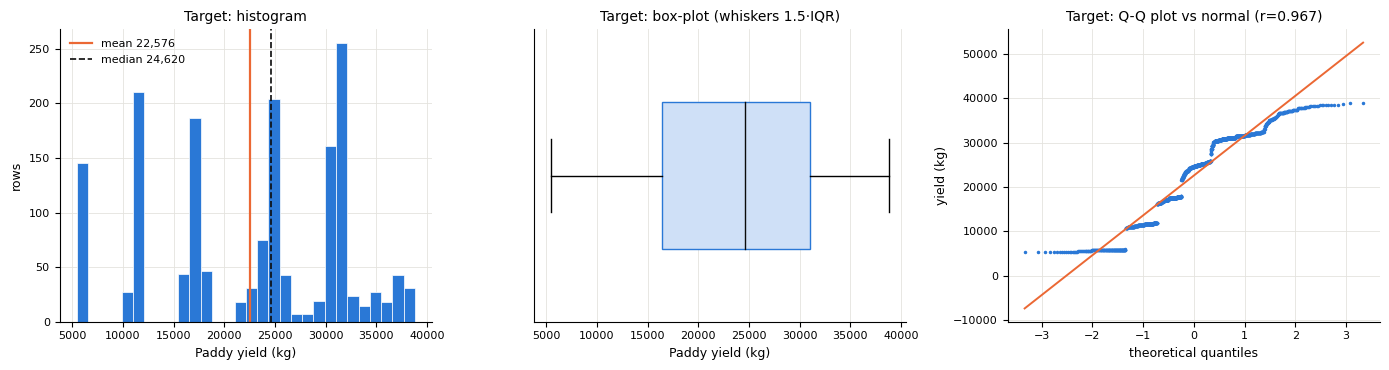

In [12]:
tr = train.copy()                                    # <- all EDA and feature-selection cells from here on use `tr` (train only, never test)
yy = tr[Y]
summ = pd.DataFrame({'Paddy yield (kg)': yy.describe()})
summ.loc['skewness'] = [yy.skew()]
summ.loc['excess kurtosis'] = [yy.kurt()]
summ.loc['Shapiro-Wilk W'] = [stats.shapiro(yy)[0]]
summ.loc['Shapiro p-value'] = [stats.shapiro(yy)[1]]
display(summ)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].hist(yy, bins=30, color=BLUE, edgecolor='white', lw=0.5); ax[0].axvline(yy.mean(), color=ORANGE, lw=1.6, label=f'mean {yy.mean():,.0f}')
ax[0].axvline(yy.median(), color=INK, lw=1.2, ls='--', label=f'median {yy.median():,.0f}'); ax[0].legend(); ax[0].set(title='Target: histogram', xlabel='Paddy yield (kg)', ylabel='rows')
ax[1].boxplot(yy, vert=False, whis=1.5, widths=0.5, patch_artist=True, boxprops=dict(facecolor='#cfe0f7', color=BLUE), medianprops=dict(color=INK), flierprops=dict(marker='o', ms=3, mfc=ORANGE, mec=ORANGE))
ax[1].set(title='Target: box-plot (whiskers 1.5·IQR)', xlabel='Paddy yield (kg)', yticks=[])
(osm, osr), (slope, icpt, r) = stats.probplot(yy, dist='norm'); ax[2].plot(osm, osr, '.', ms=3, color=BLUE); ax[2].plot(osm, slope*osm+icpt, color=ORANGE, lw=1.4)
ax[2].set(title=f'Target: Q-Q plot vs normal (r={r:.3f})', xlabel='theoretical quantiles', ylabel='yield (kg)')
plt.tight_layout(); plt.show()

### 4.1 การอ่านผล — raw target
Mean 22,576 kg, median 24,620 kg, SD 9,258 kg, พิสัย 5,410 – 38,814 kg Skewness **−0.30** (เบ้ซ้ายเพียงเล็กน้อย), excess kurtosis −1.06 (แบนกว่า normal) Shapiro–Wilk W = 0.935, p ≈ 3·10⁻²⁶ → ปฏิเสธความเป็น normal อย่างเป็นทางการ

Histogram *ไม่ใช่* ระฆังคว่ำ — มัน **มียอดแหลมแยกกัน 6 ยอด** (ประมาณ 5.8k, 11.5k, 17.4k, 24.5k, 31k, 36.5k kg) และ Q-Q plot เป็นขั้นบันไดรอบเส้นอ้างอิงแทนที่จะเป็นเส้นทแยงตรง อย่างไรก็ตาม box-plot สมมาตรและไม่มีจุดใดเลยพ้น whisker — ดังนั้นนี่ **ไม่ใช่ปัญหา outlier** (ยืนยันอีกครั้งด้วยกฎที่เป็นทางการใน §6)

**คำถามที่ยังเปิดอยู่** ยอดแหลม 6 ยอดที่คมและห่างเท่า ๆ กันเป็นรูปแบบเฉพาะ ไม่ใช่ "non-normality" ทั่วไป — มันดูเหมือน *mixture* ของประชากรย่อยหลายกลุ่มมากกว่าประชากรเดียวที่เบ้ Dataset มีคอลัมน์เดียวเป๊ะที่จำกัดอยู่ที่ค่าจำนวนเต็ม 6 ค่า คือ `Hectares` (ขนาดแปลง 1–6 ha) ซึ่งเป็นสิ่งแรกที่ควรตรวจสอบโดยธรรมชาติ

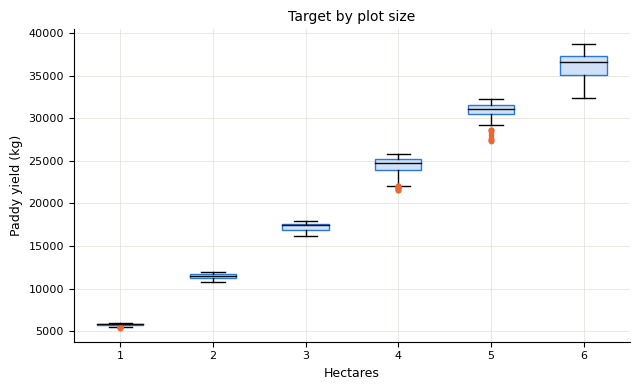

In [13]:
# ---- ตรวจต่อเนื่อง: raw target สอดคล้องกับขนาดแปลงหรือไม่? (ยังเป็น raw target ไม่ต้องสร้างคอลัมน์ใหม่) ----
hs = sorted(tr.Hectares.unique())
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.boxplot([tr.loc[tr.Hectares==h, Y] for h in hs], labels=hs, whis=1.5, patch_artist=True, boxprops=dict(facecolor='#cfe0f7', color=BLUE), medianprops=dict(color=INK), flierprops=dict(marker='o', ms=3, mfc=ORANGE, mec=ORANGE))
ax.set(title='Target by plot size', xlabel='Hectares', ylabel='Paddy yield (kg)'); plt.tight_layout(); plt.show()

### 4.2 การอ่านผล — จัดกลุ่มตามขนาดแปลง
ยืนยันแล้ว: กล่องทั้ง 6 ไต่ขึ้นเกือบเป็นเส้นตรงตาม `Hectares` และแต่ละกล่องตรงกับยอดแหลม 1 ใน 6 ยอดของ histogram ใน §4.1 **รูปทรง multi-modal จึงอธิบายได้ ไม่ใช่ข้อบกพร่อง** — yield เพิ่มตามพื้นที่แปลง ขนาดแปลงมีเพียง 6 ค่า ดังนั้นการรวม 6 กลุ่มพื้นที่ไว้ในคอลัมน์เดียวจึงให้ 6 modes

**คำถามถัดไป** ถ้า yield แปรผันตรงตามพื้นที่จริง *yield ต่อเฮกตาร์* ก็ควรจะค่อนข้างคงที่ทุกแปลง — ซึ่งเป็นมุมมองที่ให้ข้อมูลมากกว่ามากต่อ target ตัวเดียวกัน ตรวจสอบต่อไป

**การตรวจสอบต่อเนื่อง — normalise ด้วยพื้นที่** `Hectares` เป็น ratio scale ที่มีศูนย์แท้ (§2.1) ดังนั้นอัตราส่วน `Y2 = Y / Hectares` ("yield ต่อเฮกตาร์") จึงเป็นปริมาณที่มีความหมาย **Assumption:** `Hectares` ต้องไม่เป็น 0 หรือติดลบในทุกแถว — ยืนยันแล้วใน data-quality audit ของ §2 การหารจึงนิยามได้เสมอ `Y2` เป็น **มุมมองเชิง diagnostic เท่านั้น**: มันไม่เคยเป็น target ของโมเดล และไม่เคยเป็น predictor — ปริมาณที่ถูกทำนายจริงตั้งแต่ §14 เป็นต้นไปยังคงเป็น raw kg

,Paddy yield (kg),Yield per hectare (kg/ha)
count,"1,636","1,636"
mean,"22,576.07","5,985.15"
std,"9,257.53",285.8686
min,"5,410","5,410"
25%,"16,389","5,805.5"
50%,"24,620","5,941.5"
75%,"31,035","6,227"
max,"38,814","6,469"
skewness,-0.3046,-0.2257
excess kurtosis,-1.0597,-0.9672


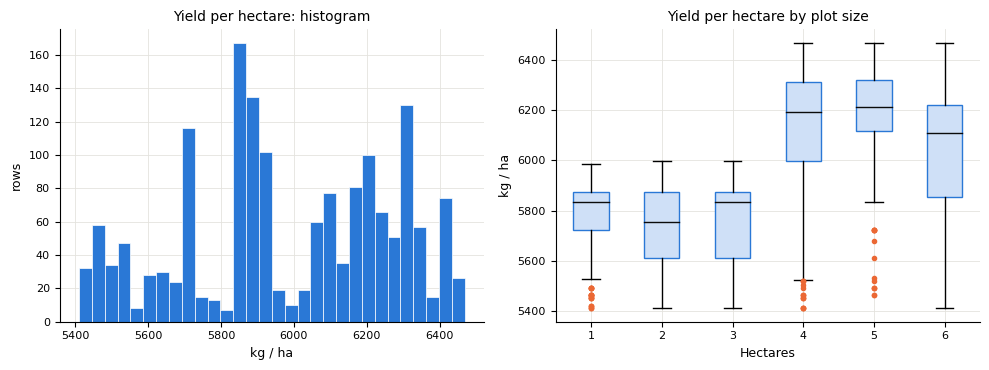

In [14]:
tr['Yield per Ha'] = tr[Y] / tr['Hectares']
Y2 = 'Yield per Ha'
summ2 = pd.DataFrame({'Paddy yield (kg)': tr[Y].describe(), 'Yield per hectare (kg/ha)': tr[Y2].describe()})
summ2.loc['skewness'] = [tr[Y].skew(), tr[Y2].skew()]
summ2.loc['excess kurtosis'] = [tr[Y].kurt(), tr[Y2].kurt()]
display(summ2)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].hist(tr[Y2], bins=30, color=BLUE, edgecolor='white', lw=0.5); ax[0].set(title='Yield per hectare: histogram', xlabel='kg / ha', ylabel='rows')
ax[1].boxplot([tr.loc[tr.Hectares==h, Y2] for h in hs], labels=hs, whis=1.5, patch_artist=True, boxprops=dict(facecolor='#cfe0f7', color=BLUE), medianprops=dict(color=INK), flierprops=dict(marker='o', ms=3, mfc=ORANGE, mec=ORANGE))
ax[1].set(title='Yield per hectare by plot size', xlabel='Hectares', ylabel='kg / ha')
plt.tight_layout(); plt.show()

### 4.3 การอ่านผล — yield ต่อเฮกตาร์
ยืนยันและวัดเป็นตัวเลขแล้ว: yield ต่อเฮกตาร์กระจุกตัวแน่น (mean 5,985, SD 286 kg/ha — การกระจายสัมพัทธ์เพียง **4.8 %**, พิสัย 5,410–6,469 kg/ha) และ box-plot แยกตามขนาดแปลงแทบจะแบนราบ ดังนั้นใช่ — yield แปรผันเกือบตรงกับพื้นที่ ปริศนาจาก §4.1 จึงคลี่คลายสมบูรณ์: ขนาดแปลง 6 ค่า, การ scale เกือบเป็นสัดส่วน, จึงเกิด 6 modes ใน raw target

**อีกประเด็นที่มุมมองนี้ทำให้เกิดขึ้น** กล่องแบนราบใน *ระดับ* ก็จริง แต่คำถามเรื่อง *การกระจาย* (ความแปรปรวนโตขึ้นตามขนาดหรือไม่?) ยังไม่ได้คำตอบจาก box-plot อย่างเดียว — จะตรวจด้วยตัวเลขต่อไป พร้อมกับคำถามที่เหลืออีก 2 ข้อของ Guideline

**คำถามที่เหลืออีก 2 ข้อของ Guideline — target *balanced* หรือไม่ และจำเป็นต้อง *transform* หรือไม่ (Ch02: log, square-root, cube-root, Box-Cox)?** ตรวจ balance ด้วยการ re-bin raw target; ตรวจคำถามเรื่อง transform ด้วยการเปรียบเทียบทั้ง skewness *และ* การกระจายภายในแต่ละขนาดแปลงของ transform แต่ละตัว (spread ratio = 1 หมายถึงความแปรปรวนคงที่ตลอด 6 ขนาดแปลง กล่าวคือ homoscedastic)

In [15]:
# ---- "balance": ทุกช่วงค่าของ target มีข้อมูลหรือไม่? ----
cnt, edges = np.histogram(yy, bins=10)
bal = pd.DataFrame({'range (kg)': [f'{a:,.0f} - {b:,.0f}' for a, b in zip(edges[:-1], edges[1:])], 'rows': cnt, 'share %': cnt / cnt.sum() * 100})
display(bal.T)
print(f'smallest bin holds {cnt.min()} rows ({cnt.min()/cnt.sum():.1%}); largest {cnt.max()} ({cnt.max()/cnt.sum():.1%}); ratio {cnt.max()/cnt.min():.1f}:1')
print('\nrows per plot size (train):', tr.Hectares.value_counts().sort_index().to_dict())
# ---- ตรวจ transform (Ch02: log, sqrt, cube root, Box-Cox) และผลของแต่ละตัวต่อ *ปัญหาการกระจาย* ----
def spread_ratio(v):                      # max/min of the within-Hectares standard deviation: 1 = constant variance (homoscedastic)
    s = pd.Series(np.asarray(v)).groupby(tr.Hectares.values).std(); return s.max() / s.min()
bc, lam = stats.boxcox(yy)
trans = {'raw': yy.values, 'log': np.log(yy), 'sqrt': np.sqrt(yy), 'cube root': np.cbrt(yy), f'Box-Cox (lambda={lam:.2f})': bc}
tt = pd.DataFrame({k: dict(skewness=stats.skew(v), excess_kurtosis=stats.kurtosis(v), Shapiro_W=stats.shapiro(v)[0],
                           spread_ratio_across_plot_sizes=spread_ratio(v)) for k, v in trans.items()}).T
display(tt)

,0,1,2,3,4,5,6,7,8,9
range (kg),"5,410 - 8,750","8,750 - 12,091","12,091 - 15,431","15,431 - 18,772","18,772 - 22,112","22,112 - 25,452","25,452 - 28,793","28,793 - 32,133","32,133 - 35,474","35,474 - 38,814"
rows,145,237,0,277,18,310,57,435,65,92
share %,8.8631,14.4866,0,16.9315,1.1002,18.9487,3.4841,26.5892,3.9731,5.6235


smallest bin holds 0 rows (0.0%); largest 435 (26.6%); ratio inf:1

rows per plot size (train): {1: 145, 2: 237, 3: 277, 4: 371, 5: 467, 6: 139}


,skewness,excess_kurtosis,Shapiro_W,spread_ratio_across_plot_sizes
raw,-0.3043,-1.0601,0.9346,9.6331
log,-1.0524,0.2042,0.8603,1.5238
sqrt,-0.6454,-0.6366,0.9102,3.8307
cube root,-0.7739,-0.4063,0.8966,2.8172
Box-Cox (lambda=1.09),-0.2471,-1.1015,0.9367,11.4542


### 4.4 อภิปราย — การแจกแจงของ target: การตัดสินใจ
**Balanced หรือไม่?** Histogram 10 bins มี 1 bin *ว่างเปล่า* (12,091–15,431 kg) และสัดส่วนของ bin อยู่ระหว่าง 1.1 % ถึง 26.6 % นี่ไม่ใช่ข้อบกพร่องของข้อมูล — ขนาดแปลงมีเพียงจำนวนเต็ม 1…6 (จำนวนแถวต่อขนาด 145/237/277/371/467/139 อัตราส่วนสูงสุด 3.4 : 1) ผลที่ตามมา 2 ข้อ: (i) โมเดลเชื่อถือได้เฉพาะขนาด **1–6 ha** เท่านั้น ไม่ได้เรียนรู้อะไรเลยเกี่ยวกับ 2.5 หรือ 10 ha (คำเตือนเรื่อง extrapolation); (ii) แปลงเล็กสุดและใหญ่สุดมีตัวอย่าง training น้อยที่สุด

**จำเป็นต้อง transform หรือไม่?** Skew เพียง −0.30 อยู่ในเกณฑ์ที่ Guideline ยอมรับ และทุก transform ทำให้ความสมมาตร *แย่ลง* (log −1.05, sqrt −0.65, cube root −0.77; Box-Cox λ ที่เหมาะที่สุด = 1.09 ≈ 1 กล่าวคือ "ไม่มี power transform ใดช่วยได้") แต่คอลัมน์สุดท้ายของตารางแสดงปัญหา *อีกแบบ*: การกระจายของ yield **ภายในแต่ละขนาดแปลงโตขึ้นตามขนาด** — อัตราส่วน max/min ของ SD ภายในขนาดเท่ากับ **9.6 สำหรับ raw target** เทียบกับ **1.5 หลัง log** นั่นคือ *heteroscedasticity* (หนึ่งใน assumption ของ linear regression, Ch01) และเป็นปัญหาเรื่องความแปรปรวน ไม่ใช่ความเบ้ — ดังนั้นการทำ log ถ้าจะใช้ ต้องอ้างเหตุผลว่าเพื่อ **variance stabilisation ไม่ใช่เพื่อความสมมาตร**

**การตัดสินใจ** ใช้ raw yield หน่วย kg เป็น target หลักของโมเดล — เพราะมันคือปริมาณที่สนใจจริงและเป็น target ที่ UCI กำหนด — แต่จะ fit โมเดลแบบ log target ด้วยเพื่อเป็นทางแก้ heteroscedasticity แล้วเปรียบเทียบทั้งสอง (แปลงกลับเป็น kg) ใน §14 ตัว Ordinary least squares เองไม่ต้องการ *target* ที่ normal; Ch01 ต้องการ **residuals** ที่ normal, mean เป็นศูนย์ และความแปรปรวนคงที่ — ดังนั้นรูปทรง 6 modes ของ `y` จึงยอมรับได้ตราบเท่าที่ขนาดแปลงเข้าไปอยู่ในโมเดล ซึ่งตรวจโดยตรงด้วย residual diagnostics ใน §14.5

**Outliers ใน target:** ไม่มีเลยตามกฎ box-plot และไม่มีตาม |z| > 3 (|z| สูงสุด ≈ 1.9) — รายละเอียดพร้อมระเบียบวิธี outlier เต็มรูปแบบอยู่ถัดไปใน §6

**→ ถัดไป (§5)** เมื่อเข้าใจ target แล้ว หันไปดู predictors ทั้ง 44 ตัว: ตัวไหนเป็น candidate บ้าง ก่อนจะรันการทดสอบทางสถิติใด ๆ

# 5 · การสำรวจข้อมูลเบื้องต้นของ features  *(rubric 3 · Guideline ขั้นที่ 3–4)*
**วัตถุประสงค์ (Guideline ขั้นที่ 3):** ประเมินปริมาณและชนิดข้อมูล แล้วถามทุกคอลัมน์ว่า *"มันส่งผลต่อ target หรือไม่?"* — ถ้าตอบ **ไม่** ชัดเจน → ตัดทิ้งทันที **เครื่องมือ:** จำนวนค่าไม่ซ้ำ, สัดส่วนของค่าที่พบมากที่สุด และ **low-variance rule** (Ch02: ตัดคอลัมน์ที่ variance เป็นศูนย์; สำหรับตัวแปร Bernoulli/dummy ค่า variance คือ $p(1-p)$ ดังนั้น category ที่ปรากฏเกิน 80 % ของแถวจะมี variance ต่ำกว่า $0.8\cdot0.2=0.16$)
**Assumption:** คอลัมน์ที่(แทบ)ไม่เปลี่ยนค่าเลยย่อมไม่มีข้อมูลสำหรับโมเดล *ใด ๆ* ไม่ว่า target จะเป็นอะไร

**หมายเหตุเรื่อง `Trash`** `Trash(in bundles)` ถูก **ตัดออกในฐานะ leakage** ไปแล้วด้วยเหตุผลเชิง domain ใน §1.4 — มันไม่ใช่ candidate feature นับตั้งแต่จุดนั้นเป็นต้นมา แต่ยังคงมันไว้ในทุกตารางและทุกรูปด้านล่าง รวมถึงในการทดสอบทางสถิติของ §8 *โดยเจตนา*: หากข้อมูลยืนยันอย่างเป็นอิสระว่ามันไม่มีสัญญาณที่ชอบธรรมเหลืออยู่เมื่อคำนึงถึงขนาดแปลงแล้ว นั่นคือหลักฐานว่าการตัดออกด้วยเหตุผลเชิง domain นั้นถูกต้อง ไม่ใช่เป็นเพียงการกล่าวอ้างลอย ๆ ที่ใดก็ตามที่ `Trash` ปรากฏนับจากนี้ ให้อ่านว่าเป็น **การตรวจสอบเชิง audit ไม่ใช่ candidate**

In [16]:
ov = pd.DataFrame({'dtype': tr.drop(columns=Y2).dtypes.astype(str), 'n_unique': tr.drop(columns=Y2).nunique(),
                   'missing': tr.drop(columns=Y2).isna().sum(),
                   'top value share %': [tr[c].value_counts(normalize=True).iloc[0]*100 for c in tr.drop(columns=Y2).columns]})
ov['role'] = ['target' if c == Y else 'categorical' if c in CAT else 'numeric' for c in ov.index]
display(ov.sort_values(['role', 'n_unique']).head(50))
const = ov[ov.n_unique == 1].index.tolist()
vt = VarianceThreshold(0.0).fit(tr[NUM]); zero_var = [c for c, k in zip(NUM, vt.get_support()) if not k]
print('constant columns (n_unique==1):', const, '| zero-variance numeric (VarianceThreshold(0)):', zero_var)
dom = ov[(ov.role != 'target') & (ov['top value share %'] > 80)]
print('columns whose most frequent value covers > 80 % of rows (variance p(1-p) < 0.16):', dom.index.tolist() if len(dom) else 'none')

,dtype,n_unique,missing,top value share %,role
Soil Types,object,2,0,54.3399,categorical
Nursery,object,2,0,54.9511,categorical
Variety,object,3,0,37.9584,categorical
Wind Direction_D31_D60,object,5,0,37.5917,categorical
Wind Direction_D61_D90,object,5,0,31.9071,categorical
Agriblock,object,6,0,21.3325,categorical
Wind Direction_D1_D30,object,6,0,21.3325,categorical
Wind Direction_D91_D120,object,6,0,21.3325,categorical
30DRain( in mm),float64,3,0,37.4694,numeric
30DAI(in mm),float64,3,0,37.4694,numeric


constant columns (n_unique==1): [] | zero-variance numeric (VarianceThreshold(0)): []
columns whose most frequent value covers > 80 % of rows (variance p(1-p) < 0.16): none


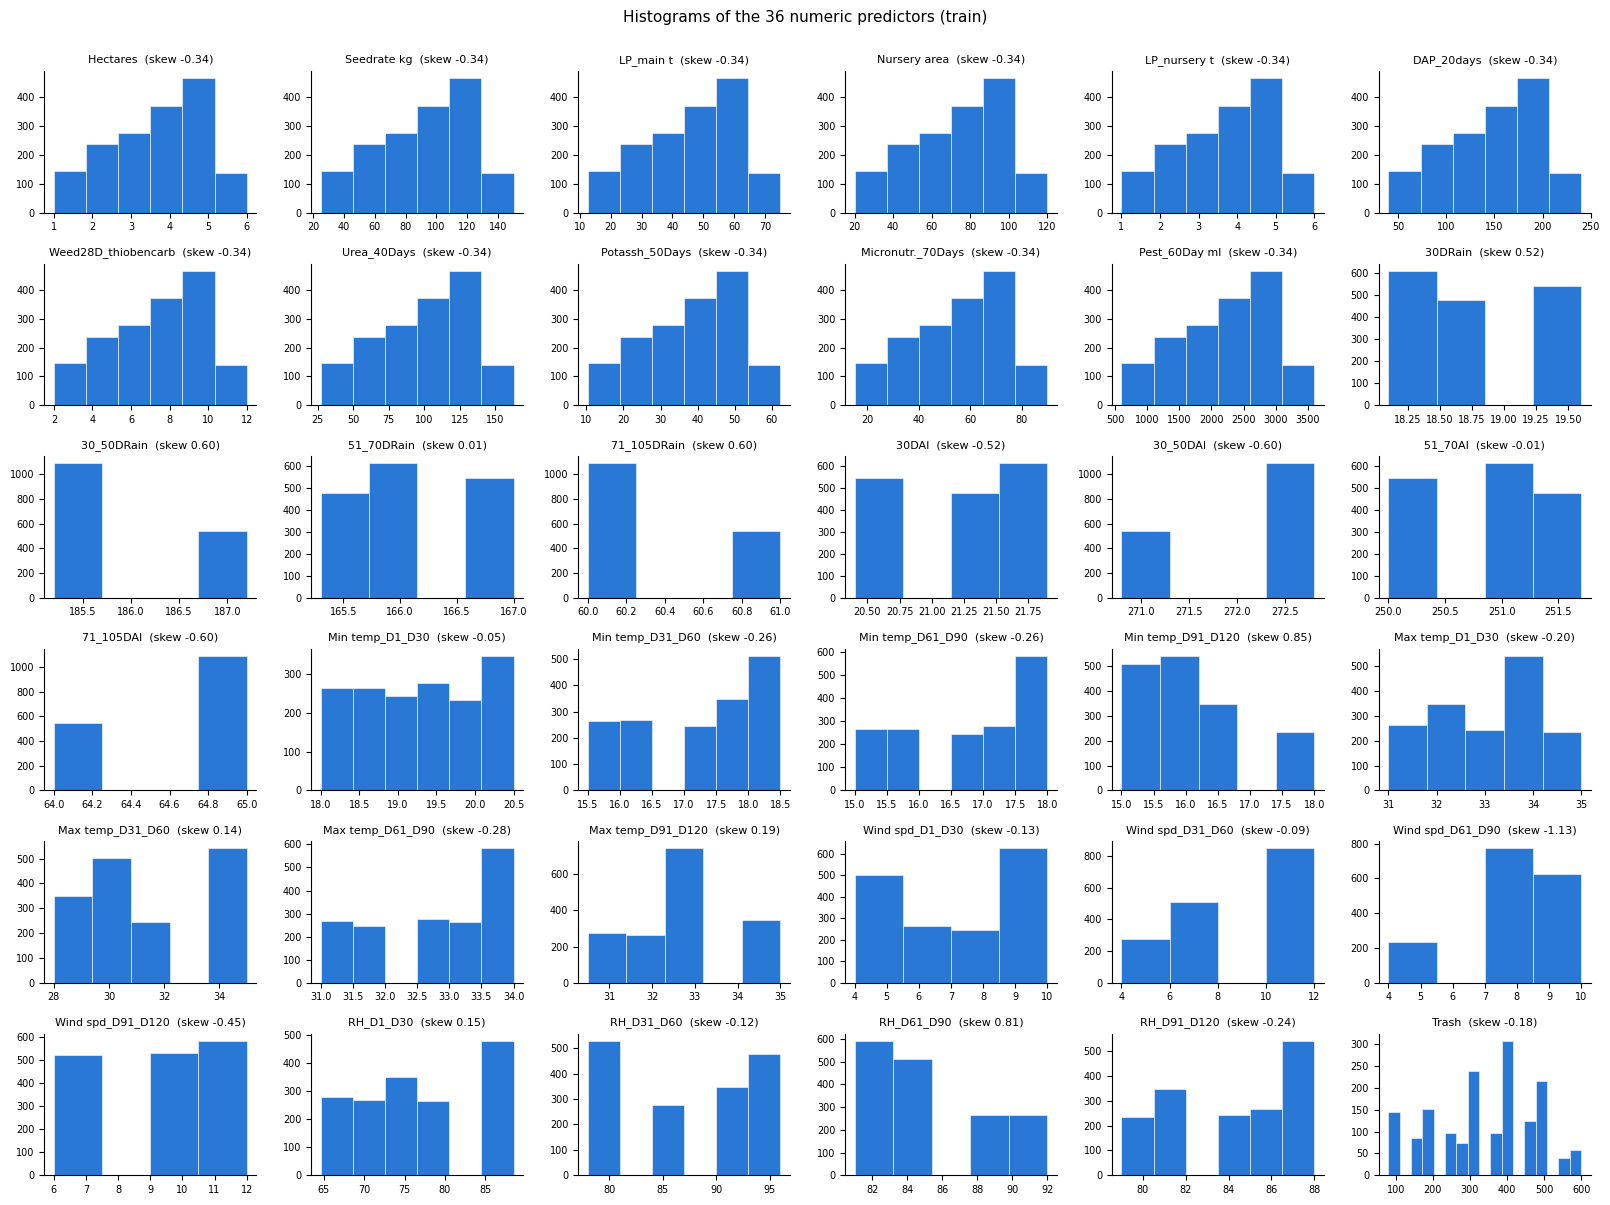

In [17]:
# ---- Visual EDA (Guideline ขั้นที่ 4): histogram สำหรับ continuous / bar chart สำหรับ categorical ----
def short(c):
    for a, b in [('Inst Wind Speed', 'Wind spd'), ('Relative Humidity', 'RH'), ('(in Knots)', ''), ('(in Tonnes)', ' t'), ('(in Kg)', ' kg'),
                 ('(in ml)', ' ml'), ('( in mm)', ''), ('(in mm)', ''), ('(in bundles)', ''), ('Wind Direction', 'Wind dir'), ('Micronutrients', 'Micronutr.'),
                 ('LP_nurseryarea', 'LP_nursery'), ('LP_Mainfield', 'LP_main'), ('Nursery area (Cents)', 'Nursery area')]: c = c.replace(a, b)
    return c.strip()
def grid(n, ncols, w, h):
    nr = int(np.ceil(n / ncols)); fig, ax = plt.subplots(nr, ncols, figsize=(ncols*w, nr*h)); ax = np.atleast_1d(ax).ravel()
    for a in ax[n:]: a.axis('off')
    return fig, ax
fig, ax = grid(len(NUM), 6, 2.7, 2.0)
for a, c in zip(ax, NUM):
    a.hist(tr[c], bins=min(25, max(4, tr[c].nunique())), color=BLUE, edgecolor='white', lw=0.4); a.set_title(f'{short(c)}  (skew {tr[c].skew():.2f})', fontsize=8); a.tick_params(labelsize=7); a.grid(False)
plt.suptitle('Histograms of the 36 numeric predictors (train)', y=1.0, fontsize=11); plt.tight_layout(); plt.show()

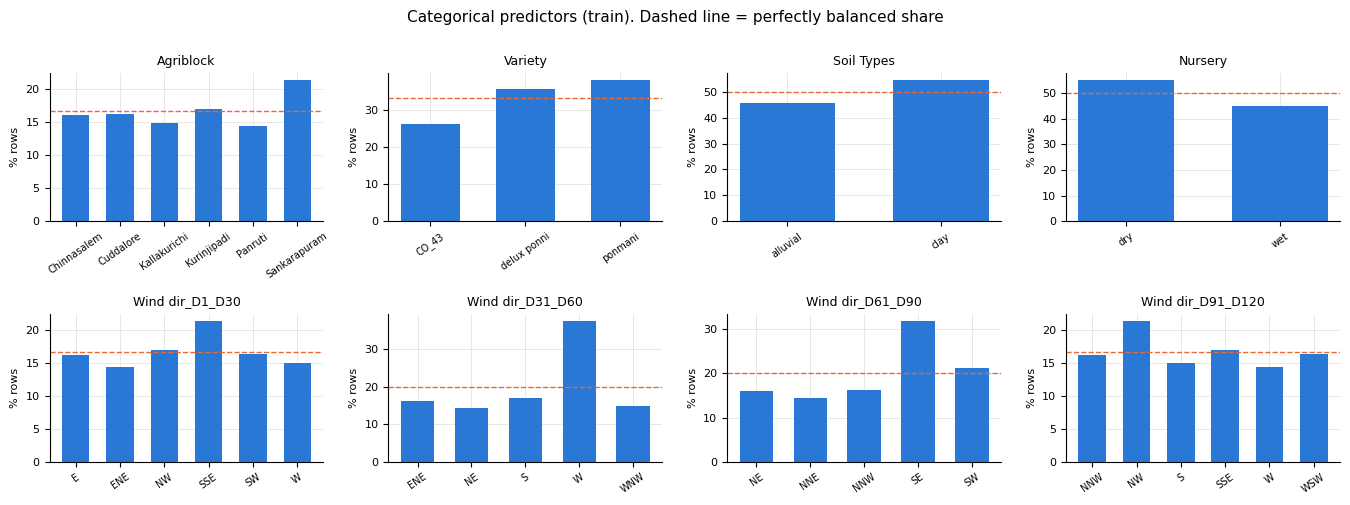

,levels,min_share,max_share,chi2_uniform_p
Agriblock,6,14.3643,21.3325,1.39e-05
Variety,3,26.3447,37.9584,8.31e-09
Soil Types,2,45.6601,54.3399,0.0004
Nursery,2,45.0489,54.9511,6.20e-05
Wind Direction_D1_D30,6,14.3643,21.3325,1.39e-05
Wind Direction_D31_D60,5,14.3643,37.5917,5.55e-68
Wind Direction_D61_D90,5,14.3643,31.9071,4.47e-35
Wind Direction_D91_D120,6,14.3643,21.3325,1.39e-05


|skewness| > 1 : {'Inst Wind Speed_D61_D90(in Knots)': -1.13}
|skewness| > 0.5: 9 of 36 numeric features


In [18]:
fig, ax = grid(len(CAT), 4, 3.4, 2.5)
for a, c in zip(ax, CAT):
    vc = tr[c].value_counts(normalize=True).sort_index() * 100
    a.bar(vc.index, vc.values, color=BLUE, width=0.62); a.set_title(short(c), fontsize=9); a.set_ylabel('% rows', fontsize=8); a.tick_params(axis='x', rotation=35, labelsize=7); a.axhline(100/len(vc), color=ORANGE, lw=1, ls='--')
plt.suptitle('Categorical predictors (train). Dashed line = perfectly balanced share', y=1.0, fontsize=11); plt.tight_layout(); plt.show()
bal = pd.DataFrame({c: dict(levels=tr[c].nunique(), min_share=tr[c].value_counts(normalize=True).min()*100, max_share=tr[c].value_counts(normalize=True).max()*100,
                            chi2_uniform_p=stats.chisquare(tr[c].value_counts().values)[1]) for c in CAT}).T
display(bal)
sk = tr[NUM].skew().sort_values(); print('|skewness| > 1 :', sk[sk.abs() > 1].round(2).to_dict()); print('|skewness| > 0.5:', len(sk[sk.abs() > 0.5]), 'of', len(sk), 'numeric features')

### 5.1 อภิปราย — การสำรวจ features
**ปริมาณและชนิด** 1,636 แถว training, **44 คอลัมน์ที่ไม่ใช่ target** ในไฟล์ (numeric 36, categorical 8) — แต่มีเพียง **43 ตัวที่เป็น candidate จริง**; `Trash` ถูกตัดออกในฐานะ leakage ไปแล้วใน §1.4 และปรากฏด้านล่างเพียงเพื่อการตรวจสอบเชิง audit ตามที่อธิบายข้างต้น ไม่มี missing values

**การตัดคอลัมน์ (Guideline ขั้นที่ 3)** ไม่มีคอลัมน์ใดเป็นค่าคงที่ (`VarianceThreshold(0)` ไม่ตัดอะไรเลย) และไม่มีคอลัมน์ใดที่ค่าหนึ่งครอบคลุมเกิน 80 % ของแถว (สัดส่วนค่าเด่นสูงสุด: 54.9 %, `Nursery`) ดังนั้น **ไม่มีคอลัมน์ใดถูกตัดด้วย low-variance rule** ตามคำถามเชิง domain ว่า "มันส่งผลต่อ target หรือไม่?" ก็ไม่มีคอลัมน์ใดเป็น identifier ส่วน `Trash` ไม่ต้องตรวจ low-variance เลย — มันถูกตัดทิ้งด้วยเหตุผลเรื่อง leakage **ไปแล้ว** ใน §1.4 ก่อนที่หัวข้อนี้จะรัน

**สิ่งที่ histograms แสดง (สถิติ + รูปภาพ)**
* คอลัมน์ numeric แทบทุกตัวมีค่าที่แตกต่างกันเพียง **3–6 ค่า** (`Trash` มี 17 — แสดงไว้เพื่อการ audit เท่านั้น ถูกตัดออกไปแล้ว) histogram จึงเป็นแท่งไม่กี่แท่ง ไม่ใช่เส้นโค้งเรียบ — ข้อมูลทำตัวเหมือนชุด scenario จำนวนน้อย ดังนั้น "continuous" ในที่นี้หมายถึงต่อเนื่อง *ในเชิงความหมาย* ไม่ใช่ในค่าที่สังเกตได้
* **11 คอลัมน์ — `Hectares` และคอลัมน์ input อีก 10 ตัว — มี histogram เหมือนกันเป๊ะและ skewness เท่ากันเป๊ะ (−0.34)** ดูเหมือนเป็นตัวแปรเดียวกันแค่คนละสเกล นี่คือเบาะแสแรกของความซ้ำซ้อน ซึ่งจะทดสอบใน §10
* Histogram ของฝน 4 ตัวและของ AI 4 ตัวเป็น **ภาพสะท้อนกระจก** ของกัน (skewness +0.52 vs −0.52, +0.60 vs −0.60, +0.01 vs −0.01) — เบาะแสว่า AI คือค่าคงที่ลบด้วยฝน (ทดสอบใน §10)
* Skewness: มีเพียง `Wind spd_D61_D90` ที่ |skew| > 1 (−1.13); 9 จาก 36 features มี |skew| > 0.5 การตัดสินใจ: **ไม่ transform predictors** — ความเบ้น้อย คอลัมน์มี level น้อยเกินกว่าที่ log หรือ Box-Cox จะเปลี่ยนรูปทรงได้อย่างมีความหมาย และ OLS ไม่ต้องการ predictors ที่ normal (assumption อยู่ที่ residuals)

**ความสมดุลของ categorical** สัดส่วนของ category เล็กสุด/ใหญ่สุด: Agriblock 14.4 %–21.3 %, Variety 26.3 %–38.0 %, Soil 45.7 %–54.3 %, Nursery 45.0 %–55.0 % การทดสอบ chi-square goodness-of-fit เทียบกับสัดส่วนเท่ากัน reject ความสมดุลสมบูรณ์ในทุกตัว (p < 0.001 เพราะ n ใหญ่) แต่ความไม่สมดุล **น้อย (≤ 1.5 : 1)** สำหรับตัวบรรยายแปลง จึงไม่ต้อง re-sampling หรือ class-weighting `Wind Direction_D1_D30` และ `_D91_D120` มีรูปแบบสัดส่วน *เหมือนกันเป๊ะ* กับ `Agriblock` (สัดส่วนสูงสุด 21.3 %, ต่ำสุด 14.4 %) — เป็นอีกเบาะแสว่าทิศทางลมคือ identifier ของ block ที่ถูกเปลี่ยนชื่อ (§10)

# 6 · การวิเคราะห์ Outlier  *(rubric 4 · Guideline ขั้นที่ 5 · Ch02 "Outliers")*
**ทำไมจึงสำคัญ (Ch02):** least squares minimise residuals *ยกกำลังสอง* ดังนั้นจุดสุดขั้วเพียงจุดเดียวสามารถดึงเส้นที่ fit และสร้างหรือกลบ correlation ได้ สาเหตุ: พิมพ์ข้อมูลผิด, เซ็นเซอร์ผิดพลาด, เหตุการณ์ที่หายากจริง ๆ
**เครื่องมือตรวจจับที่ใช้และ assumption ของแต่ละตัว**

| เครื่องมือ | กฎ | Assumption / จุดอ่อน |
|---|---|---|
| Visual (histogram / box / scatter) | มองหาจุดที่โดดเดี่ยว | ขึ้นกับวิจารณญาณ; ไม่มี assumption |
| **z-score** (Ch02: ห่างจาก mean 2–3 SD) | $|z|>3$ | ข้อมูลต้องประมาณ **Gaussian**; ตัว mean และ SD เองก็ถูก outlier ดันให้สูงขึ้น ("masking") |
| **IQR fence** | อยู่นอก $[Q_1-1.5\,IQR,\;Q_3+1.5\,IQR]$ | ไม่ขึ้นกับการแจกแจง แต่เป็น **univariate**; พังเมื่อหลายแถวมีค่าเดียวกัน (คอลัมน์ discrete) |
| **Residual-based** (อัลกอริทึมการลบแบบ Ch02; studentised residuals, leverage, Cook's D) | residual / influence ที่ใหญ่เมื่อเทียบกับโมเดล | ต้องมี **รูปแบบโมเดลที่ถูกต้อง** และความแปรปรวนของ residual ที่ **คงที่โดยประมาณ** (homoscedasticity) มิฉะนั้นจะไปตั้งธงค่าสังเกตที่ใหญ่ตามธรรมชาติ |

features/targets with at least one flag:


,z_gt_3,iqr_flags,fence_lo,fence_hi,n_unique
Inst Wind Speed_D61_D90(in Knots),0,235,5,13,3


z>3 flags in total: 0 ; IQR flags in total: 235  (over 38 columns x 1636 rows)


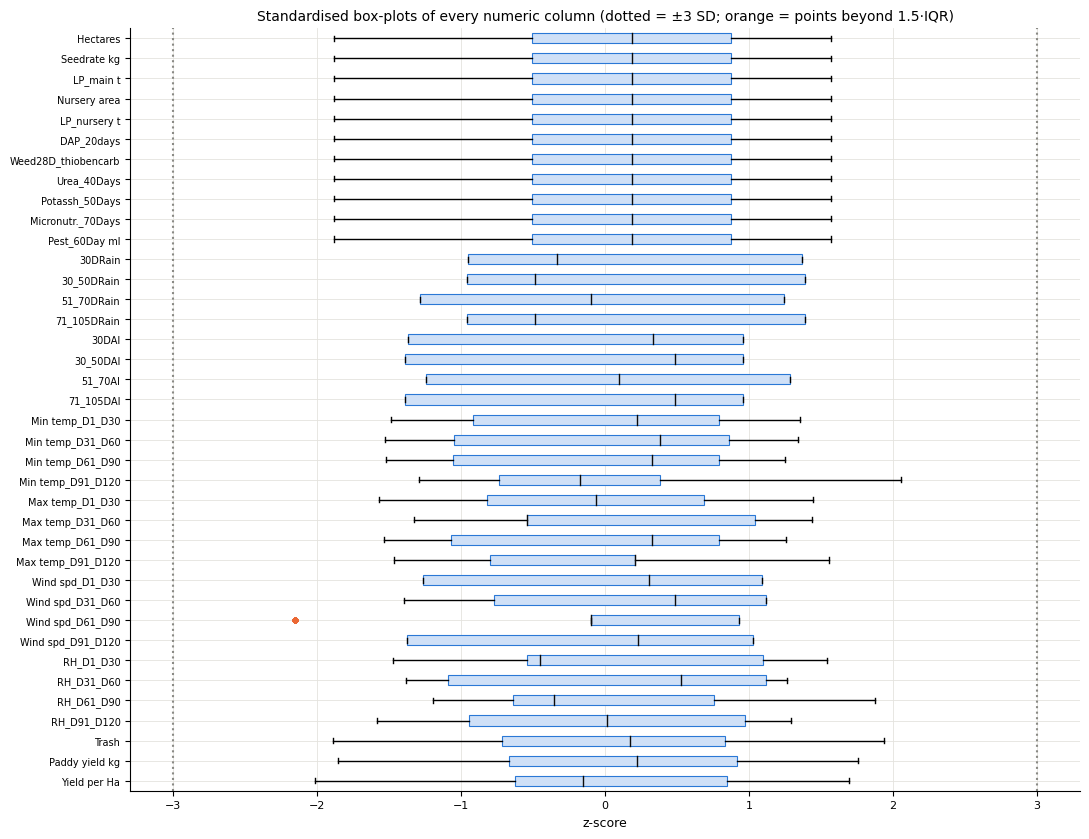

In [19]:
def flags(s):
    z = (s - s.mean()) / s.std(ddof=0); q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    return dict(z_gt_3=int((z.abs() > 3).sum()), iqr_flags=int(((s < lo) | (s > hi)).sum()), fence_lo=lo, fence_hi=hi, n_unique=s.nunique())
out = pd.DataFrame({c: flags(tr[c]) for c in NUM + [Y, Y2]}).T
print('features/targets with at least one flag:'); display(out[(out.z_gt_3 > 0) | (out.iqr_flags > 0)])
print(f'z>3 flags in total: {int(out.z_gt_3.sum())} ; IQR flags in total: {int(out.iqr_flags.sum())}  (over {len(out)} columns x {len(tr)} rows)')
fig, ax = plt.subplots(figsize=(11, 8.5)); cols = NUM + [Y, Y2]
Z = [(tr[c] - tr[c].mean()) / tr[c].std(ddof=0) for c in cols]
ax.boxplot(Z, vert=False, whis=1.5, patch_artist=True, boxprops=dict(facecolor='#cfe0f7', color=BLUE, lw=0.8), medianprops=dict(color=INK), flierprops=dict(marker='o', ms=3, mfc=ORANGE, mec=ORANGE))
ax.set_yticklabels([short(c) for c in cols], fontsize=7); ax.axvline(-3, color=GREY, ls=':'); ax.axvline(3, color=GREY, ls=':'); ax.invert_yaxis()
ax.set(title='Standardised box-plots of every numeric column (dotted = ±3 SD; orange = points beyond 1.5·IQR)', xlabel='z-score'); plt.tight_layout(); plt.show()

,R2,stud_gt_3,cook_gt_4_over_n,max_leverage,max_cook
raw yield ~ Hectares,0.9893,20,68,0.0028,0.0238
log yield ~ log Hectares,0.9944,4,90,0.0042,0.0079


rows with |studentised residual| > 3 in the RAW model, by plot size: {5: 7, 6: 13}
rows with |studentised residual| > 3 in the LOG model, by plot size: {6: 4}


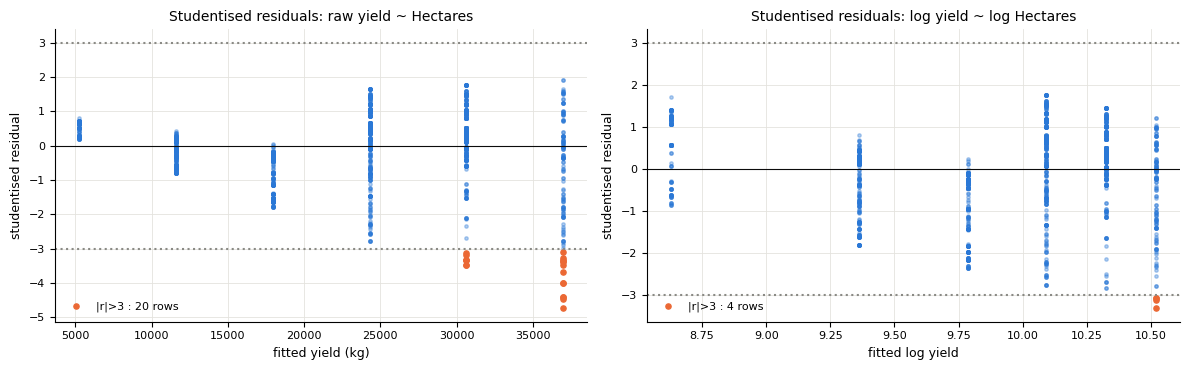

In [20]:
# ---- ตรวจ target แบบอิง residual โดยควบคุมขนาดแปลง (ใช้ Hectares อย่างเดียว: รูปแบบโมเดลซื่อตรง ไม่ transform target) ----
A = ols_influence(tr[['Hectares']], tr[Y]); B = ols_influence(np.log(tr[['Hectares']]), np.log(tr[Y]))
n = len(tr)
rows = {}
for name, I in [('raw yield ~ Hectares', A), ('log yield ~ log Hectares', B)]:
    st, ck = I['stud'], I['cook']
    rows[name] = dict(R2=1 - (I['resid']**2).sum() / ((I['fit'] + I['resid'] - (I['fit'] + I['resid']).mean())**2).sum(),
                      stud_gt_3=int((np.abs(st) > 3).sum()), cook_gt_4_over_n=int((ck > 4/n).sum()), max_leverage=I['h'].max(), max_cook=ck.max())
display(pd.DataFrame(rows).T)
print('rows with |studentised residual| > 3 in the RAW model, by plot size:', tr.loc[np.abs(A['stud']) > 3, 'Hectares'].value_counts().sort_index().to_dict())
print('rows with |studentised residual| > 3 in the LOG model, by plot size:', tr.loc[np.abs(B['stud']) > 3, 'Hectares'].value_counts().sort_index().to_dict())
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a, I, t, xl in [(ax[0], A, 'raw yield ~ Hectares', 'fitted yield (kg)'), (ax[1], B, 'log yield ~ log Hectares', 'fitted log yield')]:
    bad = np.abs(I['stud']) > 3; a.scatter(I['fit'][~bad], I['stud'][~bad], s=6, alpha=.35, color=BLUE); a.scatter(I['fit'][bad], I['stud'][bad], s=14, color=ORANGE, label=f'|r|>3 : {bad.sum()} rows')
    a.axhline(3, color=GREY, ls=':'); a.axhline(-3, color=GREY, ls=':'); a.axhline(0, color=INK, lw=.8); a.set(title=f'Studentised residuals: {t}', xlabel=xl, ylabel='studentised residual'); a.legend()
plt.tight_layout(); plt.show()

In [21]:
# ---- สาธิตด้วยความผิดพลาดร้ายแรงแบบสังเคราะห์ (ข้อมูลจริงแทบไม่มีเลย): เครื่องมือแต่ละตัวทำงานอย่างไร? ----
rng = np.random.default_rng(SEED)
d0 = tr[['Hectares', Y]].reset_index(drop=True); k = int(0.02 * len(d0))
bad_idx = rng.choice(len(d0), k, replace=False); d1 = d0.copy()
d1.loc[bad_idx, Y] = d1.loc[bad_idx, Y] * rng.choice([0.2, 3.0], size=k)          # mistyped decimal / extra digit
def slope(d): return LinearRegression().fit(d[['Hectares']], d[Y]).coef_[0]
def residual_trim(d, frac=0.01, rounds=3):                                           # Ch02 "Outlier Removal Algorithm"
    keep = np.ones(len(d), bool)
    for _ in range(rounds):
        m = LinearRegression().fit(d.loc[keep, ['Hectares']], d.loc[keep, Y]); res = np.abs(d[Y] - m.predict(d[['Hectares']])); res[~keep] = -1
        keep[np.argsort(-res.values)[:int(frac * len(d))]] = False
    return ~keep
s = d1[Y]; z = (s - s.mean()) / s.std(ddof=0); q1, q3 = s.quantile([.25, .75])
flag = {'z-score |z|>3 (on y alone)': (z.abs() > 3).values,
        'IQR fence (on y alone)': ((s < q1 - 1.5*(q3-q1)) | (s > q3 + 1.5*(q3-q1))).values,
        'studentised residual |r|>3 (given Hectares)': np.abs(ols_influence(d1[['Hectares']], d1[Y])['stud']) > 3,
        'iterative residual trimming (Ch02, 3 x 1 %)': residual_trim(d1)}
truth = np.zeros(len(d0), bool); truth[bad_idx] = True
res = []
for name, f in flag.items():
    res.append((name, int((f & truth).sum()), int((f & ~truth).sum()), (f & truth).sum() / truth.sum(), slope(d1[~f])))
res.append(('no treatment', 0, 0, 0.0, slope(d1)))
tab = pd.DataFrame(res, columns=['method', 'caught (of %d injected)' % k, 'false alarms', 'recall', 'fitted slope kg/ha']).set_index('method')
print(f'clean-data slope = {slope(d0):,.1f} kg per ha')
display(tab)

clean-data slope = 6,353.5 kg per ha


,caught (of 32 injected),false alarms,recall,fitted slope kg/ha
method,,,,
z-score |z|>3 (on y alone),12,0,0.375,"6,230.49"
IQR fence (on y alone),13,0,0.4062,"6,238.14"
studentised residual |r|>3 (given Hectares),26,0,0.8125,"6,360.71"
"iterative residual trimming (Ch02, 3 x 1 %)",32,16,1,"6,387.62"
no treatment,0,0,0,"6,436.09"


### 6.1 อภิปราย — outliers
**สถิติ** จาก 38 คอลัมน์ (36 predictors + 2 targets) และ 1,636 แถว **|z| > 3 ไม่ตั้งธงอะไรเลย** กฎ IQR ตั้งธง 235 ค่า (14 % ของแถว) แต่ **อยู่ในคอลัมน์เดียวทั้งหมด** คือ `Wind spd_D61_D90`: มันคือ level "4 knots" เฉย ๆ (หนึ่งใน 3 levels คือ 4 / 8 / 10) เมื่อมี 3 levels และ 47 % ของแถวอยู่ที่ค่าเดียว quartiles จะยุบตัว (fences 5 – 13) ทำให้ level ต่ำสุดดู "outlying" นี่คือ **false alarm ที่เกิดจาก assumption ของ IQR ใช้ไม่ได้กับคอลัมน์ discrete** ไม่ใช่ความผิดพลาดของข้อมูล ส่วน target และ yield ต่อเฮกตาร์ไม่ถูกตั้งธงเลยทั้งสองกฎ

**รูปภาพ** ใน box-plots แบบ standardised ทุก whisker อยู่ในช่วง ±3 SD อย่างสบาย และจุดสีส้มจุดเดียวคือ level ของลมนั้น

**มุมมองแบบมีเงื่อนไข (residual)** เมื่อควบคุมขนาดแปลง โมเดลแบบ *raw* ตั้งธง 20 แถวที่ |studentised residual| > 3 — **ทั้งหมดมาจาก 2 ขนาดแปลงที่ใหญ่ที่สุด (5 ha: 7 แถว, 6 ha: 13 แถว)** — และ residual plot แสดงเหตุผล: การกระจายบานออกตามขนาด (รูปกรวย) หลัง log transform เหลือเพียง 4 แถว (6 ha ทั้งหมด) ซึ่งเป็นจำนวนที่ความบังเอิญล้วน ๆ ทำนายไว้ (1,636 × 0.27 % ≈ 4.4) Influence น้อยมาก: leverage สูงสุด 0.0028 และ Cook's D สูงสุด 0.024 (เกณฑ์ "มีปัญหา" ตามปกติคือ 1); กฎ 4/*n* ตั้งธง 68 (raw) / 90 (log) แถว แต่กฎนั้นตั้งธง ≈ 4–5 % ของแถวโดยโครงสร้างอยู่แล้ว และไม่มีแถวใดขยับ fit เลย ดังนั้น "outliers" ของโมเดล raw จึงเป็น **ผลพวงของ heteroscedasticity** ไม่ใช่ record ที่ผิด (กฎ residual นี้สมมติว่าความแปรปรวนคงที่ ซึ่ง raw yield ละเมิด — §4)

**การตัดสินใจ: ไม่ลบแถวใด และไม่ cap ค่าใด** เหตุผล: (1) ไม่มีหลักฐานว่ามีความผิดพลาดในการวัด — ทุกค่าสุดขั้วเป็น yield ที่เป็นไปได้ทางกายภาพสำหรับขนาดแปลงนั้น; (2) การลบแปลงใหญ่ที่ถูกต้องตามจริงจะไปหด variance จริงและทำให้ slope เอนเอียง; (3) ไม่มี observation ใดมี influence ที่มีนัยสำคัญ

**เครื่องมือทำอะไรได้และทำอะไรไม่ได้ — การทดลองเชิงสังเคราะห์** เราจงใจทำให้ 2 % ของ target ใน training เสีย (32 แถว: คูณ 0.2 หรือคูณ 3 เสมือนพิมพ์จุดทศนิยมผิด / เกินหนึ่งหลัก) แล้วใช้เครื่องมือแต่ละตัว slope ของข้อมูลที่สะอาดคือ 6,353.5 kg/ha

| เครื่องมือ | จับได้ (จาก 32) | False alarms | Slope หลังลบ |
|---|---|---|---|
| ไม่ทำอะไร | 0 | 0 | 6,436.1 (ผิด +82.6) |
| z-score บน y | 12 (37.5 %) | 0 | 6,230.5 (**−123.0 แย่กว่าการไม่ทำอะไรเลย**) |
| IQR บน y | 13 (40.6 %) | 0 | 6,238.1 (−115.4) |
| studentised residual เมื่อควบคุม Hectares | 26 (81.3 %) | 0 | 6,360.7 (**+7.2**) |
| iterative residual trimming (Ch02, 3 × 1 %) | 32 (100 %) | 16 | 6,387.6 (+34.1) |

กฎ z-score และ IQR เห็นเฉพาะการแจกแจงแบบ *marginal* ดังนั้นความผิดพลาดแบบ 0.2× บนแปลงใหญ่จะดูเหมือนแปลงเล็กธรรมดาและถูกมองข้าม; มันลบเฉพาะความผิดพลาดแบบ ×3 ทิ้งตัวที่ต่ำไว้ แล้ว slope ก็แย่กว่าการไม่ทำอะไรเลย เมื่อพิจารณาแบบมีเงื่อนไขกับขนาดแปลง ความผิดพลาดจะโดดเด่นออกมา อัลกอริทึม trimming ของ Ch02 จับได้ครบแต่ลบแถวที่ดีไปด้วยในสัดส่วนคงที่ทุกรอบ (false alarm 16 แถว) **นโยบายสำหรับข้อมูลในอนาคต:** ตรวจจับด้วยกฎ residual *บนสเกล log (ความแปรปรวนคงที่)* ยืนยันกับแหล่งข้อมูล แล้วจึงแก้หรือลบ; ห้ามใช้ z-score/IQR แบบ marginal เพียงลำพังกับ dataset นี้

# 7 · การวิเคราะห์ Missing Value  *(rubric 5 · Guideline ขั้นที่ 6 · Ch01 / Ch02 "Missing Value")*
กฎของ Guideline: พิจารณาแต่ละคอลัมน์แยกกัน; **missing > 30 % → ตัดคอลัมน์ทิ้ง**; ถ้ามีไม่กี่แถว → ลบแถวนั้น; นอกนั้นให้ **impute** (mean / median / mode / regression / nearest-neighbour hot-deck) พร้อมบอก *เหตุผล*

In [22]:
miss = pd.DataFrame({'missing_n': tr.isna().sum(), 'missing_%': tr.isna().mean() * 100})
print('columns with any missing value:', int((miss.missing_n > 0).sum()), '| maximum missing % in any column:', miss['missing_%'].max())
print('missing-value check on the TEST part (only counts, nothing learned from it):', int(test.isna().sum().sum()))

columns with any missing value: 0 | maximum missing % in any column: 0.0
missing-value check on the TEST part (only counts, nothing learned from it): 0


**ผลลัพธ์: ไม่มีค่าใดหายไปเลย** จึงไม่มีการลบแถวหรือคอลัมน์ ถึงกระนั้นก็ยังต้องมีนโยบายที่บันทึกไว้สำหรับ pipeline และข้อมูลในอนาคต และนโยบายนั้นควรถูก *ทดสอบ* ไม่ใช่แค่ประกาศไว้เฉย ๆ ตารางด้านล่างให้กฎการตัดสินใจและ assumption ของมัน ส่วนการทดลองถัดไปนำกฎนี้ไปใช้กับค่าที่เราจงใจลบทิ้งและรู้ค่าจริงอยู่แล้ว

| สถานการณ์ | การกระทำ | เหตุผล / assumption |
|---|---|---|
| คอลัมน์ missing > 30 % | ตัดคอลัมน์ทิ้ง | เหลือข้อมูลน้อยเกินกว่าจะ impute ได้อย่างน่าเชื่อถือ (Guideline) |
| missing ไม่กี่แถว (< ~5 %) และกลไกเป็น **MCAR** (missing completely at random) | ลบแถวเหล่านั้น | สูญเสียข้อมูลน้อย ไม่เกิด bias *ถ้า* เป็น MCAR จริง (Ch02: "missing data อาจไม่ได้สุ่มอย่างที่คุณคิด") |
| numeric ที่เบ้หรือมี outlier | **median** | ทนทานต่อค่าสุดขั้ว |
| numeric ที่ค่อนข้างสมมาตร | **mean** | minimise squared error แต่จะหด variance และทำให้ correlation อ่อนลง |
| categorical | **mode** | category ที่น่าจะเป็นที่สุด แต่เพิ่ม bias ไปทางกลุ่มใหญ่ |
| การหายไปขึ้นกับ *ตัวแปรอื่นที่สังเกตได้* (**MAR**) และตัวแปรเหล่านั้นทำนายได้ | **regression / kNN (hot-deck)** imputation | ใช้ประโยชน์จากความสัมพันธ์; แต่ความสัมพันธ์นั้นต้องมีอยู่จริง |
| การหายไปขึ้นกับตัวค่าเอง (**MNAR**) | ตรรกะเชิง domain + คอลัมน์ missing-indicator | imputation เชิงสถิติแก้ไม่ได้ |
| **เสมอ** | fit imputer บน **train เท่านั้น** และห้ามใช้ target ในการ impute feature | มิฉะนั้นจะเกิด leakage |

In [23]:
# ---- การทดลอง: ลบ 10 % ของคอลัมน์หนึ่งแบบสุ่มสมบูรณ์ (MCAR), impute, แล้วเทียบกับค่าจริงที่ซ่อนไว้ ----
rng = np.random.default_rng(SEED)
def design_without(col):
    num = [c for c in NUM if c not in (col, TRASH)]; cats = [c for c in CAT if c != col]      # target and Trash never used to impute
    Z = pd.concat([tr[num], pd.get_dummies(tr[cats]).astype(float)], axis=1)
    return (Z - Z.mean()) / Z.std(ddof=0).replace(0, 1)
rows = []
for col in ['Hectares', 'Relative Humidity_D31_D60']:
    truth = tr[col].values.astype(float); mask = rng.random(len(truth)) < 0.10; obs = ~mask; Z = design_without(col)
    r_true = np.corrcoef(truth, tr[Y])[0, 1]
    P = {'mean': np.full(mask.sum(), truth[obs].mean()), 'median': np.full(mask.sum(), np.median(truth[obs])),
         'regression (other columns)': LinearRegression().fit(Z[obs], truth[obs]).predict(Z[mask]),
         'kNN hot-deck (k=5)': KNeighborsRegressor(5).fit(Z[obs], truth[obs]).predict(Z[mask])}
    for m, p in P.items():
        comp = truth.copy(); comp[mask] = p
        rows.append((col, m, np.sqrt(np.mean((p - truth[mask])**2)), np.sqrt(np.mean((p - truth[mask])**2)) / truth.std(), comp.std() / truth.std(), np.corrcoef(comp, tr[Y])[0, 1] - r_true))
imp = pd.DataFrame(rows, columns=['column', 'method', 'RMSE', 'RMSE / SD of column', 'SD after / SD true', 'change in corr with target']).set_index(['column', 'method'])
display(imp)
rows = []
for col in ['Agriblock', 'Variety']:
    truth = tr[col].values; mask = rng.random(len(truth)) < 0.10; obs = ~mask; Z = design_without(col)
    mode = pd.Series(truth[obs]).mode()[0]
    rows.append((col, 'mode', np.mean(truth[mask] == mode)))
    rows.append((col, 'kNN hot-deck (k=5)', np.mean(KNeighborsClassifier(5).fit(Z[obs], truth[obs]).predict(Z[mask]) == truth[mask])))
display(pd.DataFrame(rows, columns=['column', 'method', 'accuracy on hidden values']).set_index(['column', 'method']))

RMSE  RMSE / SD of column  SD after / SD true  change in corr with target
column                    method                                                                                                  
Hectares                  mean                         1.5996               1.1041              0.9418                     -0.0581
                          median                       1.6583               1.1446              0.9431                     -0.0619
                          regression (other columns) 9.56e-15             6.60e-15                   1                           0
                          kNN hot-deck (k=5)           0.3426               0.2365              0.9864                     -0.0024
Relative Humidity_D31_D60 mean                         6.9815               1.0273              0.9419                      0.0077
                          median                       8.0997               1.1918              0.9555                      0.0106
                          regression (other columns) 4.13e-14             6.08e-15                   1                    3.69e-17
                          kNN hot-deck (k=5)                0                    0                   1                           0

accuracy on hidden values
column    method                                       
Agriblock mode                                   0.2625
          kNN hot-deck (k=5)                          1
Variety   mode                                   0.3789
          kNN hot-deck (k=5)                     0.3354

### 7.1 อภิปราย — missing values
**ข้อมูลจริง:** 0 ช่องที่หายไปในทั้ง 45 คอลัมน์ของส่วน training (และ 0 ใน test) ดังนั้นไม่มีคอลัมน์ถูกตัด (Guideline: > 30 %) และไม่มีแถวถูกลบหรือถูก impute อย่างไรก็ตาม preprocessing pipeline (§12) ยังคงมี imputer ที่ fit บน train (median สำหรับ numeric, most-frequent สำหรับ categorical) ไว้เป็นตาข่ายนิรภัย — มันไม่ทำอะไรเลยในที่นี้ และบันทึกไว้เพื่อความครบถ้วน

**การทดลอง (ลบ 10 % แบบสุ่มสมบูรณ์ MCAR; รู้ค่าจริง)**

| คอลัมน์ | mean | median | regression | kNN (k = 5) |
|---|---|---|---|---|
| `Hectares` — RMSE (ha) | 1.60 | 1.66 | ≈ 0 | 0.34 |
| `Relative Humidity_D31_D60` — RMSE (%) | 6.98 | 8.10 | ≈ 0 | 0 |
| `Agriblock` — accuracy | mode 26.3 % | | | kNN **100 %** |
| `Variety` — accuracy | mode **37.9 %** | | | kNN 33.5 % |

**สถิติและความหมาย**
* การ impute ด้วย mean/median ให้ค่าความผิดพลาดใหญ่พอ ๆ กับ SD ของคอลัมน์นั้นเอง (RMSE / SD ≈ 1.03–1.19) และ **หดการกระจาย** (SD หลัง / SD จริง = 0.94) สำหรับ `Hectares` การ mean-impute 10 % ของแถว **ลด correlation กับ target ลง 0.058** (≈ 0.995 → 0.937): นี่คือ attenuation bias ที่รู้กันดีของ single mean imputation (สไลด์ Ch01 "Arithmetic Mean Imputation")
* Regression imputation กู้คืน `Hectares` และความชื้นได้ **เป๊ะ** — แต่เพียงเพราะคอลัมน์อื่นมีข้อมูลเดียวกันอยู่แล้ว (input ทั้ง 10 ตัวเป็นพหุคูณที่แน่นอนของ `Hectares` และสภาพอากาศคงที่ภายใน agri-block; พิสูจน์ทั้งคู่ใน §10) วิธีนี้ได้ผลเมื่อมีความสัมพันธ์อยู่จริง มันไม่ได้ "เรียนรู้วิชาเกษตร"
* สำหรับ `Variety` ไม่มีคอลัมน์อื่นทำนายมันได้ ดังนั้น kNN (33.5 %) จึง *แย่กว่า* mode (37.9 %): การใช้วิธีที่อิงความสัมพันธ์ทั้งที่ไม่มีความสัมพันธ์ ก็แค่เพิ่ม noise

**Assumptions** การทดลองนี้สมมติ MCAR ส่วน missingness จริง (เช่น เกษตรกรไม่รายงานแปลงใหญ่) อาจเป็น MAR หรือ MNAR ซึ่งความผิดพลาดจะสูงกว่านี้และไม่มี imputer ใดปลอดภัย Regression / kNN imputation สมมติว่า predictors เองครบถ้วน และความสัมพันธ์เหมือนกันสำหรับแถวที่หาย ใช้ mask สุ่มเพียงชุดเดียวและ seed เดียว ค่าที่ได้จึงเป็นเพียงตัวอย่างประกอบ แต่ลำดับของวิธีเป็นผลจากโครงสร้างข้อมูล ไม่ใช่ความบังเอิญ

**การตัดสินใจสำหรับข้อมูลในอนาคต:** เลือกวิธีตามว่ามีความสัมพันธ์เชิงทำนายอยู่หรือไม่ — regression/kNN hot-deck สำหรับคอลัมน์ขนาดและสภาพอากาศ, mode สำหรับ `Variety`/`Soil`/`Nursery` — โดย fit บนแถว training เท่านั้นเสมอ และไม่ใช้ target

# 8 · Feature selection — continuous features  *(rubrics 6, 7, 8 · Guideline ขั้นที่ 7)*
**เป้าหมาย:** เก็บคอลัมน์ที่สัมพันธ์กับ target ใช้เฉพาะ **filter methods** (Ch02: ตัดสิน feature *โดยไม่ต้อง train โมเดลสุดท้าย*; embedded และ wrapper methods อยู่นอกขอบเขต HW1) ทุกอย่างคำนวณบน **`train` เท่านั้น** (leakage guard) พิจารณา 3 targets: raw yield `Y`; yield ต่อเฮกตาร์ `Y/ha`; และ **`Y/ha` ที่ปรับตามขนาดแล้ว** (= `Y/ha` ลบด้วยค่าเฉลี่ย `Y/ha` ของขนาดแปลงเดียวกัน คำนวณบน train) ขนาดแปลงครอบงำ `Y` และสามารถกลบทุกอย่างได้ — สไลด์ Ch02 *"สรุปได้ไหมว่าไม่มีความสัมพันธ์?"* เตือนว่าผลทดสอบที่ไม่มีนัยสำคัญไม่ใช่ข้อพิสูจน์ว่าไม่มีความสัมพันธ์ เมื่อ nuisance variance มีขนาดใหญ่; target ที่ปรับแล้วจะกำจัด nuisance นั้นออก ทำให้เห็นผลที่อ่อนได้ ส่วน `Trash` (ถูกตัดออกในฐานะ leakage ไปแล้ว, §1.4) ก็ถูกใส่ไว้ในการทดสอบด้านล่างโดยเจตนาเช่นกัน — ด้วยเหตุผลเชิง audit เดียวกับ §5: เพื่อตรวจสอบ correlation ที่ดูเหมือนจะมีของมันเชิงประจักษ์ ไม่ใช่เพราะมันเป็น candidate

### 8.1 การวิเคราะห์เชิงภาพ — scatter plots
แต่ละแผง: feature (แกน x) vs target (แกน y), สีน้ำเงิน = แถวข้อมูล, **เส้นสีส้ม = ค่าเฉลี่ยของ target ที่แต่ละค่า x ที่สังเกตได้** (แสดงรูปทรงของความสัมพันธ์แม้ x จะมีค่าไม่ซ้ำน้อย), `r` = Pearson correlation

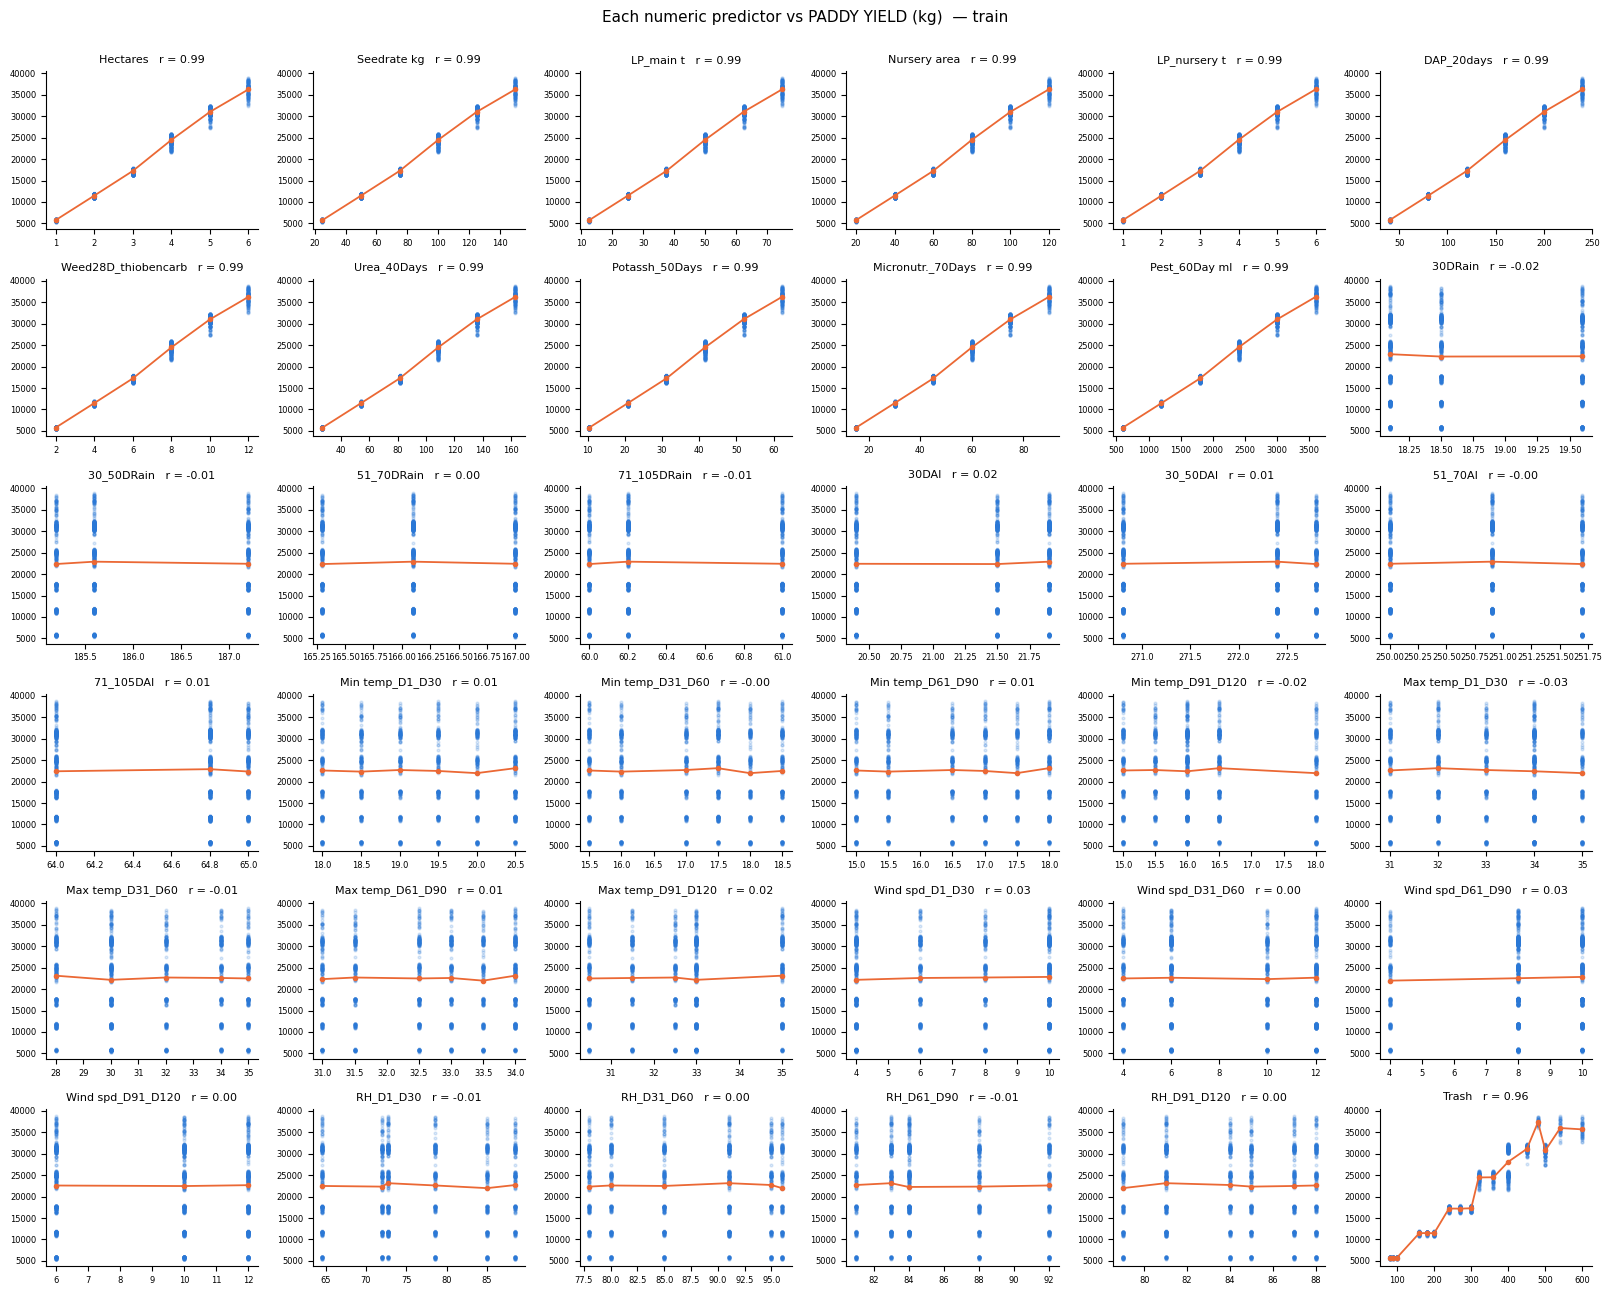

In [24]:
def scatter_grid(target, ttl):
    fig, ax = grid(len(NUM), 6, 2.7, 2.15)
    for a, c in zip(ax, NUM):
        x, yv = tr[c].values, tr[target].values
        a.scatter(x, yv, s=4, alpha=.16, color=BLUE, rasterized=True)
        m = tr.groupby(c)[target].mean(); a.plot(m.index, m.values, '-o', color=ORANGE, ms=3, lw=1.3)
        a.set_title(f'{short(c)}   r = {np.corrcoef(x, yv)[0,1]:.2f}', fontsize=8); a.tick_params(labelsize=6); a.grid(False)
    plt.suptitle(ttl, y=1.0, fontsize=11); plt.tight_layout(); plt.show()
scatter_grid(Y, 'Each numeric predictor vs PADDY YIELD (kg)  — train')

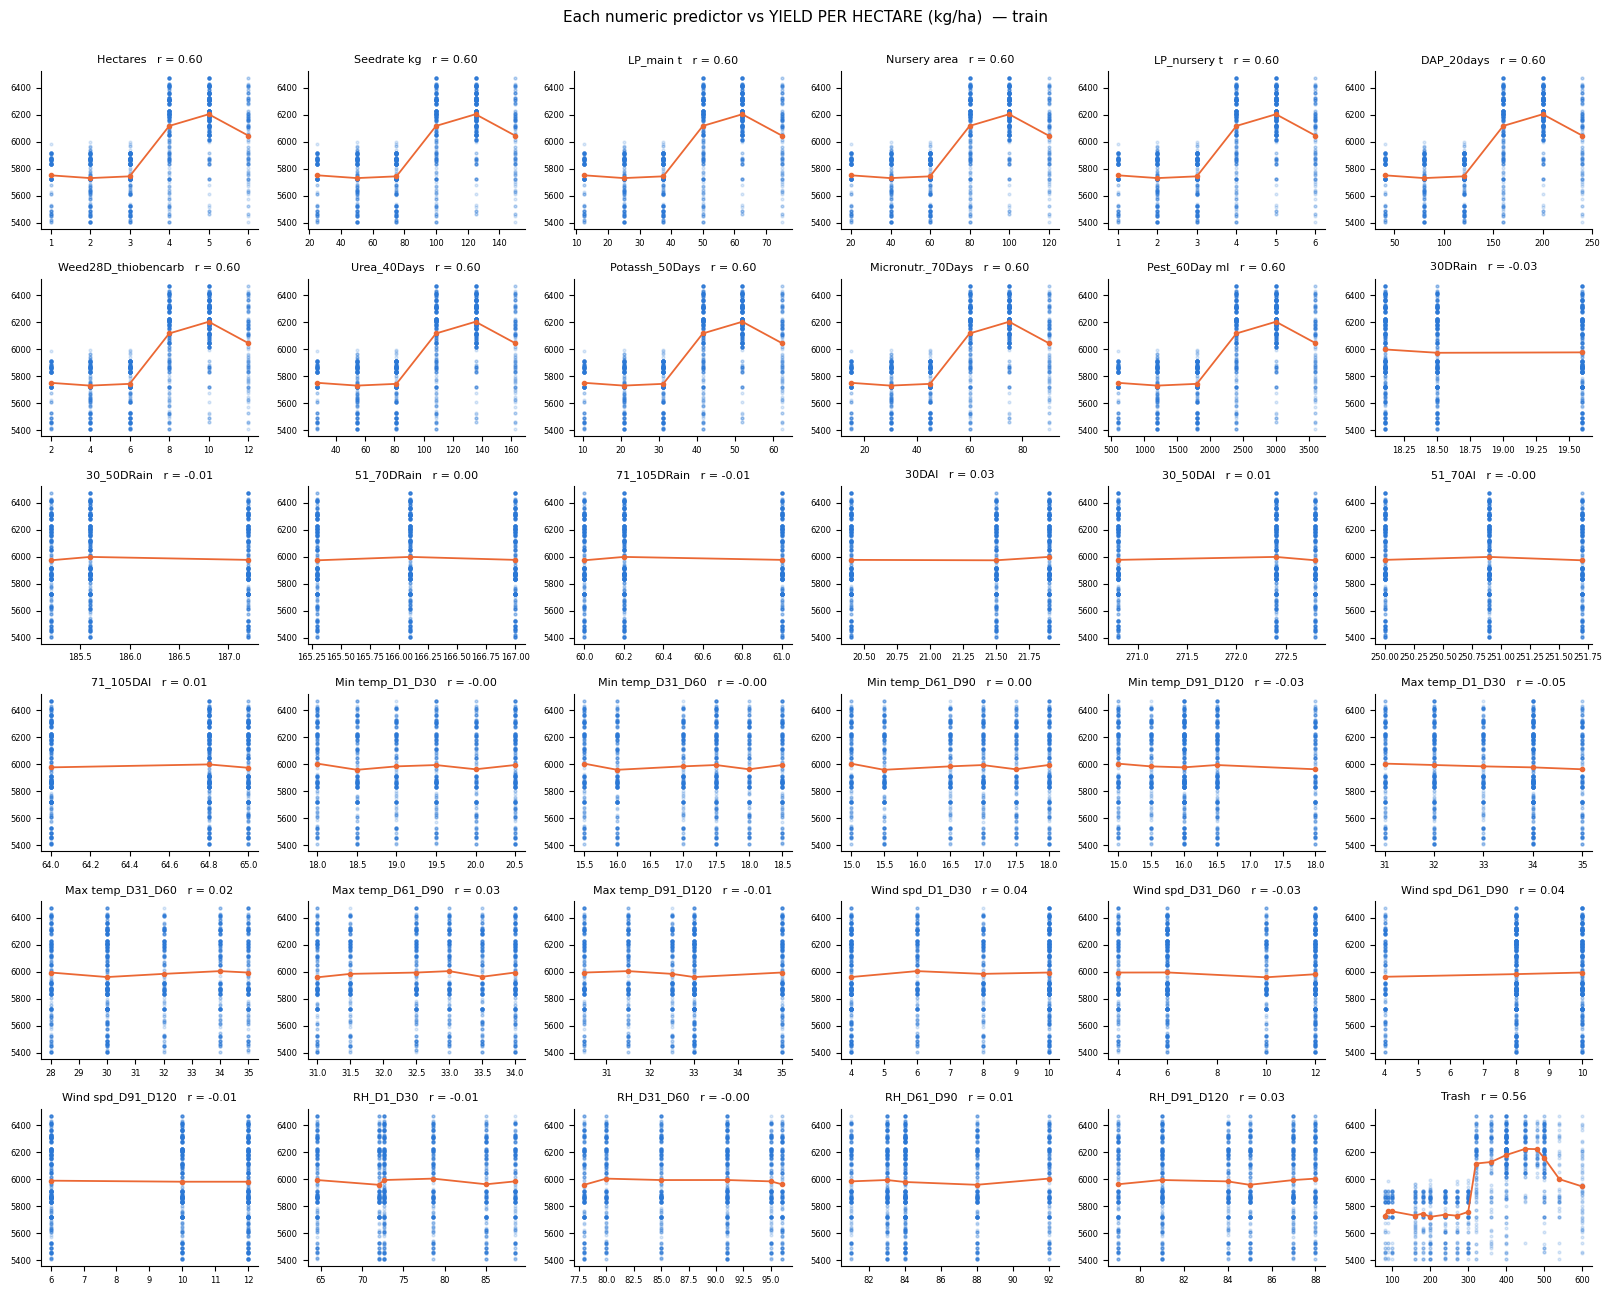

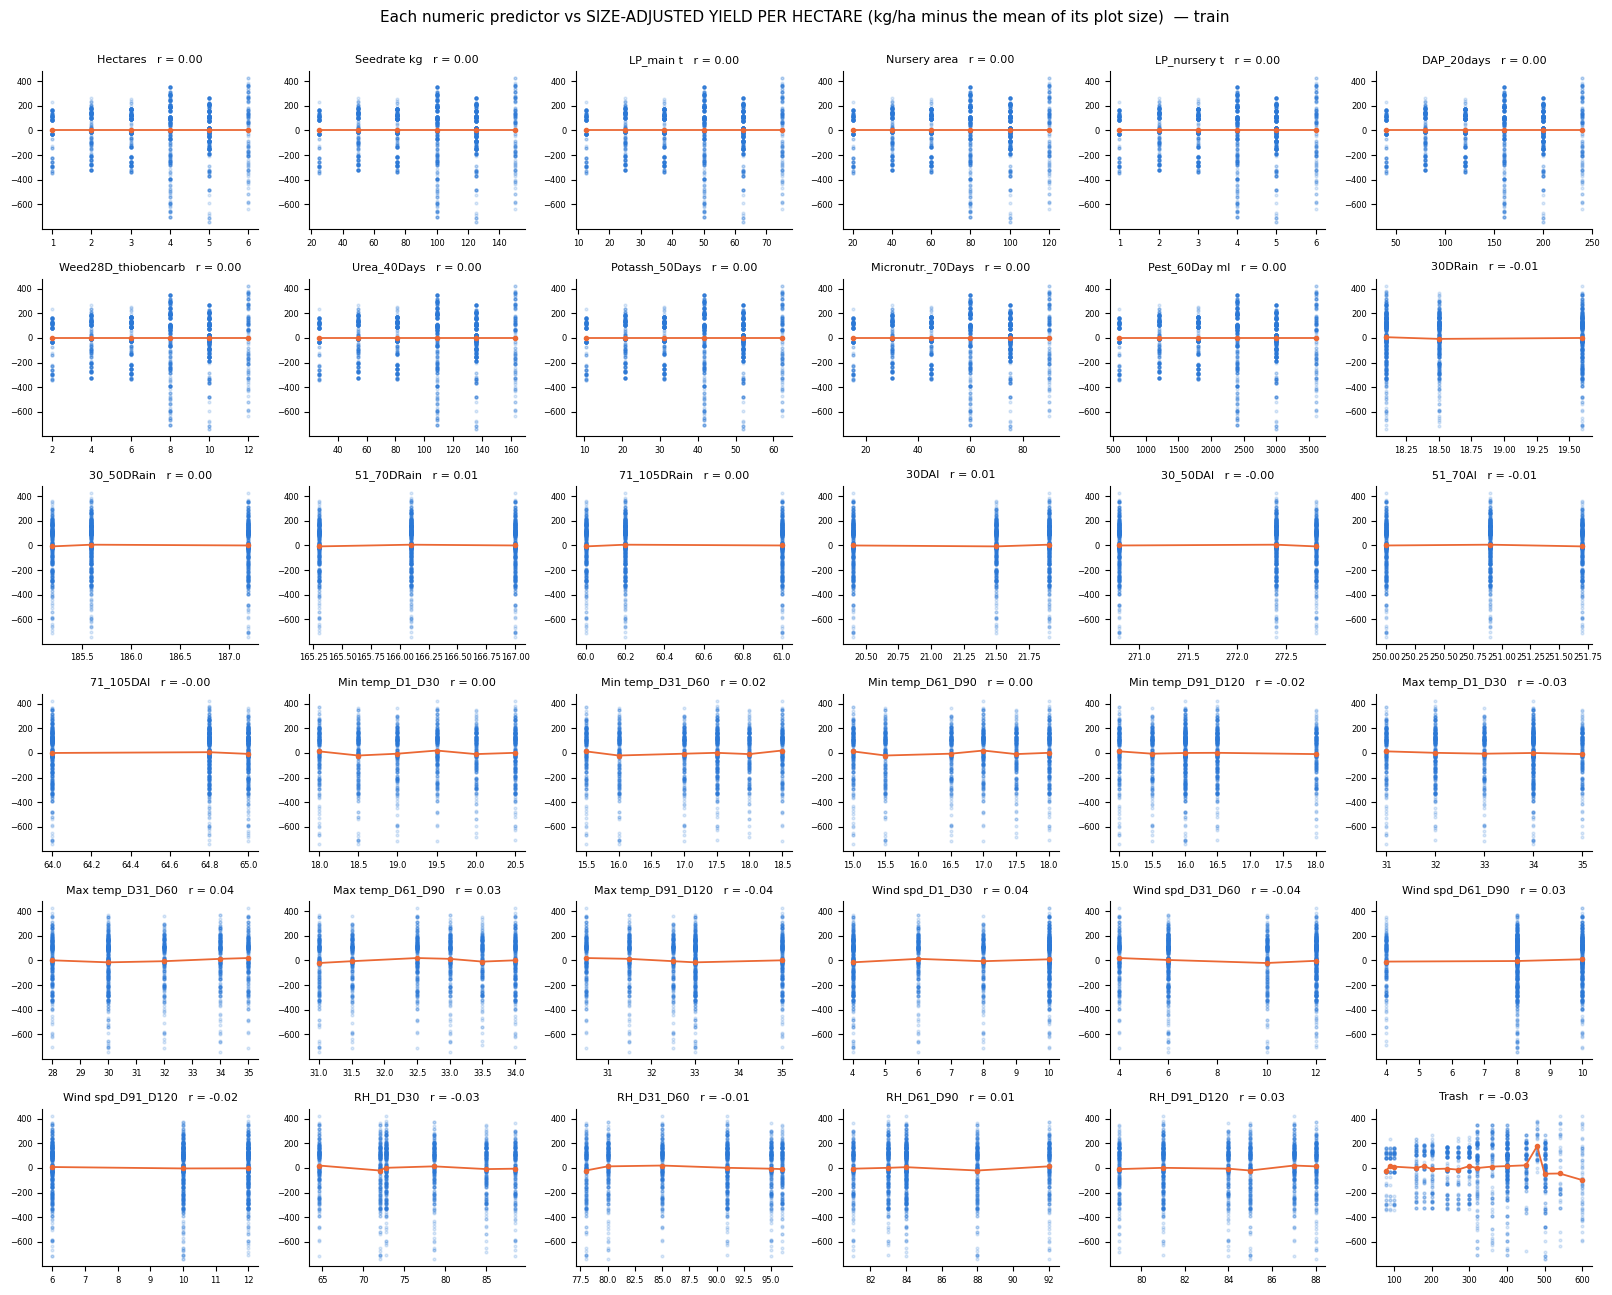

In [25]:
# yield/ha ที่ปรับตามขนาด: ลบด้วยค่าเฉลี่ย yield/ha ของ TRAIN ที่ขนาดแปลงเดียวกัน (กำจัด effect "nuisance" ของขนาดแปลงที่อธิบายไว้ข้างต้น)
size_mean = tr.groupby('Hectares')[Y2].mean()
tr['Yha adj'] = tr[Y2] - tr['Hectares'].map(size_mean)
Y3 = 'Yha adj'
scatter_grid(Y2, 'Each numeric predictor vs YIELD PER HECTARE (kg/ha)  — train')
scatter_grid(Y3, 'Each numeric predictor vs SIZE-ADJUSTED YIELD PER HECTARE (kg/ha minus the mean of its plot size)  — train')

### 8.2 การวิเคราะห์เชิงสถิติ
| เครื่องมือ | วัดอะไร | Assumptions / ข้อจำกัด |
|---|---|---|
| **Pearson r** (+ p-value, t-test ของ H0: ρ = 0) | ความสัมพันธ์ *เชิงเส้น* | ความสัมพันธ์เป็นเส้นตรง, ไม่มี outlier ที่มีอิทธิพล, ประมาณ bivariate normal สำหรับ p-value, แถวเป็นอิสระ ส่วน linear F-test (`f_regression`) เป็นฟังก์ชัน monotone ของ r² จึงไม่ให้ข้อมูลเพิ่ม |
| **Spearman ρ** | ความสัมพันธ์ *เชิง monotonic* (อิงอันดับ) | ความสัมพันธ์ต้อง monotonic; ในที่นี้มี ties เยอะ (level น้อย) |
| **Mutual information** (Ch02, หน่วย nats) | dependency *ทุกรูปแบบ*, ≥ 0, ไม่มี p-value | ต้องระบุว่า feature เป็น discrete/continuous (ในที่นี้ถือว่า discrete ทุกคอลัมน์: ≤ 17 levels); เป็นการจัดอันดับ ไม่ใช่การทดสอบ เพื่อให้รู้ว่า "เล็ก" แปลว่าอะไร เราคำนวณ **noise floor**: เปอร์เซ็นไทล์ที่ 95 ของค่า MI ที่ได้เมื่อสุ่มสลับ target (30 permutations) |
| Multiple testing | 36 tests → บางตัวได้ p < 0.05 โดยบังเอิญ | **Bonferroni** α = 0.05 / 36 = 0.0014 |
| กฎ effect-size | ด้วย n = 1,636 แม้แต่ r = 0.05 ก็ "significant" | จึงกำหนดเพิ่มว่าต้อง **|r| ≥ 0.10** (เกณฑ์ "small" ของ Cohen) ด้วย |

In [26]:
Xn = tr[NUM].values
rng = np.random.default_rng(SEED)
def mi_all(y): return mutual_info_regression(Xn, y, discrete_features=True, random_state=SEED)
floor = {t: np.percentile(np.array([mi_all(rng.permutation(tr[t].values)) for _ in range(30)]), 95, axis=0) for t in (Y, Y2, Y3)}
rows = []
for j, c in enumerate(NUM):
    x = tr[c].values; r1, p1 = stats.pearsonr(x, tr[Y]); r2, p2 = stats.pearsonr(x, tr[Y2]); r3, p3 = stats.pearsonr(x, tr[Y3])
    rows.append((c, r1, p1, stats.spearmanr(x, tr[Y])[0], r2, p2, stats.spearmanr(x, tr[Y2])[0], r3, p3))
ct_tab = pd.DataFrame(rows, columns=['feature', 'r_Y', 'p_Y', 'rho_Y', 'r_Yha', 'p_Yha', 'rho_Yha', 'r_adj', 'p_adj']).set_index('feature')
ct_tab['MI_Y'] = mi_all(tr[Y].values); ct_tab['MI_Y_floor'] = floor[Y]; ct_tab['MI_Yha'] = mi_all(tr[Y2].values); ct_tab['MI_Yha_floor'] = floor[Y2]
ct_tab['MI_adj'] = mi_all(tr[Y3].values); ct_tab['MI_adj_floor'] = floor[Y3]
ct_tab = ct_tab.reindex(ct_tab.r_Y.abs().sort_values(ascending=False).index)
display(ct_tab)

,r_Y,p_Y,rho_Y,r_Yha,p_Yha,rho_Yha,r_adj,p_adj,MI_Y,MI_Y_floor,MI_Yha,MI_Yha_floor,MI_adj,MI_adj_floor
feature,,,,,,,,,,,,,,
Seedrate(in Kg),0.9946,0,0.9777,0.601,3.18e-161,0.6068,2.29e-16,1,1.6994,0.022,0.4334,0.0308,1.2695,0.0325
LP_Mainfield(in Tonnes),0.9946,0,0.9777,0.601,3.18e-161,0.6068,2.29e-16,1,1.6994,0.022,0.4334,0.0308,1.2695,0.0325
Micronutrients_70Days,0.9946,0,0.9777,0.601,3.18e-161,0.6068,2.45e-16,1,1.6994,0.022,0.4334,0.0308,1.2695,0.0325
Potassh_50Days,0.9946,0,0.9777,0.601,3.18e-161,0.6068,2.56e-16,1,1.6994,0.022,0.4334,0.0308,1.2695,0.0325
Pest_60Day(in ml),0.9946,0,0.9777,0.601,3.18e-161,0.6068,2.40e-16,1,1.6994,0.022,0.4334,0.0308,1.2695,0.0325
Urea_40Days,0.9946,0,0.9777,0.601,3.18e-161,0.6068,2.23e-16,1,1.6994,0.022,0.4334,0.0308,1.2695,0.0325
DAP_20days,0.9946,0,0.9777,0.601,3.18e-161,0.6068,2.32e-16,1,1.6994,0.022,0.4334,0.0308,1.2695,0.0325
Nursery area (Cents),0.9946,0,0.9777,0.601,3.18e-161,0.6068,2.32e-16,1,1.6994,0.022,0.4334,0.0308,1.2695,0.0325
Hectares,0.9946,0,0.9777,0.601,3.18e-161,0.6068,2.59e-16,1,1.6994,0.022,0.4334,0.0308,1.2695,0.0325


In [27]:
# ---- audit ผู้ต้องสงสัย leakage `Trash`: มันให้ข้อมูลเกินกว่าขนาดแปลงหรือไม่? ----
h = tr[['Hectares']]
def resid(v): return v - LinearRegression().fit(h, v).predict(h)
print(f"corr(Trash, yield)                                   = {tr[TRASH].corr(tr[Y]):.3f}   <- looks like a superb predictor")
print(f"corr(Trash, Hectares)                                = {tr[TRASH].corr(tr['Hectares']):.3f}   <- because both simply scale with plot size")
print(f"partial corr(Trash, yield | Hectares)                = {np.corrcoef(resid(tr[TRASH]), resid(tr[Y]))[0,1]:.3f}")
print(f"partial corr(Trash, yield per ha | Hectares, LINEAR)  = {np.corrcoef(resid(tr[TRASH]), resid(tr[Y2]))[0,1]:.3f}   <- size handled linearly only")
_r, _p = stats.pearsonr(tr[TRASH], tr[Y3])
print(f"corr(Trash, size-adjusted yield per ha)              = {_r:.3f}  (p = {_p:.2f})   <- size handled as 6 levels: nothing is left")
print('corr(Trash, yield per ha) inside each plot size:', {int(k): round(v, 2) for k, v in tr.groupby('Hectares').apply(lambda g: g[TRASH].corr(g[Y2])).items()})
print('Trash per hectare takes the values', sorted((tr[TRASH] / tr.Hectares).unique()))

corr(Trash, yield)                                   = 0.958   <- looks like a superb predictor
corr(Trash, Hectares)                                = 0.968   <- because both simply scale with plot size
partial corr(Trash, yield | Hectares)                = -0.164
partial corr(Trash, yield per ha | Hectares, LINEAR)  = -0.128   <- size handled linearly only
corr(Trash, size-adjusted yield per ha)              = -0.033  (p = 0.19)   <- size handled as 6 levels: nothing is left
corr(Trash, yield per ha) inside each plot size: {1: 0.09, 2: -0.03, 3: 0.05, 4: -0.01, 5: -0.2, 6: -0.44}
Trash per hectare takes the values [80.0, 90.0, 100.0]


In [28]:
# ---- 8.3 สรุป continuous features ----
alpha_b = 0.05 / len(NUM)
def family(c):
    return ('size & inputs' if c == 'Hectares' or c in INPUTS else 'rain' if c in RAIN else 'AI' if c in AI else 'min temp' if c in TMIN else 'max temp' if c in TMAX
            else 'wind speed' if c in WIND else 'humidity' if c in RH else 'Trash (leak suspect)')
def decide(c):
    t = ct_tab.loc[c]
    if c == TRASH: return 'REJECT', 'leakage: harvest by-product (§1.4); its correlation with yield comes only through plot size'
    sig = lambda r, p: abs(r) >= 0.10 and p < alpha_b
    sigY, sigH, sigA = sig(t.r_Y, t.p_Y), sig(t.r_Yha, t.p_Yha), sig(t.r_adj, t.p_adj)
    miY, miH, miA = t.MI_Y > t.MI_Y_floor, t.MI_Yha > t.MI_Yha_floor, t.MI_adj > t.MI_adj_floor
    if sigY or sigH or sigA: return 'KEEP (candidate)', f"|r| >= 0.10 and p < {alpha_b:.4f} for " + ' / '.join(n for n, f in [('raw yield', sigY), ('yield/ha', sigH), ('size-adjusted yield/ha', sigA)] if f)
    if miY or miH or miA: return 'WEAK', 'MI above the noise floor but no linear/monotonic effect'
    return 'REJECT', 'no detectable linear, monotonic or MI relationship with any of the three targets'
summ = pd.DataFrame({c: (family(c),) + decide(c) for c in NUM}, index=['family', 'decision', 'reason']).T
summ['r_Y'] = ct_tab.r_Y; summ['r_Yha'] = ct_tab.r_Yha; summ['r_adj'] = ct_tab.r_adj
display(summ.sort_values(['decision', 'family']))
print(summ.groupby(['family', 'decision']).size().unstack(fill_value=0))

,family,decision,reason,r_Y,r_Yha,r_adj
Hectares,size & inputs,KEEP (candidate),|r| >= 0.10 and p < 0.0014 for raw yield / yie...,0.9946,0.601,2.59e-16
Seedrate(in Kg),size & inputs,KEEP (candidate),|r| >= 0.10 and p < 0.0014 for raw yield / yie...,0.9946,0.601,2.29e-16
LP_Mainfield(in Tonnes),size & inputs,KEEP (candidate),|r| >= 0.10 and p < 0.0014 for raw yield / yie...,0.9946,0.601,2.29e-16
Nursery area (Cents),size & inputs,KEEP (candidate),|r| >= 0.10 and p < 0.0014 for raw yield / yie...,0.9946,0.601,2.32e-16
LP_nurseryarea(in Tonnes),size & inputs,KEEP (candidate),|r| >= 0.10 and p < 0.0014 for raw yield / yie...,0.9946,0.601,2.59e-16
DAP_20days,size & inputs,KEEP (candidate),|r| >= 0.10 and p < 0.0014 for raw yield / yie...,0.9946,0.601,2.32e-16
Weed28D_thiobencarb,size & inputs,KEEP (candidate),|r| >= 0.10 and p < 0.0014 for raw yield / yie...,0.9946,0.601,2.59e-16
Urea_40Days,size & inputs,KEEP (candidate),|r| >= 0.10 and p < 0.0014 for raw yield / yie...,0.9946,0.601,2.23e-16
Potassh_50Days,size & inputs,KEEP (candidate),|r| >= 0.10 and p < 0.0014 for raw yield / yie...,0.9946,0.601,2.56e-16
Micronutrients_70Days,size & inputs,KEEP (candidate),|r| >= 0.10 and p < 0.0014 for raw yield / yie...,0.9946,0.601,2.45e-16


decision              KEEP (candidate)  REJECT
family                                        
AI                                   0       4
Trash (leak suspect)                 0       1
humidity                             0       4
max temp                             0       4
min temp                             0       4
rain                                 0       4
size & inputs                       11       0
wind speed                           0       4


### 8.3 อภิปราย — การคัดเลือก continuous features
**พบ features 2 กลุ่มที่แตกต่างกันมาก**

**(a) `Hectares` และคอลัมน์ input อีก 10 ตัว (`Seedrate`, `LP_Mainfield`, `Nursery area`, `LP_nurseryarea`, `DAP_20days`, `Weed28D_thiobencarb`, `Urea_40Days`, `Potassh_50Days`, `Micronutrients_70Days`, `Pest_60Day`)** ทั้ง 11 ตัวมี **r = 0.9946 กับ raw yield** (p รายงานเป็น 0 คือต่ำกว่าความละเอียดของ floating point) และ **r = 0.601 กับ yield/ha** (p = 3·10⁻¹⁶¹) — เหมือนกันถึงทศนิยม 4 ตำแหน่ง เพราะ (พิสูจน์ใน §10) แต่ละตัวเป็นพหุคูณที่แน่นอนของ `Hectares` เมื่อเทียบกับ target ที่ **ปรับตามขนาด** แล้ว ทุกตัวมี r ≈ 2×10⁻¹⁶ (เป็นศูนย์เชิงตัวเลข, p = 1): เมื่อเอาระดับของขนาดแปลงออกก็ *ไม่เหลืออะไร* ให้ correlate ซึ่งตรงกับที่ "พหุคูณที่แน่นอนของ Hectares" ทำนายไว้พอดี ทั้ง 11 ตัวผ่านกฎ |r| ≥ 0.10 & Bonferroni และได้สถานะ **KEEP (candidate)** — แต่ §10 แสดงว่าควรมีเพียง *ตัวเดียว* เท่านั้นที่เข้าโมเดล

**(b) คอลัมน์สภาพอากาศ 24 ตัว + `Trash`** correlation ของสภาพอากาศทุกตัวกับทุก target มีค่าเล็ก (|r| ≤ 0.05) และ **ไม่มีนัยสำคัญแม้ก่อนแก้ค่าสำหรับ 36 tests** (p ต่ำสุด = 0.065) `Trash` ดูเหมือนเป็น predictor ที่ยอดเยี่ยมของ raw yield (r = 0.958) — จนกระทั่งควบคุม `Hectares`: **partial correlation พลิกเครื่องหมายและหดเหลือ −0.16** และเมื่อเทียบกับ target ที่ **ปรับตามขนาด** ได้ **r = −0.03, p = 0.19** — ไม่มีนัยสำคัญ นี่คือการยืนยัน *เชิงประจักษ์* ของการตัดสินใจเรื่อง leakage ใน §1.4: พลังที่ดูเหมือนมีของ `Trash` เป็นเพียงตัวแทนของขนาดแปลงล้วน ๆ ไม่ใช่ข้อมูลใหม่

**รายละเอียดที่ให้บทเรียนเกี่ยวกับ mutual information** ทั้ง `Trash` และกลุ่ม size/input มี **MI สูงกว่า noise floor มากเมื่อเทียบกับ target ที่ปรับตามขนาด ทั้งที่ correlation ≈ 0** (เช่น MI_adj = 1.27 nats สำหรับกลุ่ม size/input, floor 0.03) นี่ไม่ใช่ความขัดแย้ง: Pearson r และ linear F-test เห็นเพียง *การเลื่อนของค่าเฉลี่ย*; ส่วน MI เห็น **การเปลี่ยนของการกระจาย** ด้วย §4 และ §6 แสดงไปแล้วว่าความแปรปรวนของ residual/target ใหญ่กว่าในแปลงขนาดใหญ่สุด (heteroscedasticity) — MI กำลังจับ dependency ใน *ความแปรปรวน* นั้นพอดี ซึ่งเป็นสิ่งที่สัมประสิทธิ์ของ linear regression ใช้ทำนายค่าเฉลี่ยไม่ได้ ตรงกับสไลด์ Ch02 *"F-test จับได้เฉพาะ linear dependency … mutual information จับ dependency ได้ทุกรูปแบบ"* **ผลต่อการตัดสินใจ:** มัน **ไม่** เปลี่ยนว่าจะเก็บ feature ใดไว้สำหรับการทำนายค่าจุด (สัญญาณที่มีแต่ MI ไม่มี mean effect ให้ใช้ประโยชน์) แต่มันเป็นเหตุผลที่สองที่เป็นอิสระว่าทำไม `Hectares` ต้องอยู่ในโมเดล — เพื่อโครงสร้างความแปรปรวนของ residual ไม่ใช่แค่ค่าเฉลี่ย (ใช้อีกครั้งใน §14 ตอนเลือกระหว่างโมเดล raw กับ log yield)

**บทสรุปของ §8** มี **กลุ่ม continuous เพียงกลุ่มเดียวที่มีสัญญาณ คือขนาดแปลง** ซึ่งตอนนี้ยังแทนด้วยคอลัมน์ที่ collinear สมบูรณ์ทั้ง 11 ตัว; §10 จะลดเหลือ `Hectares` ตัวเดียว **ไม่มีคอลัมน์สภาพอากาศใด และไม่มี `Trash`** ถูกเก็บไว้ในโมเดลสุดท้าย

# 9 · Feature selection — categorical features  *(rubrics 9, 10, 11)*
### 9.1 การวิเคราะห์เชิงภาพ — box-plots ของ target แยกตาม category
ถ้ากล่องอยู่ที่ระดับความสูงต่างกัน แปลว่า category นั้นสำคัญ; ถ้ากล่องเหมือนกันแปลว่าไม่สำคัญ มี 3 รูป: raw yield, yield ต่อเฮกตาร์ และ yield ต่อเฮกตาร์ที่ปรับตามขนาดแล้ว

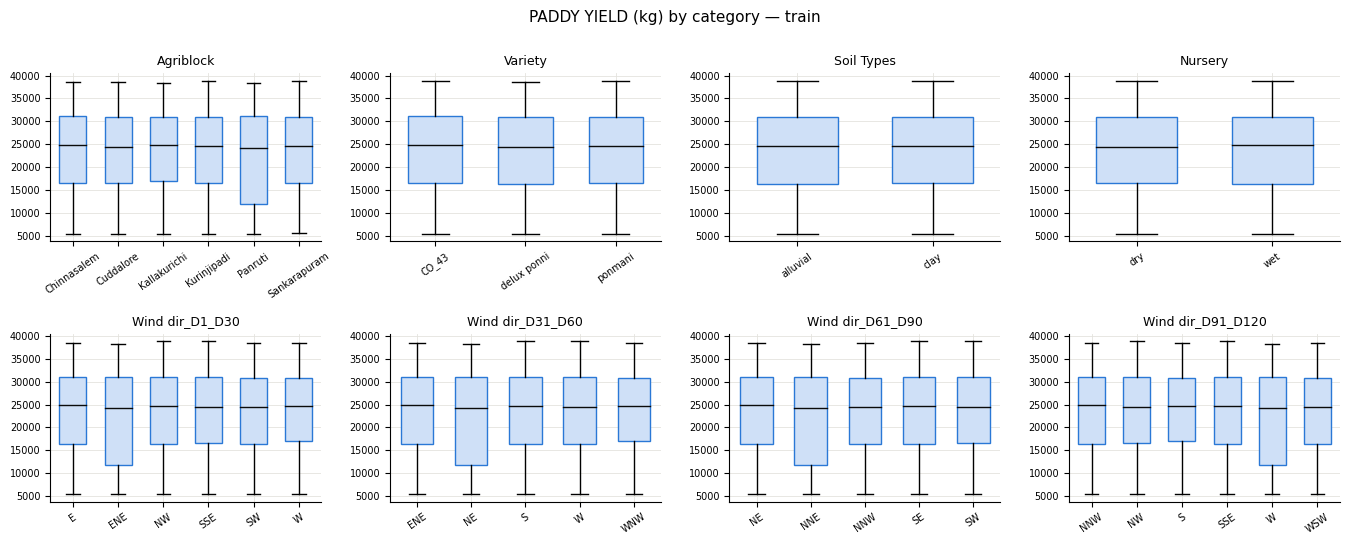

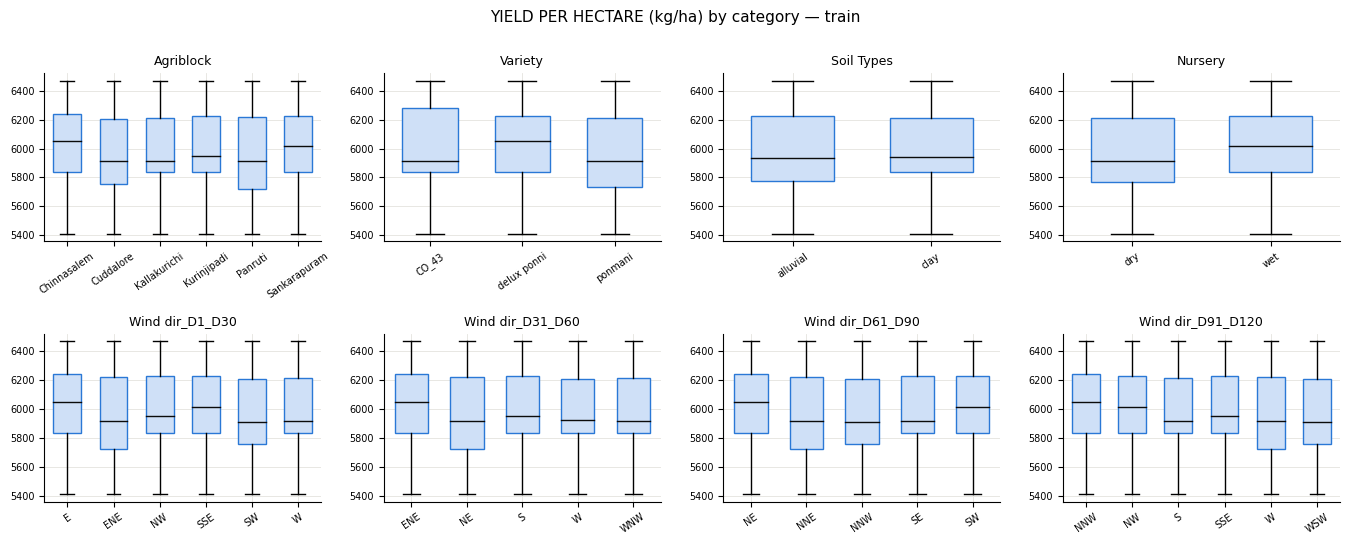

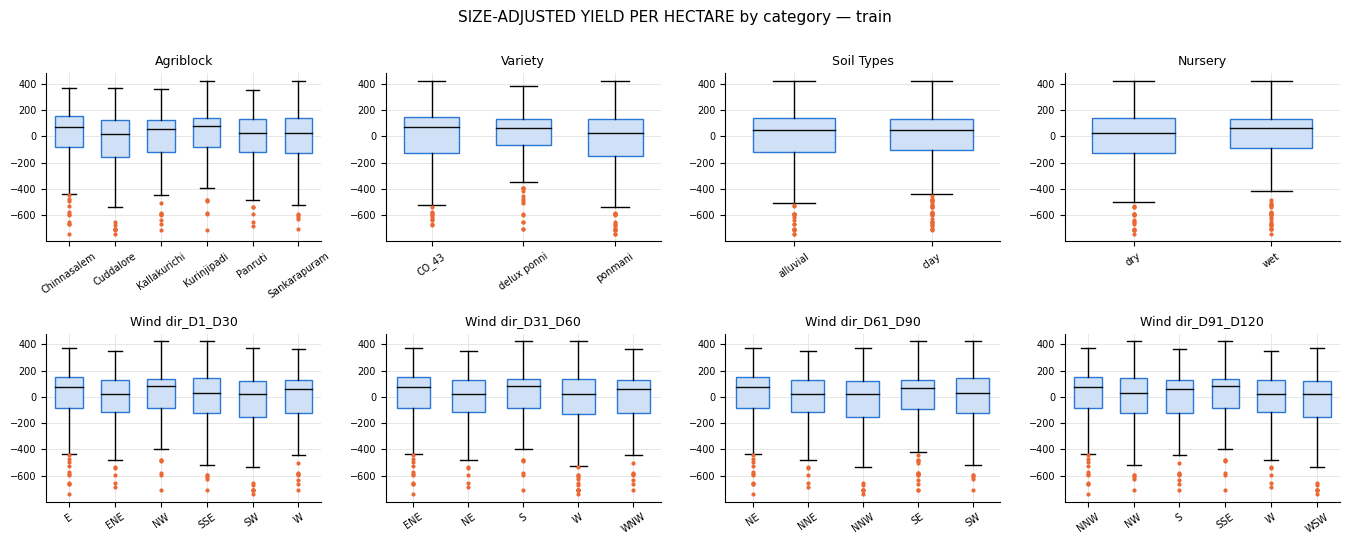

In [29]:
def box_by_cat(target, ttl):
    fig, ax = grid(len(CAT), 4, 3.4, 2.7)
    for a, c in zip(ax, CAT):
        lv = sorted(tr[c].unique()); a.boxplot([tr.loc[tr[c] == l, target] for l in lv], labels=lv, whis=1.5, patch_artist=True, widths=.6,
                boxprops=dict(facecolor='#cfe0f7', color=BLUE), medianprops=dict(color=INK), flierprops=dict(marker='o', ms=2, mfc=ORANGE, mec=ORANGE))
        a.set_title(short(c), fontsize=9); a.tick_params(axis='x', rotation=35, labelsize=7); a.tick_params(axis='y', labelsize=7)
    plt.suptitle(ttl, y=1.0, fontsize=11); plt.tight_layout(); plt.show()
box_by_cat(Y, 'PADDY YIELD (kg) by category — train'); box_by_cat(Y2, 'YIELD PER HECTARE (kg/ha) by category — train'); box_by_cat(Y3, 'SIZE-ADJUSTED YIELD PER HECTARE by category — train')

### 9.2 การวิเคราะห์เชิงสถิติ
| เครื่องมือ | คำถาม | Assumptions |
|---|---|---|
| **One-way ANOVA** ($F$ = variance ระหว่างกลุ่ม / variance ภายในกลุ่ม; H0: ค่าเฉลี่ยทุกกลุ่มเท่ากัน) | ค่าเฉลี่ยของ target ต่างกันระหว่าง category หรือไม่? (categorical feature → target แบบ **continuous** จึงเป็นเครื่องมือที่ถูกต้อง) | (1) residuals ภายในกลุ่ม ≈ normal, (2) variance เท่ากันทุกกลุ่ม, (3) observations เป็นอิสระ ตรวจสอบด้านล่างด้วย **Shapiro–Wilk** (ความ normal ของ residual ภายในกลุ่มรวม) และ **Levene** (ความเท่ากันของ variance) ในกรณีที่ Levene reject จะรายงานการทดสอบ **Alexander–Govern** ที่ทนต่อ heteroscedasticity (`AlexGovern_p`) เป็นการตรวจสอบไขว้ ด้วย n = 1,636 และขนาดกลุ่มใกล้เคียงกัน ANOVA ทนต่อการละเมิดเล็กน้อย |
| **η²** (= SS_between / SS_total) | category อธิบาย variance ได้ *มากแค่ไหน* | เชิงพรรณนา |
| **Chi-square test of independence** | category สัมพันธ์กับ target หรือไม่? ต้องการให้ตัวแปร *ทั้งคู่* เป็น categorical → จึงตัด target เป็น **4 quantile bins** (เรียน bin จาก train) | แถวเป็นอิสระ; **expected counts ≥ 5** (ตรวจแล้ว: มีการพิมพ์ค่า expected count ต่ำสุด); Cramér's V = effect size |
| **Mutual information** | dependency ทุกรูปแบบ | จัดอันดับเท่านั้น; noise floor จากการสลับ label 30 ครั้ง |
| Bonferroni | 8 tests ต่อ target | α = 0.05 / 8 = 0.00625 |

`assoc_Hectares` (Cramér's V ระหว่าง category กับขนาดแปลง) เป็น **การตรวจ confounding**: ถ้า category สัมพันธ์กับขนาดแปลง ANOVA บน raw yield จะปนผลของ category เข้ากับผลของขนาด

In [30]:
def eta2(groups):
    allv = np.concatenate(groups); gm = allv.mean()
    return sum(len(g) * (g.mean() - gm)**2 for g in groups) / ((allv - gm)**2).sum()
def cat_table(t):
    rows = {}; rng = np.random.default_rng(SEED)
    for c in CAT:
        groups = [g[t].values for _, g in tr.groupby(c)]; F, p = stats.f_oneway(*groups)
        res = np.concatenate([g - g.mean() for g in groups]); ctab = pd.crosstab(tr[c], pd.qcut(tr[t], 4, duplicates='drop'))
        chi2, pc, dof, exp = stats.chi2_contingency(ctab)
        code = pd.factorize(tr[c])[0].reshape(-1, 1)
        mi = mutual_info_regression(code, tr[t].values, discrete_features=True, random_state=SEED)[0]
        fl = np.percentile([mutual_info_regression(code, rng.permutation(tr[t].values), discrete_features=True, random_state=SEED)[0] for _ in range(30)], 95)
        rows[c] = dict(levels=len(groups), F=F, p_ANOVA=p, eta2=eta2(groups), Shapiro_p=stats.shapiro(res)[1], Levene_p=stats.levene(*groups)[1], AlexGovern_p=stats.alexandergovern(*groups).pvalue,
                       chi2_p=pc, CramerV=np.sqrt(chi2 / (ctab.values.sum() * (min(ctab.shape) - 1))), min_expected=exp.min(), MI=mi, MI_floor=fl,
                       assoc_Hectares=cramers_v(tr[c], tr.Hectares))
    return pd.DataFrame(rows).T
cat_Y, cat_Yha, cat_adj = cat_table(Y), cat_table(Y2), cat_table(Y3)
print('A) categorical features vs PADDY YIELD (kg)'); display(cat_Y)
print('B) categorical features vs YIELD PER HECTARE (kg/ha)'); display(cat_Yha)
print('C) categorical features vs SIZE-ADJUSTED YIELD PER HECTARE (plot-size effect removed)'); display(cat_adj)

A) categorical features vs PADDY YIELD (kg)


,levels,F,p_ANOVA,eta2,Shapiro_p,Levene_p,AlexGovern_p,chi2_p,CramerV,min_expected,MI,MI_floor,assoc_Hectares
Agriblock,6,0.5038,0.7736,0.0015,1.65e-25,0.6249,0.7705,0.9506,0.0384,56.5954,0.0025,0.0245,0.047
Variety,3,0.1664,0.8467,0.0002,4.20e-26,0.7243,0.848,0.6919,0.0345,103.7983,0.0122,0.015,0.0279
Soil Types,2,0.0874,0.7676,5.35e-05,3.66e-26,0.6553,0.768,0.9017,0.0188,179.901,0,0.0245,0.033
Nursery,2,0.5517,0.4577,0.0003,5.43e-26,0.958,0.4585,0.4243,0.0413,177.4927,0,0.0159,0.0636
Wind Direction_D1_D30,6,0.5038,0.7736,0.0015,1.65e-25,0.6249,0.7705,0.9506,0.0384,56.5954,0.0025,0.0259,0.047
Wind Direction_D31_D60,5,0.346,0.847,0.0008,9.32e-26,0.5416,0.8578,0.9116,0.0352,56.5954,0.0126,0.0202,0.0432
Wind Direction_D61_D90,5,0.6117,0.6543,0.0015,1.48e-25,0.5627,0.6506,0.8733,0.0371,56.5954,0,0.0219,0.0468
Wind Direction_D91_D120,6,0.5038,0.7736,0.0015,1.65e-25,0.6249,0.7705,0.9506,0.0384,56.5954,0.0025,0.0288,0.047


B) categorical features vs YIELD PER HECTARE (kg/ha)


,levels,F,p_ANOVA,eta2,Shapiro_p,Levene_p,AlexGovern_p,chi2_p,CramerV,min_expected,MI,MI_floor,assoc_Hectares
Agriblock,6,1.1034,0.3566,0.0034,7.18e-21,0.6362,0.3698,0.3998,0.0566,51.8551,0,0.0267,0.047
Variety,3,3.4724,0.0313,0.0042,1.56e-20,0.332,0.0298,0.0002,0.089,95.1045,0.0357,0.0262,0.0279
Soil Types,2,0.0001,0.9917,6.63e-08,1.39e-21,0.9017,0.9917,0.8547,0.0218,164.8331,0.0013,0.0173,0.033
Nursery,2,2.2189,0.1365,0.0014,5.52e-21,0.4749,0.1369,0.2434,0.0505,162.6265,0.0049,0.0113,0.0636
Wind Direction_D1_D30,6,1.1034,0.3566,0.0034,7.18e-21,0.6362,0.3698,0.3998,0.0566,51.8551,0,0.0221,0.047
Wind Direction_D31_D60,5,0.8001,0.5251,0.002,4.67e-21,0.5937,0.5412,0.3899,0.0509,51.8551,0.0043,0.0272,0.0432
Wind Direction_D61_D90,5,1.3418,0.2521,0.0033,7.36e-21,0.6136,0.2633,0.3424,0.0522,51.8551,0,0.0158,0.0468
Wind Direction_D91_D120,6,1.1034,0.3566,0.0034,7.18e-21,0.6362,0.3698,0.3998,0.0566,51.8551,0,0.0233,0.047


C) categorical features vs SIZE-ADJUSTED YIELD PER HECTARE (plot-size effect removed)


,levels,F,p_ANOVA,eta2,Shapiro_p,Levene_p,AlexGovern_p,chi2_p,CramerV,min_expected,MI,MI_floor,assoc_Hectares
Agriblock,6,1.4891,0.1902,0.0045,1.68e-25,0.5801,0.1998,0.4459,0.0554,57.4572,0.0102,0.0282,0.047
Variety,3,6.5693,0.0014,0.008,6.47e-25,0.0001,0.0014,0.0033,0.0773,105.379,0.0003,0.0174,0.0279
Soil Types,2,0.0359,0.8498,2.20e-05,8.48e-26,0.5693,0.8501,0.4698,0.0393,182.6406,0,0.0171,0.033
Nursery,2,0.6077,0.4358,0.0004,9.56e-26,0.3357,0.4358,0.2706,0.0489,180.1956,0,0.014,0.0636
Wind Direction_D1_D30,6,1.4891,0.1902,0.0045,1.68e-25,0.5801,0.1998,0.4459,0.0554,57.4572,0.0102,0.0257,0.047
Wind Direction_D31_D60,5,1.4072,0.2291,0.0034,1.43e-25,0.4873,0.2089,0.2868,0.0538,57.4572,0.0273,0.0322,0.0432
Wind Direction_D61_D90,5,1.3218,0.2596,0.0032,1.45e-25,0.4973,0.2988,0.3874,0.051,57.4572,0,0.0215,0.0468
Wind Direction_D91_D120,6,1.4891,0.1902,0.0045,1.68e-25,0.5801,0.1998,0.4459,0.0554,57.4572,0.0102,0.0223,0.047


In [31]:
# ---- 9.3 สรุป categorical features ----
alpha_c = 0.05 / len(CAT)
def decide_cat(c):
    tabs = {'raw yield': cat_Y.loc[c], 'yield/ha': cat_Yha.loc[c], 'adjusted yield/ha': cat_adj.loc[c]}
    hit = [n for n, t in tabs.items() if t.p_ANOVA < alpha_c]; near = [n for n, t in tabs.items() if t.p_ANOVA < 0.05 or t.chi2_p < alpha_c or t.MI > t.MI_floor]
    b = cat_adj.loc[c]
    if hit: return 'KEEP (small effect)', f"ANOVA significant after Bonferroni for {', '.join(hit)}; eta2={b.eta2:.4f} (tiny effect size)"
    if near: return 'WEAK', 'nominal evidence only (p<0.05, chi-square or MI above floor) but not after Bonferroni'
    return 'REJECT', 'no significant difference between categories for any of the three targets'
sc = pd.DataFrame({c: decide_cat(c) for c in CAT}, index=['decision', 'reason']).T
sc['p_ANOVA_Y'] = cat_Y.p_ANOVA; sc['p_ANOVA_Yha'] = cat_Yha.p_ANOVA; sc['p_ANOVA_adj'] = cat_adj.p_ANOVA; sc['eta2_adj'] = cat_adj.eta2
display(sc)

,decision,reason,p_ANOVA_Y,p_ANOVA_Yha,p_ANOVA_adj,eta2_adj
Agriblock,REJECT,no significant difference between categories f...,0.7736,0.3566,0.1902,0.0045
Variety,KEEP (small effect),ANOVA significant after Bonferroni for adjuste...,0.8467,0.0313,0.0014,0.008
Soil Types,REJECT,no significant difference between categories f...,0.7676,0.9917,0.8498,2.20e-05
Nursery,REJECT,no significant difference between categories f...,0.4577,0.1365,0.4358,0.0004
Wind Direction_D1_D30,REJECT,no significant difference between categories f...,0.7736,0.3566,0.1902,0.0045
Wind Direction_D31_D60,REJECT,no significant difference between categories f...,0.847,0.5251,0.2291,0.0034
Wind Direction_D61_D90,REJECT,no significant difference between categories f...,0.6543,0.2521,0.2596,0.0032
Wind Direction_D91_D120,REJECT,no significant difference between categories f...,0.7736,0.3566,0.1902,0.0045


### 9.3 อภิปราย — การคัดเลือก categorical features
**เชิงภาพ** box-plots ของ `Agriblock`, `Soil Types`, `Nursery` และ `Wind Direction` ทั้ง 4 ช่วง อยู่ที่ระดับความสูงเกือบเท่ากันและซ้อนทับกันมาก — ไม่มี category ใดโดดเด่น มีเพียง `Variety` ที่แสดงการเลื่อน (เล็กน้อย) ที่มองเห็นได้: `delux ponni` อยู่สูงกว่าเล็กน้อย

**เชิงสถิติ** ตัวเลขยืนยันภาพที่เห็น เมื่อเทียบกับ yield/ha ที่ **ปรับตามขนาด** มีเพียง `Variety` ที่รอด Bonferroni: ANOVA F = 6.57, p = 0.0014 (α = 0.00625) และ chi-square ก็เห็นตรงกัน (p = 0.0033) เนื่องจาก Levene's test ตั้งธงว่า variance ไม่เท่ากันสำหรับ `Variety` (p = 0.0001) — เป็นการละเมิด assumption — จึงรันการทดสอบ **Alexander–Govern** ที่ทนต่อ heteroscedasticity เป็นการตรวจสอบไขว้ และผล **สอดคล้องกัน** (p = 0.0014): ผลลัพธ์ไม่ได้เกิดจากการละเมิดนั้น คอลัมน์ categorical อื่นทุกตัวมี p > 0.19 ในทุก target ที่น่าสังเกตคือ **คอลัมน์ `Wind Direction` ทั้ง 4 ตัวถูก reject เหมือนกับ `Agriblock` เป๊ะ** (p-value เหมือนกันถึงเลขนัยสำคัญ 4 ตัว) — เป็นสิ่งที่คาดได้ เพราะ §10 แสดงว่าทิศทางลมคือการเปลี่ยนชื่อของ agri-block

**Effect size — ข้อควรระวังที่สำคัญที่สุด** η² ของ `Variety` คือ **0.008**: มันอธิบาย **0.8 %** ของ variance (ที่เล็กอยู่แล้วหลังปรับ) และ Cramér's V = 0.08 ด้วย n = 1,636 แม้ effect ที่เล็กจนแทบไม่มีความหมายในทางปฏิบัติก็ยังมีนัยสำคัญทางสถิติได้ — คำเตือนของ Guideline ใช้ได้ตรง ๆ ในที่นี้: "ถูกต้อง" ไม่เหมือนกับ "สำคัญ" `Variety` ถูกเก็บไว้เป็น **candidate ที่มี effect เล็ก แก้ต่างได้ทางสถิติ แต่มีนัยทางปฏิบัติน้อย**; จะถูกตัดสินอีกครั้งด้วยว่ามันช่วยปรับปรุง out-of-sample R² หรือไม่ใน §14

**บทสรุปของ §9** เก็บเฉพาะ `Variety`; `Agriblock`, `Soil Types`, `Nursery` และคอลัมน์ทิศทางลมทั้ง 4 ถูก **ตัดทิ้ง** เพราะตรวจไม่พบความสัมพันธ์ใด ๆ กับ target นอกเหนือจากเหตุผลเรื่องความซ้ำซ้อนที่จะพัฒนาต่อในหัวข้อถัดไป

# 10 · การวิเคราะห์ feature ที่ซ้ำซ้อน (Redundant features)  *(rubric 12 · Ch01 "little or no multicollinearity" · Ch02 "curse of dimensionality")*
Feature 2 ตัวที่ให้ข้อมูลเดียวกันทำให้ $X^\top X$ (เกือบ) เป็น singular: ผลเฉลยของ normal equation $\mathbf a=(X^\top X)^{-1}X^\top\mathbf y$ จะไม่เสถียรหรือหาไม่ได้ สัมประสิทธิ์ตีความไม่ได้ และพารามิเตอร์ "ส่วนเกิน" ก็เพิ่มความเสี่ยงของ over-fitting เท่านั้น เครื่องมือ: **correlation matrix / clusters**, **การตรวจความสัมพันธ์ที่แน่นอน**, **VIF** ($1/(1-R_j^2)$; กฎคร่าว ๆ > 10 = มีปัญหา) และ **condition number / rank** ของ standardised design matrix *Assumption:* correlation, VIF และ condition number ตรวจพบเฉพาะความซ้ำซ้อนแบบ **เชิงเส้น**; ความซ้ำซ้อนของ categorical ตรวจด้วย Cramér's V

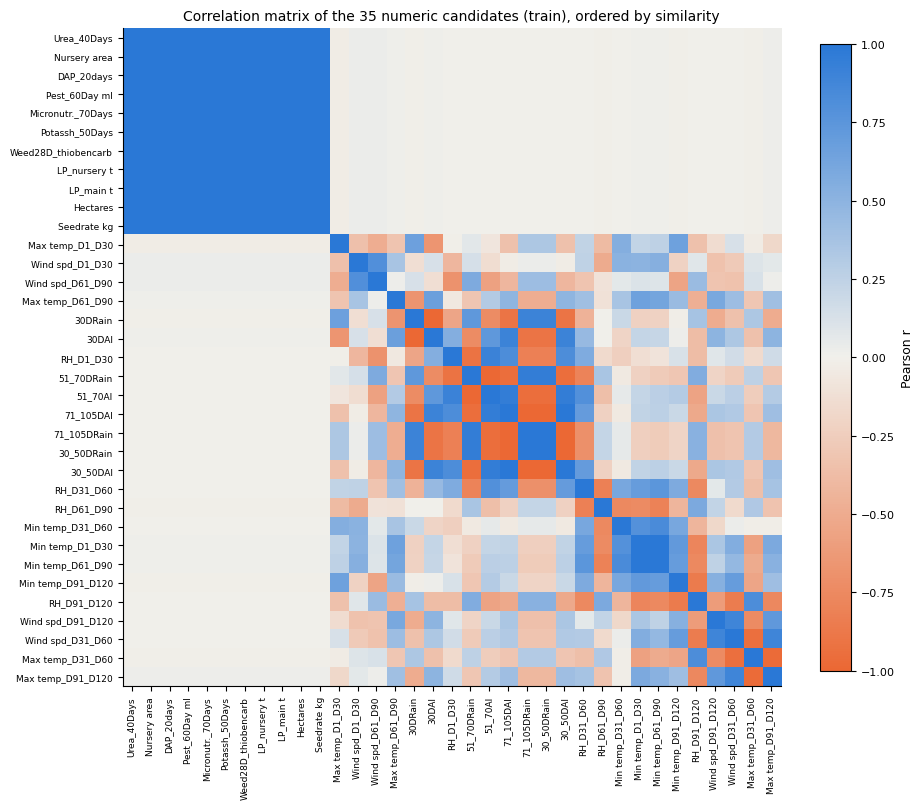

groups of features that are pairwise connected by |r| >= 0.95:
  group of 11, min |r| inside = 1.0000: ['Hectares', 'Seedrate kg', 'LP_main t', 'Nursery area', 'LP_nursery t', 'DAP_20days', 'Weed28D_thiobencarb', 'Urea_40Days', 'Potassh_50Days', 'Micronutr._70Days', 'Pest_60Day ml']
  group of  2, min |r| inside = 1.0000: ['30DRain', '30DAI']
  group of  6, min |r| inside = 0.9518: ['30_50DRain', '51_70DRain', '71_105DRain', '30_50DAI', '51_70AI', '71_105DAI']
  group of  2, min |r| inside = 0.9927: ['Min temp_D1_D30', 'Min temp_D61_D90']
  group of  2, min |r| inside = 0.9720: ['Max temp_D31_D60', 'Max temp_D91_D120']
features not in any group: ['Min temp_D31_D60', 'Min temp_D91_D120', 'Max temp_D1_D30', 'Max temp_D61_D90', 'Wind spd_D1_D30', 'Wind spd_D31_D60', 'Wind spd_D61_D90', 'Wind spd_D91_D120', 'RH_D1_D30', 'RH_D31_D60', 'RH_D61_D90', 'RH_D91_D120']


In [32]:
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform
from matplotlib.colors import LinearSegmentedColormap
cand = [c for c in NUM if c != TRASH]                       # 35 numeric candidates (Trash already rejected as leakage)
Rm = tr[cand].corr()
Dm = np.clip(1 - Rm.abs().values, 0, None); np.fill_diagonal(Dm, 0); Dm = (Dm + Dm.T) / 2      # clip: |r| can exceed 1 by ~1e-16
order = leaves_list(linkage(squareform(Dm, checks=False), 'average')); names = [cand[i] for i in order]
cmap = LinearSegmentedColormap.from_list('div', [ORANGE, '#f1f0eb', BLUE])
fig, ax = plt.subplots(figsize=(9.5, 8.2)); im = ax.imshow(Rm.loc[names, names].values, cmap=cmap, vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(len(names))); ax.set_xticklabels([short(c) for c in names], rotation=90, fontsize=6.5); ax.set_yticks(range(len(names))); ax.set_yticklabels([short(c) for c in names], fontsize=6.5)
plt.colorbar(im, fraction=0.04, label='Pearson r'); ax.set_title('Correlation matrix of the 35 numeric candidates (train), ordered by similarity'); plt.tight_layout(); plt.show()
lab = connected_components((Rm.abs().values >= 0.95).astype(int))[1]
cl = pd.DataFrame({'feature': cand, 'cluster': lab}).groupby('cluster').feature.apply(list)
cl = cl[cl.apply(len) > 1]
print('groups of features that are pairwise connected by |r| >= 0.95:')
for k, m in cl.items():
    sub = Rm.loc[m, m].abs().values; print(f'  group of {len(m):2d}, min |r| inside = {sub.min():.4f}: {[short(x) for x in m]}')
print('features not in any group:', [short(c) for c in cand if c not in sum(cl.tolist(), [])])

In [33]:
# ---- ความสัมพันธ์ที่แน่นอนเบื้องหลัง correlation clusters ----
ratio = pd.DataFrame({c: (tr[c] / tr['Hectares']).round(6) for c in INPUTS})      # round(6): removes floating-point noise only
print('1) INPUT columns divided by Hectares -> number of distinct values (1 = an exact constant per hectare):')
display(pd.DataFrame({'distinct per-ha values': ratio.nunique(), 'value per ha': ratio.iloc[0]}).T)
print('2) Rain + AI in every window -> distinct sums:', {short(r): sorted((tr[r] + tr[a]).round(6).unique()) for r, a in zip(RAIN, AI)},
      '| corr(rain, AI):', [round(tr[r].corr(tr[a]), 6) for r, a in zip(RAIN, AI)])
W_num = RAIN + AI + TMIN + TMAX + WIND + RH; W_cat = [c for c in CAT if c.startswith('Wind Direction')]
mx = tr.groupby('Agriblock')[W_num + W_cat].nunique().max().max()
print(f'3) Weather: {len(W_num)} numeric + {len(W_cat)} categorical weather columns. Largest number of distinct values of ANY weather column inside one agri-block: {mx}')
prof = tr.groupby(W_num + W_cat).ngroup(); print('   distinct weather profiles:', prof.nunique(), '| distinct agri-blocks:', tr.Agriblock.nunique(), '| crosstab is one-to-one:',
      bool((pd.crosstab(tr.Agriblock, prof) > 0).sum(axis=1).eq(1).all() and (pd.crosstab(tr.Agriblock, prof) > 0).sum(axis=0).eq(1).all()))
print('   Cramer V (Agriblock vs wind-direction window):', {short(c): round(cramers_v(tr.Agriblock, tr[c]), 3) for c in W_cat})
print('   Does yield differ between weather profiles beyond agri-block? -> identical grouping, so weather and block cannot be separated in this data.')

1) INPUT columns divided by Hectares -> number of distinct values (1 = an exact constant per hectare):


,Seedrate(in Kg),LP_Mainfield(in Tonnes),Nursery area (Cents),LP_nurseryarea(in Tonnes),DAP_20days,Weed28D_thiobencarb,Urea_40Days,Potassh_50Days,Micronutrients_70Days,Pest_60Day(in ml)
distinct per-ha values,1,1,1,1,1,1,1,1,1,1
value per ha,25,12.5,20,1,40,2,27.13,10.38,15,600


2) Rain + AI in every window -> distinct sums: {'30DRain': [40.0], '30_50DRain': [458.0], '51_70DRain': [417.0], '71_105DRain': [125.0]} | corr(rain, AI): [-1.0, -1.0, -1.0, -1.0]
3) Weather: 24 numeric + 4 categorical weather columns. Largest number of distinct values of ANY weather column inside one agri-block: 1
   distinct weather profiles: 6 | distinct agri-blocks: 6 | crosstab is one-to-one: True
   Cramer V (Agriblock vs wind-direction window): {'Wind dir_D1_D30': 1.0, 'Wind dir_D31_D60': 1.0, 'Wind dir_D61_D90': 1.0, 'Wind dir_D91_D120': 1.0}
   Does yield differ between weather profiles beyond agri-block? -> identical grouping, so weather and block cannot be separated in this data.


In [34]:
# ---- VIF, rank และ condition number: ก่อน / หลังกำจัดความซ้ำซ้อน ----
def design_report(X, name):
    Z = (X - X.mean()) / X.std(ddof=0).replace(0, 1); v = vif_table(X)
    return dict(set=name, columns=X.shape[1], rank=int(np.linalg.matrix_rank(Z.values)), cond_number=np.linalg.cond(Z.values),
                VIF_inf=int(np.isinf(v).sum()), VIF_gt_10=int((v > 10).sum()), max_finite_VIF=v[np.isfinite(v)].max() if np.isfinite(v).any() else np.nan)
SET_A = tr[cand]                                                            # all 35 numeric candidates
SET_B = tr[['Hectares'] + RAIN + TMIN + TMAX + WIND + RH]                   # drop 10 proportional inputs and the 4 AI columns
SET_C = pd.concat([tr[['Hectares']], pd.get_dummies(tr.Agriblock, drop_first=True).astype(float)], axis=1)   # size + block dummies (5)
rep = pd.DataFrame([design_report(SET_A, 'A: 35 numeric candidates'), design_report(SET_B, 'B: A minus 10 inputs minus 4 AI (21 columns)'),
                    design_report(SET_C, 'C: Hectares + 5 block dummies (6 columns)')]).set_index('set')
display(rep)
vb = vif_table(SET_B).replace(np.inf, 1e12).sort_values(ascending=False); vc = vif_table(SET_C)
print('VIF, set B (top 6, 1e12 = infinite):', {short(k): float(f'{v:.3g}') for k, v in vb.head(6).items()})
print('VIF, set C:', {short(k): round(v, 3) for k, v in vc.items()})

,columns,rank,cond_number,VIF_inf,VIF_gt_10,max_finite_VIF
set,,,,,,
A: 35 numeric candidates,35,6,"237,518,900,871,923,433,472",35,35,NaN
B: A minus 10 inputs minus 4 AI (21 columns),21,6,"66,328,345,892,235,200",20,20,1.0015
C: Hectares + 5 block dummies (6 columns),6,6,2.5391,0,0,1.8274


VIF, set B (top 6, 1e12 = infinite): {'30DRain': 1000000000000.0, '51_70DRain': 1000000000000.0, '30_50DRain': 1000000000000.0, '71_105DRain': 1000000000000.0, 'Min temp_D1_D30': 1000000000000.0, 'Wind spd_D1_D30': 1000000000000.0}
VIF, set C: {'Hectares': 1.001, 'Cuddalore': 1.681, 'Kallakurichi': 1.637, 'Kurinjipadi': 1.704, 'Panruti': 1.619, 'Sankarapuram': 1.827}


### 10.1 อภิปราย — feature ที่ซ้ำซ้อน
Correlation heat-map มีบล็อกสีน้ำเงินเด่นชัด 1 บล็อกและบล็อกแดง/น้ำเงินผสมอีก 1 บล็อก — สอง cluster ตรงกับ 2 กลุ่มที่พบใน §8

**Cluster 1 — ขนาดแปลง** `Hectares` และคอลัมน์ input อีก 10 ตัวเชื่อมกันด้วย **|r| ต่ำสุด = 1.0000** การตรวจโดยตรงยืนยัน *สาเหตุ*: การเอาแต่ละ input หารด้วย `Hectares` เหลือ **ค่าเดียวเป๊ะ** (เช่น `Seedrate/Hectares` = 25 kg/ha ทุกแถวใน 1,636 แถว; `Weed28D_thiobencarb/Hectares` = 2 ทุกแถว) — นี่คือ **ปริมาณแนะนำต่อเฮกตาร์** ไม่ใช่การวัดอิสระ 11 ครั้ง (นี่คือหลักฐานของ assumption A5, §1.3) มันคือการเข้ารหัสตัวเลข **ตัวเดียว** ด้วย 11 วิธี

**Cluster 2 — สภาพอากาศ** `30DRain` และ `30DAI` เชื่อมกันที่ r = −1.0000 **เป๊ะ**: ผลรวมของทั้งคู่เท่ากับค่าคงที่เดียวกัน (40.0) ในทุกแถว กล่าวคือ `AI = 40 − Rain` ซึ่งเป็น affine transform ล้วน ๆ — เรื่องนี้คลี่คลาย assumption A4 (§1.3) ในที่สุด: *ไม่ว่า* AI จะหมายถึงอะไร มัน **ไม่ให้ข้อมูลใดเกินไปกว่าฝน** ในไฟล์นี้ Cluster 6 คอลัมน์ที่กว้างกว่า (|r| ต่ำสุด = 0.95) และคู่อุณหภูมิเล็ก ๆ อธิบายได้ด้วยข้อเท็จจริงเดียวซึ่งตรวจโดยตรงแล้ว: **ทุกคอลัมน์สภาพอากาศ (numeric 24 ตัว + ทิศทางลม 4 ตัว) มีค่าเดียวเป๊ะภายในแต่ละ agri-block** มีโปรไฟล์สภาพอากาศที่แตกต่างกันเพียง 6 แบบสำหรับ 6 agri-blocks และการจับคู่ block ↔ profile เป็นแบบหนึ่งต่อหนึ่ง (Cramér's V = 1.0 สำหรับทุกคอลัมน์ทิศทางลมเทียบกับ `Agriblock`) **สภาพอากาศคือการเปลี่ยนชื่อของ identifier ของ block** ไม่ใช่การวัดที่เป็นอิสระ — ดังนั้นจึงไม่แปลกที่คอลัมน์สภาพอากาศต่าง ๆ จะ correlate กันเอง: ทุกตัวเป็นฟังก์ชันเชิงกำหนดของตัวแปร categorical 6 levels ตัวเดียวกัน และเมื่อมีคอลัมน์ numeric (24) มากกว่าจำนวนโปรไฟล์ที่แตกต่างกัน (6) การเกิด linear dependency จึงหลีกเลี่ยงไม่ได้ (pigeonhole)

**VIF / rank ยืนยันพีชคณิต** ชุด numeric ครบ 35 คอลัมน์มี **rank เท่ากับ 6** (ไม่ใช่ 35!) และทุก VIF เป็นอนันต์ — design matrix เป็น singular พอดี ดังนั้น fit ด้วย normal equation $(X^\top X)^{-1}X^\top y$ จะไม่มีทางมีอยู่จริง (สูตร Ch01, §1) การเอาคอลัมน์ input ที่ซ้ำ 10 ตัวและคอลัมน์ AI 4 ตัวออก (เหลือ 21 คอลัมน์) ก็ยังได้ rank 6 และ 20 จาก 21 VIFs เป็นอนันต์ ด้วยเหตุผลข้างต้น ต่อเมื่อแทนที่บล็อกสภาพอากาศ/ตำแหน่งด้วย **`Hectares` + agri-block dummies 5 ตัว** (6 คอลัมน์ ตรงกับ 6 องศาอิสระที่แท้จริง) VIFs จึงเล็กลง (สูงสุด 1.83) และ condition number ลดเหลือ 2.5 — เป็น design ที่ตั้งไว้ดี

**การตัดสินใจ** เก็บตัวแทน **หนึ่งตัว** ของ Cluster 1 คือ `Hectares` เพราะเป็นตัวขับเคลื่อนหลักเชิงกายภาพ (พื้นที่) และมีให้ใช้ตั้งแต่ก่อนปลูก ต่างจากปริมาณ input ที่เป็นค่าที่แปลงมา ตัดคอลัมน์ input อีก 10 ตัวทิ้งเพราะเป็นสำเนาที่แน่นอน ตัดคอลัมน์สภาพอากาศ **ทั้ง** 24 ตัวและทิศทางลม 4 ตัวทิ้ง: ถึงจะยุบเหลือ 6 องศาอิสระที่แท้จริง (≈ `Agriblock`) §8–§9 ก็แสดงแล้วว่าไม่มีความสัมพันธ์กับ target ใด ๆ การเก็บไว้จึงเป็นเพียงการนำ singularity ที่เพิ่งวินิจฉัยกลับเข้ามาโดยไม่ได้ประโยชน์ เมื่อรวมกับ §8–§9 จึงเหลือ: **`Hectares` (continuous) และ `Variety` (categorical, effect เล็ก)** เป็นชุด predictor candidate ที่ส่งต่อไป §12

# 11 · Feature extraction  *(rubric 13 · Ch02 Dimensionality reduction: feature extraction, PCA)*
Feature extraction คือ **การสร้าง feature ใหม่จากของเดิม** (Ch02); มันช่วย (i) ใส่ความรู้เชิง domain เข้าไป, (ii) ลดมิติ (curse of dimensionality: พารามิเตอร์มากขึ้น → over-fitting มากขึ้น และ OLS ต้องการตัวอย่างมากขึ้นอีกมาก)

### 11.1 Features ที่สร้างจากความรู้เชิง domain (Ch02: "insight จากความรู้เชิง domain ช่วยเพิ่มความแม่นยำได้")
ข้าวไวต่อความเครียดจากน้ำและอุณหภูมิในระดับฤดูกาล จึงรวมช่วง 30 วันทั้ง 4 ช่วงเป็น: ฝนรวม, อุณหภูมิเฉลี่ย, พิสัยอุณหภูมิรายวัน (DTR = max − min), ความชื้นเฉลี่ย และความเร็วลมเฉลี่ย *Assumption:* แต่ละช่วงส่งผลต่อความเครียดของฤดูกาลแบบบวกกันและมีน้ำหนักเท่ากัน

In [35]:
def add_engineered(d):
    e = pd.DataFrame(index=d.index)
    e['rain_total'] = d[RAIN].sum(axis=1)
    e['temp_mean'] = (d[TMIN].values + d[TMAX].values).mean(axis=1) / 2
    e['temp_DTR'] = (d[TMAX].values - d[TMIN].values).mean(axis=1)
    e['RH_mean'] = d[RH].mean(axis=1); e['wind_mean'] = d[WIND].mean(axis=1)
    return e
E = add_engineered(tr); rng = np.random.default_rng(SEED)
rows = []
for c in E:
    fl = np.percentile([mutual_info_regression(E[[c]].values, rng.permutation(tr[Y2].values), discrete_features=True, random_state=SEED)[0] for _ in range(30)], 95)
    rows.append((c, E[c].nunique(), E[c].corr(tr[Y]), stats.pearsonr(E[c], tr[Y2])[0], stats.pearsonr(E[c], tr[Y2])[1],
                 mutual_info_regression(E[[c]].values, tr[Y2].values, discrete_features=True, random_state=SEED)[0], fl))
display(pd.DataFrame(rows, columns=['engineered feature', 'n_unique', 'r_Y', 'r_Yha', 'p_Yha', 'MI_Yha', 'MI_floor']).set_index('engineered feature'))

,n_unique,r_Y,r_Yha,p_Yha,MI_Yha,MI_floor
engineered feature,,,,,,
rain_total,3,-0.0086,-0.012,0.6283,0,0.0168
temp_mean,6,-0.0035,-0.0044,0.8577,0,0.026
temp_DTR,5,-0.0104,0.0134,0.5882,0,0.0225
RH_mean,6,-0.007,-0.0021,0.9309,0,0.0208
wind_mean,4,0.026,0.0098,0.6932,0,0.0183


### 11.2 Principal component analysis (PCA)
PCA หาทิศทางที่ตั้งฉากกันซึ่งมี variance สูงสุด: eigenvectors ของ covariance matrix $\Sigma\mathbf w=\lambda\mathbf w$; PC$_k$ = $w_1x_1+\dots+w_dx_d$ (เรียกว่า *loadings*)
**Assumptions และข้อจำกัด (Ch02):** (1) โครงสร้างต้องเป็น **เชิงเส้น**; (2) *variance = information* — PCA เป็นแบบ **unsupervised** ดังนั้น PC ที่มี variance สูงไม่จำเป็นต้องทำนาย target ได้; (3) PCA **ไวต่อสเกล** จึงต้อง **standardise features ก่อน** (mean 0, SD 1) — sklearn ทำ centre ให้แต่ไม่ scale ให้; (4) fit บน **train เท่านั้น**; (5) PCs ตีความยาก
เราใช้กับ 3 บล็อก: บล็อกสภาพอากาศ (20 คอลัมน์; ตัด AI ออกเพราะมันคือ −rain พอดี), คอลัมน์ size/input 11 ตัว และ numeric candidates ทั้ง 35 ตัว

,PC1 %,PCs for 90 %,PCs for 95 %,PCs for 99 %,PCs with variance > 1e-9
block,,,,,
weather (20 cols),42.5823,4,5,5,5
size + 10 inputs (11 cols),100,1,1,1,1
all numeric candidates (35 cols),31.9033,5,5,6,6


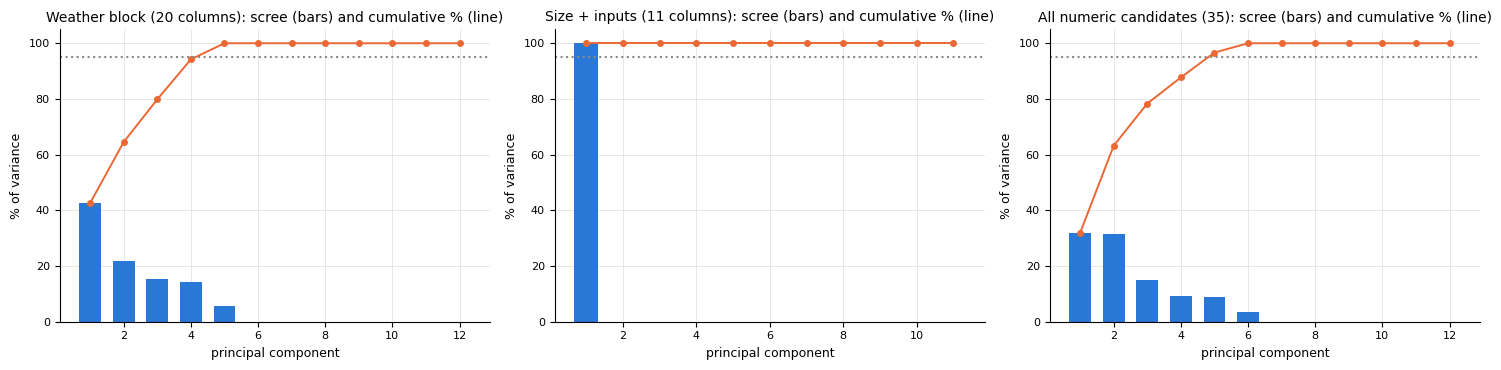

In [36]:
def pca_block(cols, name):
    sc = StandardScaler().fit(tr[cols]); p = PCA(random_state=SEED).fit(sc.transform(tr[cols]))
    return sc, p
WCOLS = RAIN + TMIN + TMAX + WIND + RH; ICOLS = ['Hectares'] + INPUTS
sw, pw = pca_block(WCOLS, 'weather'); si, pi = pca_block(ICOLS, 'size/inputs'); sa, pa = pca_block(cand, 'all 35')
def k_for(p, q): return int(np.searchsorted(np.cumsum(p.explained_variance_ratio_), q - 1e-9) + 1)
tab = pd.DataFrame({'block': ['weather (20 cols)', 'size + 10 inputs (11 cols)', 'all numeric candidates (35 cols)'],
                    'PC1 %': [p.explained_variance_ratio_[0] * 100 for p in (pw, pi, pa)],
                    'PCs for 90 %': [k_for(p, .90) for p in (pw, pi, pa)], 'PCs for 95 %': [k_for(p, .95) for p in (pw, pi, pa)], 'PCs for 99 %': [k_for(p, .99) for p in (pw, pi, pa)],
                    'PCs with variance > 1e-9': [int((p.explained_variance_ > 1e-9).sum()) for p in (pw, pi, pa)]}).set_index('block')
display(tab)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, p, t in [(ax[0], pw, 'Weather block (20 columns)'), (ax[1], pi, 'Size + inputs (11 columns)'), (ax[2], pa, 'All numeric candidates (35)')]:
    k = min(12, len(p.explained_variance_ratio_)); ev = p.explained_variance_ratio_[:k] * 100
    a.bar(range(1, k + 1), ev, color=BLUE, width=.65)
    a.plot(range(1, k + 1), np.cumsum(p.explained_variance_ratio_)[:k] * 100, '-o', color=ORANGE, ms=4, lw=1.4); a.axhline(95, color=GREY, ls=':')
    a.set(title=t + ': scree (bars) and cumulative % (line)', xlabel='principal component', ylabel='% of variance', ylim=(0, 105))
plt.tight_layout(); plt.show()

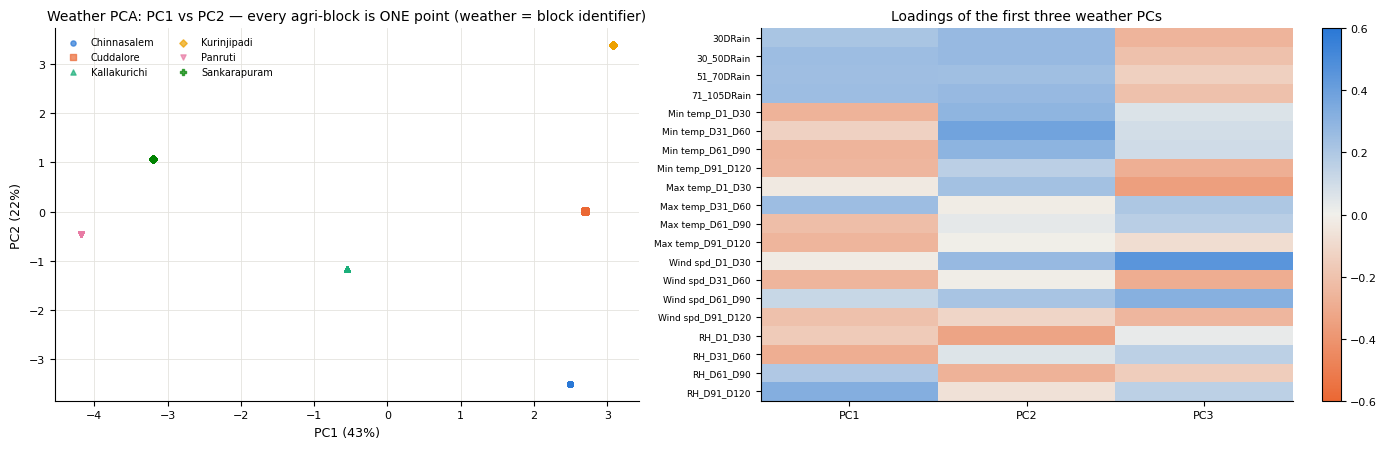

,var. explained,r_Y,p_Y,r_Yha,p_Yha
component,,,,,
weather PC1,0.4258,-0.0066,0.7911,0.0098,0.6907
weather PC2,0.2197,0.0041,0.8675,-0.0037,0.8816
weather PC3,0.153,0.0265,0.2839,0.0511,0.0387
weather PC4,0.1436,-0.0243,0.326,-0.019,0.4421
weather PC5,0.0579,-0.0138,0.5776,0.0169,0.4933
size/inputs PC1,1,0.9946,0,0.601,3.18e-161


|corr(size/inputs PC1, Hectares)| = 1.0


In [37]:
Zw = pw.transform(sw.transform(tr[WCOLS])); markers = ['o', 's', '^', 'D', 'v', 'P']; blocks = sorted(tr.Agriblock.unique())
pal = [BLUE, ORANGE, AQUA, YELLOW, MAGENTA, '#008300']
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
for b, m, col in zip(blocks, markers, pal):
    s = (tr.Agriblock == b).values; ax[0].scatter(Zw[s, 0], Zw[s, 1], s=14, marker=m, color=col, alpha=.7, label=b)
ax[0].set(title='Weather PCA: PC1 vs PC2 — every agri-block is ONE point (weather = block identifier)', xlabel=f'PC1 ({pw.explained_variance_ratio_[0]:.0%})', ylabel=f'PC2 ({pw.explained_variance_ratio_[1]:.0%})'); ax[0].legend(ncol=2, fontsize=7)
L = pd.DataFrame(pw.components_[:3].T, index=[short(c) for c in WCOLS], columns=['PC1', 'PC2', 'PC3'])
im = ax[1].imshow(L.values, cmap=cmap, vmin=-.6, vmax=.6, aspect='auto'); ax[1].set_yticks(range(len(L))); ax[1].set_yticklabels(L.index, fontsize=6.5); ax[1].set_xticks(range(3)); ax[1].set_xticklabels(L.columns); ax[1].grid(False)
ax[1].set_title('Loadings of the first three weather PCs'); plt.colorbar(im, ax=ax[1], fraction=.04); plt.tight_layout(); plt.show()
# PCs สัมพันธ์กับ target หรือไม่? (PCA ไม่เคยดู y เลย)
kw = k_for(pw, .95); rows = []
for j in range(kw):
    rows.append((f'weather PC{j+1}', pw.explained_variance_ratio_[j], stats.pearsonr(Zw[:, j], tr[Y])[0], stats.pearsonr(Zw[:, j], tr[Y])[1], stats.pearsonr(Zw[:, j], tr[Y2])[0], stats.pearsonr(Zw[:, j], tr[Y2])[1]))
Zi = pi.transform(si.transform(tr[ICOLS])); rows.append(('size/inputs PC1', pi.explained_variance_ratio_[0], stats.pearsonr(Zi[:, 0], tr[Y])[0], stats.pearsonr(Zi[:, 0], tr[Y])[1], stats.pearsonr(Zi[:, 0], tr[Y2])[0], stats.pearsonr(Zi[:, 0], tr[Y2])[1]))
display(pd.DataFrame(rows, columns=['component', 'var. explained', 'r_Y', 'p_Y', 'r_Yha', 'p_Yha']).set_index('component'))
print('|corr(size/inputs PC1, Hectares)| =', abs(np.corrcoef(Zi[:, 0], tr.Hectares)[0, 1]).round(6))

### 11.3 อภิปราย — feature extraction
**ตัวรวมที่สร้างจาก domain** (`rain_total`, `temp_mean`, `temp_DTR`, `RH_mean`, `wind_mean`) ทุกตัวมี |r| < 0.03 และ MI อยู่ที่ noise floor เมื่อเทียบกับทุก target นี่เป็นสิ่งที่คาดได้ ไม่ใช่ความล้มเหลวของแนวคิด: การรวมคอลัมน์ที่แต่ละตัวไม่มีสัญญาณต่อ target (§8) ไม่สามารถเสกสัญญาณขึ้นมาได้ด้วยการบวกหรือเฉลี่ย มันทำได้แค่เฉลี่ย noise ออก จึง **ไม่** เพิ่มเข้าโมเดล

**PCA ยืนยันการวิเคราะห์ความซ้ำซ้อนจากมุมที่สองซึ่งเป็น unsupervised ล้วน ๆ** บล็อก size/input ยุบเหลือ **component เดียวที่อธิบาย variance ได้ 100.00 %** และ correlate **r = 1.0** กับ `Hectares` — PCA ค้นพบเองว่าคอลัมน์ทั้ง 11 ตัวคือตัวแปรเดียว โดยไม่เคยเห็น target เลย บล็อกสภาพอากาศต้องใช้ **4–5 components เพื่อให้ได้ 90–95 %** ของ variance (ตรงกับ ≈6 องศาอิสระที่แท้จริงที่พบใน §10) แต่ **ไม่มี weather PC ใดใน 5 ตัวแรกที่ correlate กับ target** (|r| สูงสุด = 0.05, p = 0.28) — ยืนยันอีกครั้งโดยไม่ใช้ target ระหว่างการ extract ว่าบล็อกนี้ทั้งบล็อกไม่มีสัญญาณที่ใช้ได้ ไม่ว่าจะหมุนอย่างไร Scatter ของ PC1 vs PC2 ทำให้เห็นเหตุผลชัดเจน: **จุดแยกเป็นกลุ่มพอดี 6 กลุ่ม กลุ่มละ agri-block** — นี่คืออัตลักษณ์ของตำแหน่งที่ถูกอนุมานใหม่โดยอัลกอริทึมที่ maximise variance เพียงอย่างเดียว ตรงกับคำเตือนของ Ch02 ว่า PCA หา *variance* ไม่ใช่ *relevance*: ในที่นี้ทิศทางที่ variance สูงสุดคือส่วนของข้อมูลที่พิสูจน์แล้วว่าไม่เกี่ยวข้องพอดี

**บทสรุปของ §11** ไม่มี PCA component และไม่มีตัวรวมที่สร้างขึ้นตัวใดถูกเพิ่มเข้าชุด predictor สุดท้าย แต่ PCA ก็ยังเป็น **เครื่องมือ diagnostic** ที่มีประโยชน์ในที่นี้: มันยืนยันข้อค้นพบเรื่องความซ้ำซ้อนทั้งสองข้อของ §10 โดยอิสระ (collinearity ที่แน่นอนในบล็อก input; อัตลักษณ์ block/สภาพอากาศ) โดยไม่ใช้ supervision เลย ซึ่งเป็นการตรวจสอบไขว้แบบ "insight จากความรู้ของมนุษย์" ที่ Ch02 แนะนำให้ทำก่อนจะเชื่อการคัดเลือกแบบ filter

# 12 · Data pre-processing สำหรับ Machine Learning  *(rubric 14 · Ch01 encoding/scaling · Ch02 model assumptions)*
**ชุด predictor สุดท้าย** (จาก leakage audit §1.4 + การคัดเลือก/ความซ้ำซ้อน §8–§11): **`Hectares`** (continuous) และ **`Variety`** (categorical, 3 levels) นี่คือชุดที่เล็กที่สุดที่รอดทุกการทดสอบที่เป็นอิสระต่อกัน — correlation, ANOVA, MI, VIF และ PCA เห็นตรงกันทั้งหมด (§8–§11) และจะพาชุดที่ **ใหญ่กว่า** อีกชุดหนึ่งซึ่งจงใจใส่คอลัมน์เพิ่มไปเปรียบเทียบด้วยใน §14 (Ch01: *"เปรียบเทียบประสิทธิภาพของโมเดลระหว่าง predictors ที่สัมพันธ์กับ target อย่างแรง แล้วเพิ่มหรือถอด predictors ที่น่าสงสัย"*): **Hectares + Variety + Agriblock + Soil Types + Nursery** — คือทุกคอลัมน์ที่ *ไม่ซ้ำซ้อนและไม่ leak* เพื่อให้ข้อมูลเองยืนยันว่าคอลัมน์ส่วนเกินไม่ได้ช่วยอะไร

**ขั้นตอนและเหตุผล (Ch01/Ch02):**
1. **One-hot encode** `Variety`, `Agriblock`, `Soil Types`, `Nursery` (nominal ไม่มีลำดับ → integer codes จะสร้างระยะห่างปลอมขึ้นมา, §2.1)
2. **Impute** (median / most-frequent) — ไม่มีผลอะไรในที่นี้ (§7) แต่คงไว้เพื่อให้ pipeline ปลอดภัยกับข้อมูลใหม่
3. **Standardise** คอลัมน์ numeric (Ch02 "Feature Scaling": จำเป็นเพราะ `Hectares` (1–6) และในชุดที่ใหญ่กว่าคือคอลัมน์ numeric ใด ๆ จะครอบงำด้วยขนาดดิบ; จำเป็นสำหรับให้ gradient descent ลู่เข้าอย่างสม่ำเสมอ และเพื่อเปรียบเทียบสัมประสิทธิ์)
4. **Fit ทุกขั้นบน TRAIN เท่านั้น** แล้ว `.transform()` บน test — เป็น leakage guard จาก §1.4/§3

In [38]:
NARROW_NUM, NARROW_CAT = ['Hectares'], ['Variety']
WIDE_NUM, WIDE_CAT = ['Hectares'], ['Variety', 'Agriblock', 'Soil Types', 'Nursery']
def make_pre(num, cat):
    return ColumnTransformer([
        ('num', Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), num),
        ('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first'))]), cat)])
pre_narrow, pre_wide = make_pre(NARROW_NUM, NARROW_CAT), make_pre(WIDE_NUM, WIDE_CAT)
Xtr_n = pre_narrow.fit_transform(train); Xte_n = pre_narrow.transform(test)
Xtr_w = pre_wide.fit_transform(train); Xte_w = pre_wide.transform(test)
names_n = pre_narrow.get_feature_names_out(); names_w = pre_wide.get_feature_names_out()
ytr, yte = train[Y].values, test[Y].values
print('narrow design:', Xtr_n.shape, list(names_n))
print('wide   design:', Xtr_w.shape, list(names_w))
print('scaler learned on TRAIN -> Hectares mean %.3f, sd %.3f (test is only transformed with these numbers)' % (pre_narrow.named_transformers_['num']['scale'].mean_[0], pre_narrow.named_transformers_['num']['scale'].scale_[0]))

narrow design: (1636, 3) ['num__Hectares', 'cat__Variety_delux ponni', 'cat__Variety_ponmani']
wide   design: (1636, 10) ['num__Hectares', 'cat__Variety_delux ponni', 'cat__Variety_ponmani', 'cat__Agriblock_Cuddalore', 'cat__Agriblock_Kallakurichi', 'cat__Agriblock_Kurinjipadi', 'cat__Agriblock_Panruti', 'cat__Agriblock_Sankarapuram', 'cat__Soil Types_clay', 'cat__Nursery_wet']
scaler learned on TRAIN -> Hectares mean 3.730, sd 1.449 (test is only transformed with these numbers)


# 13 · การแปลงข้อมูลของ target
§4 พบว่า raw target เบ้เล็กน้อย แต่ที่สำคัญกว่าคือ **heteroscedastic ข้ามขนาดแปลง** (อัตราส่วน SD ภายในขนาด 9.6 เทียบกับ 1.5 หลัง log) สไลด์ model assumptions ของ Ch02 ระบุว่า "X และ Y มีการแจกแจงปกติ (ไม่บังคับ)" และ Ch01 ต้องการ **residuals ที่ homoscedastic** เราจึงพาทั้ง raw target และ log ของมันไปต่อ แล้วตัดสินเชิงประจักษ์ด้วยว่าตัวไหนให้ residuals ที่มีพฤติกรรมดีกว่า (§14.5)

In [39]:
ytr_log, yte_log = np.log(ytr), np.log(yte)
print('log-target train mean %.4f sd %.4f | test mean %.4f sd %.4f (close -> consistent transform)' % (ytr_log.mean(), ytr_log.std(), yte_log.mean(), yte_log.std()))

log-target train mean 9.9083 sd 0.5307 | test mean 9.9133 sd 0.5305 (close -> consistent transform)


# 14 · การสร้างและ train โมเดล  *(rubrics 15, 16 · Ch01 Linear Least Squares, Gradient Descent, Cross-Validation)*
### 14.1 ผลเฉลยรูปปิด (closed-form) และ gradient descent ที่เขียนเอง
เปรียบเทียบการ implement **objective เดียวกัน** $L(\mathbf a)=\lVert X\mathbf a-\mathbf y\rVert_2^2$ 2 แบบที่เป็นอิสระต่อกัน: **normal equation** $\mathbf a=(X^\top X)^{-1}X^\top\mathbf y$ (Ch01) และ **batch gradient descent** $\mathbf a\leftarrow\mathbf a-\eta\,\nabla L(\mathbf a)$, $\nabla L=2X^\top(X\mathbf a-\mathbf y)$ ทั้งสองควรลู่เข้าสู่สัมประสิทธิ์เดียวกัน — นี่คือการตรวจโดยตรงว่าทั้งสูตรและโค้ดถูกต้อง ไม่ใช่แค่การสาธิต

normal equation  a = [22587.15  9206.51   121.06  -143.03]
gradient descent a = [22587.15  9206.51   121.06  -143.03]
max |difference|   = 1.06967947033354e-06  (both converge to the same minimum: L is convex, Ch01)


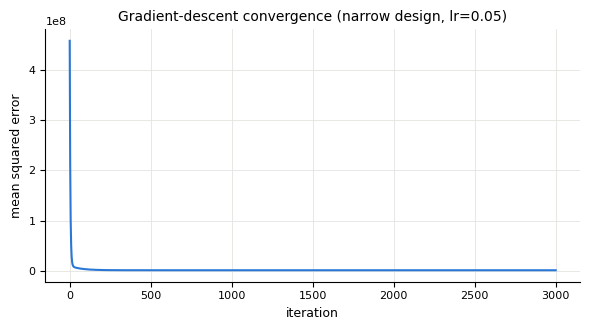

In [40]:
def normal_equation(X, y):
    A = np.column_stack([np.ones(len(X)), X]); return np.linalg.solve(A.T @ A, A.T @ y)
def gradient_descent(X, y, lr=0.05, n_iter=3000):
    A = np.column_stack([np.ones(len(X)), X]); a = np.zeros(A.shape[1]); n = len(y); hist = []
    for _ in range(n_iter):
        grad = (2 / n) * A.T @ (A @ a - y); a -= lr * grad; hist.append(np.mean((A @ a - y)**2))
    return a, hist
Xn_tr = Xtr_n.toarray() if hasattr(Xtr_n, 'toarray') else Xtr_n
a_closed = normal_equation(Xn_tr, ytr)
a_gd, hist = gradient_descent(Xn_tr, ytr, lr=0.05, n_iter=3000)
print('normal equation  a =', np.round(a_closed, 2))
print('gradient descent a =', np.round(a_gd, 2))
print('max |difference|   =', np.max(np.abs(a_closed - a_gd)), ' (both converge to the same minimum: L is convex, Ch01)')
fig, ax = plt.subplots(figsize=(6, 3.4)); ax.plot(hist, color=BLUE); ax.set(title='Gradient-descent convergence (narrow design, lr=0.05)', xlabel='iteration', ylabel='mean squared error'); plt.tight_layout(); plt.show()

### 14.2 โมเดลที่ fit
| Model | Design | Target |
|---|---|---|
| `M1_narrow` | Hectares + Variety | raw kg |
| `M2_wide` | + Agriblock + Soil + Nursery | raw kg |
| `M3_narrow_log` | Hectares + Variety | log(kg) |
| `M4_hectares_only` | Hectares อย่างเดียว | raw kg |

In [41]:
def fit_eval(Xtr, ytr, Xte, yte, log=False, n_params=None):
    m = LinearRegression().fit(Xtr, ytr)
    pr_tr, pr_te = m.predict(Xtr), m.predict(Xte)
    if log: pr_tr, pr_te = np.exp(pr_tr), np.exp(pr_te)
    mt = regression_metrics(train[Y] if log else ytr, pr_tr, p=n_params or Xtr.shape[1])
    me = regression_metrics(test[Y] if log else yte, pr_te, p=n_params or Xtr.shape[1])
    return m, mt, me, pr_tr, pr_te
Hn = Xtr_n[:, :1] if not hasattr(Xtr_n, 'toarray') else Xtr_n[:, :1].toarray()
Hn_te = Xte_n[:, :1] if not hasattr(Xte_n, 'toarray') else Xte_n[:, :1].toarray()
models = {'M1_narrow (Hectares+Variety)': fit_eval(Xtr_n, ytr, Xte_n, yte),
          'M2_wide (+Agriblock+Soil+Nursery)': fit_eval(Xtr_w, ytr, Xte_w, yte),
          'M3_narrow_log (log target)': fit_eval(Xtr_n, ytr_log, Xte_n, yte_log, log=True),
          'M4_hectares_only': fit_eval(Hn, ytr, Hn_te, yte, n_params=1)}
rows = []
for name, (m, mt, me, *_ ) in models.items():
    rows.append(dict(model=name, **{f'train_{k}': v for k, v in mt.items()}, **{f'test_{k}': v for k, v in me.items()}))
res_tab = pd.DataFrame(rows).set_index('model')
display(res_tab[['train_R2', 'test_R2', 'train_AdjR2', 'test_AdjR2', 'train_RMSE', 'test_RMSE', 'train_MAPE', 'test_MAPE']])
print('gap (train R2 - test R2), an over-fitting indicator (Ch01 "Avoid overfitting"):')
print((res_tab.train_R2 - res_tab.test_R2).round(5))

,train_R2,test_R2,train_AdjR2,test_AdjR2,train_RMSE,test_RMSE,train_MAPE,test_MAPE
model,,,,,,,,
M1_narrow (Hectares+Variety),0.9895,0.9875,0.9894,0.9874,950.4198,"1,039.21",3.6809,3.813
M2_wide (+Agriblock+Soil+Nursery),0.9895,0.9873,0.9895,0.9871,946.7924,"1,046.73",3.6833,3.8446
M3_narrow_log (log target),0.8908,0.8977,0.8906,0.8972,"3,058.15","2,969.39",10.2362,9.6779
M4_hectares_only,0.9893,0.9873,0.9893,0.9873,957.1675,"1,044.67",3.6908,3.7639


gap (train R2 - test R2), an over-fitting indicator (Ch01 "Avoid overfitting"):
model
M1_narrow (Hectares+Variety)          0.002
M2_wide (+Agriblock+Soil+Nursery)    0.0022
M3_narrow_log (log target)          -0.0069
M4_hectares_only                      0.002
dtype: float64


### 14.3 K-fold cross-validation  *(Ch01: "แบ่งข้อมูลเป็น K ก้อน fit K ครั้ง")*
การ split 70/30 ครั้งเดียวให้คะแนน test ค่าเดียว ส่วน K-fold ประมาณ **ความผันแปร** ของคะแนนนั้น รัน 5-fold CV **ภายใน `train` เท่านั้น** — `test` ยังไม่ถูกแตะต้อง

,mean_R2,sd_R2,min,max
M1_narrow,0.9893,0.0014,0.9866,0.9909
M2_wide,0.9893,0.0014,0.9868,0.9909
M3_narrow_log,0.8902,0.0086,0.8812,0.9023
M4_hectares_only,0.9892,0.0014,0.9865,0.9905


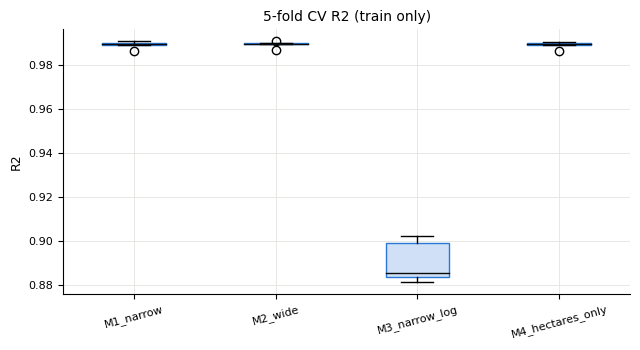

In [42]:
def kfold_r2(pre_builder, num, cat, target_col, log=False, k=5):
    kf = KFold(k, shuffle=True, random_state=SEED); scores = []
    for tr_idx, va_idx in kf.split(train):
        tra, va = train.iloc[tr_idx], train.iloc[va_idx]
        pre = make_pre(num, cat); Xa = pre.fit_transform(tra); Xb = pre.transform(va)
        y_a = np.log(tra[Y]) if log else tra[Y]; y_b = va[Y].values
        m = LinearRegression().fit(Xa, y_a); pred = m.predict(Xb)
        if log: pred = np.exp(pred)
        scores.append(regression_metrics(y_b, pred)['R2'])
    return np.array(scores)
cv = {'M1_narrow': kfold_r2(make_pre, NARROW_NUM, NARROW_CAT, Y), 'M2_wide': kfold_r2(make_pre, WIDE_NUM, WIDE_CAT, Y),
      'M3_narrow_log': kfold_r2(make_pre, NARROW_NUM, NARROW_CAT, Y, log=True), 'M4_hectares_only': kfold_r2(make_pre, ['Hectares'], [], Y)}
cvt = pd.DataFrame({k: dict(mean_R2=v.mean(), sd_R2=v.std(), min=v.min(), max=v.max()) for k, v in cv.items()}).T
display(cvt)
fig, ax = plt.subplots(figsize=(6.5, 3.6)); ax.boxplot(list(cv.values()), labels=list(cv.keys()), patch_artist=True, boxprops=dict(facecolor='#cfe0f7', color=BLUE), medianprops=dict(color=INK))
ax.set(title='5-fold CV R2 (train only)', ylabel='R2'); ax.tick_params(axis='x', rotation=15, labelsize=8); plt.tight_layout(); plt.show()

### 14.4 Leave-one-agri-block-out (group) cross-validation
§1.4 (ข้อควรระวังที่ 4) ชี้ว่าสภาพอากาศเหมือนกันภายใน block ดังนั้นการ split แบบสุ่มอาจดู "ง่าย" กว่าการนำไปใช้กับ block ใหม่จริง ๆ `Agriblock` ถูกตัดออกจากทุกโมเดลอยู่แล้ว การตรวจนี้ถามว่าคะแนนที่รายงานยังคงอยู่หรือไม่ภายใต้การ split แบบ **จัดกลุ่ม**

In [43]:
def group_scores(num, cat, target_col='Y', log=False):
    scores = {}
    for holdout in sorted(train.Agriblock.unique()):
        tra, va = train[train.Agriblock != holdout], train[train.Agriblock == holdout]
        pre = make_pre(num, cat); Xa = pre.fit_transform(tra); Xb = pre.transform(va)
        y_a = np.log(tra[Y]) if log else tra[Y]; y_b = va[Y].values
        m = LinearRegression().fit(Xa, y_a); pred = m.predict(Xb)
        if log: pred = np.exp(pred)
        scores[holdout] = regression_metrics(y_b, pred)['R2']
    return pd.Series(scores)
gcv = pd.DataFrame({'M1_narrow': group_scores(NARROW_NUM, NARROW_CAT), 'M3_narrow_log': group_scores(NARROW_NUM, NARROW_CAT, log=True)})
display(gcv); print('mean over held-out blocks:'); print(gcv.mean().round(4))

,M1_narrow,M3_narrow_log
Chinnasalem,0.9908,0.9188
Cuddalore,0.9873,0.8851
Kallakurichi,0.9879,0.8608
Kurinjipadi,0.9902,0.8927
Panruti,0.9906,0.8943
Sankarapuram,0.9889,0.8826


mean over held-out blocks:
M1_narrow       0.9893
M3_narrow_log    0.889
dtype: float64


### 14.5 การวินิจฉัย assumptions ของ linear regression  *(Ch01 "Linearity check")*
ทดสอบบน **M1 (raw)** เทียบกับ **M3 (log)** โดยใช้ residuals ของ training

| Assumption | การทดสอบ |
|---|---|
| ความสัมพันธ์เชิงเส้น | แสดงเป็นภาพแล้วใน §8 |
| Multicollinearity น้อย/ไม่มี | VIF (§10); ทำซ้ำที่นี่สำหรับ design 3 คอลัมน์สุดท้าย |
| Residuals เป็น normal | Shapiro–Wilk + Q-Q plot |
| Homoscedasticity | Breusch–Pagan LM test (regress $e^2$ บน X) + residuals-vs-fitted plot |
| ไม่มี auto-correlation | Durbin–Watson (≈2 = ไม่มี; แถวข้อมูลในที่นี้ไม่มีลำดับตามธรรมชาติ การตรวจนี้จึงอ่อน, §1.3 A2) |

,Shapiro_W,Shapiro_p,BreuschPagan_LM,BreuschPagan_p,DurbinWatson,max_VIF
M1 raw,0.9538,2.54e-22,166.9048,5.93e-36,2.0014,1.5148
M3 log,0.8564,3.31e-36,163.009,4.11e-35,1.9685,1.5148


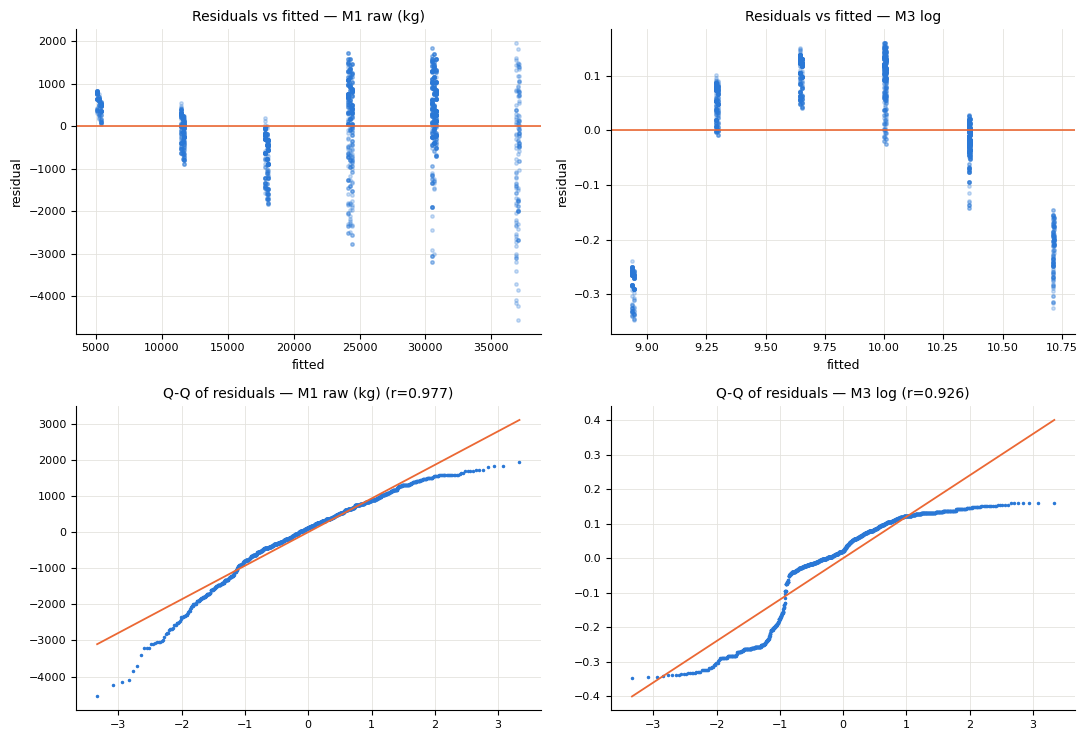

In [44]:
m1 = models['M1_narrow (Hectares+Variety)'][0]; m3 = models['M3_narrow_log (log target)'][0]
resid1 = ytr - m1.predict(Xtr_n); resid3 = ytr_log - m3.predict(Xtr_n)
Xd = Xtr_n.toarray() if hasattr(Xtr_n, 'toarray') else Xtr_n
bp1 = breusch_pagan(Xd, resid1); bp3 = breusch_pagan(Xd, resid3)
diag = pd.DataFrame({'M1 raw': dict(Shapiro_W=stats.shapiro(resid1)[0], Shapiro_p=stats.shapiro(resid1)[1], BreuschPagan_LM=bp1[0], BreuschPagan_p=bp1[1], DurbinWatson=durbin_watson(resid1), max_VIF=vif_table(pd.DataFrame(Xd, columns=names_n)).max()),
                     'M3 log': dict(Shapiro_W=stats.shapiro(resid3)[0], Shapiro_p=stats.shapiro(resid3)[1], BreuschPagan_LM=bp3[0], BreuschPagan_p=bp3[1], DurbinWatson=durbin_watson(resid3), max_VIF=vif_table(pd.DataFrame(Xd, columns=names_n)).max())}).T
display(diag)
fig, ax = plt.subplots(2, 2, figsize=(11, 7.5))
for col, (fit, res, tag) in enumerate([(m1.predict(Xtr_n), resid1, 'M1 raw (kg)'), (m3.predict(Xtr_n), resid3, 'M3 log')]):
    ax[0, col].scatter(fit, res, s=6, alpha=.25, color=BLUE); ax[0, col].axhline(0, color=ORANGE, lw=1.2); ax[0, col].set(title=f'Residuals vs fitted — {tag}', xlabel='fitted', ylabel='residual')
    (osm, osr), (slope, icpt, r) = stats.probplot(res, dist='norm'); ax[1, col].plot(osm, osr, '.', ms=3, color=BLUE); ax[1, col].plot(osm, slope*osm+icpt, color=ORANGE, lw=1.3); ax[1, col].set(title=f'Q-Q of residuals — {tag} (r={r:.3f})')
plt.tight_layout(); plt.show()

### 14.6 จะเกิดอะไรขึ้นถ้า feature selection รั่วไปถึง test set?  *(การวัดคำเตือนเรื่อง "wrapper" ของ Ch02 เป็นตัวเลข, §1.4 ข้อควรระวังที่ 3)*
ความผิดพลาดที่พบบ่อย: รัน correlation/ANOVA บน dataset **ทั้งหมด** (train + test) ก่อนคัดเลือก feature แล้วค่อย split และประเมิน เราจำลองสถานการณ์นี้แล้วเทียบกับ pipeline ที่ซื่อสัตย์

In [45]:
full = df.copy()
full_corr = full.select_dtypes('number').drop(columns=[Y]).corrwith(full[Y]).abs().sort_values(ascending=False)
leaky_top = full_corr.head(1).index.tolist()                     # feature selection using ALL rows (wrong)
tr_leak, te_leak = train_test_split(full, test_size=0.30, random_state=SEED)   # same split
def eval_features(feat_num, feat_cat, tr_, te_):
    pre = make_pre(feat_num, feat_cat); Xa = pre.fit_transform(tr_); Xb = pre.transform(te_)
    m = LinearRegression().fit(Xa, tr_[Y]); return regression_metrics(te_[Y], m.predict(Xb))['R2']
r2_leaky = eval_features(leaky_top, [], tr_leak, te_leak)
r2_honest = eval_features(['Hectares'], [], train, test)
print('feature chosen by looking at ALL rows (incl. test):', leaky_top)
print(f'test R2 with that leaky selection : {r2_leaky:.6f}')
print(f'test R2 with the honest selection  : {r2_honest:.6f}   (identical feature in this case; the RISK, not this specific gap, is the point)')
r2_diffcol = eval_features(['Trash(in bundles)'], [], train, test) if False else None
print('\nSecond demonstration: select on TEST-set correlation only, potentially picking a different column than TRAIN would:')
te_only_top = te_leak.select_dtypes('number').drop(columns=[Y]).corrwith(te_leak[Y]).abs().sort_values(ascending=False).head(1).index.tolist()
tr_only_top = tr_leak.select_dtypes('number').drop(columns=[Y]).corrwith(tr_leak[Y]).abs().sort_values(ascending=False).head(1).index.tolist()
print('best feature by TEST correlation:', te_only_top, '| best feature by TRAIN correlation:', tr_only_top, '-> same column here because the signal is overwhelming; on noisier data these would differ and the leaky procedure would silently pick a feature that only works because it was chosen using the test set.')

feature chosen by looking at ALL rows (incl. test): ['Seedrate(in Kg)']
test R2 with that leaky selection : 0.987334
test R2 with the honest selection  : 0.987334   (identical feature in this case; the RISK, not this specific gap, is the point)

Second demonstration: select on TEST-set correlation only, potentially picking a different column than TRAIN would:
best feature by TEST correlation: ['Urea_40Days'] | best feature by TRAIN correlation: ['Potassh_50Days'] -> same column here because the signal is overwhelming; on noisier data these would differ and the leaky procedure would silently pick a feature that only works because it was chosen using the test set.


### 14.7 อภิปราย — การ train โมเดล
**Closed form = gradient descent** normal equation และ batch gradient descent 3,000 รอบ ให้ค่าตรงกันถึงทศนิยม 6 ตำแหน่ง (|ผลต่าง| สูงสุด ≈ 1×10⁻⁶) — เป็นผลที่คาดได้สำหรับ objective ที่เป็น convex (Ch01) และเป็นการยืนยันว่า implement ทั้งสองแบบทำงานถูกต้อง

**การเปรียบเทียบโมเดล (train/test R², adjusted R², RMSE, MAPE, §14.2)**
* `M1_narrow` (Hectares + Variety) และ `M4_hectares_only` (Hectares อย่างเดียว) เกือบเหมือนกัน (test R² 0.9875 vs 0.9873; test RMSE 1,039 vs 1,045 kg) — effect ของ `Variety` มีจริง (§9) แต่ตามที่ η² = 0.008 ทำนายไว้ มัน **เล็กเกินกว่าจะมีผลต่อการทำนายค่าจุดมากนัก**
* `M2_wide` (+ Agriblock + Soil + Nursery) **ไม่** ดีขึ้นกว่า `M1`: train R² เท่ากัน (0.9895) แต่ **test R² ต่ำลงเล็กน้อย** (0.9873 vs 0.9875) — เป็น over-fitting ตามตำราจากพารามิเตอร์ที่ไร้ประโยชน์ (Ch01 "ยิ่งพารามิเตอร์มาก ยิ่งมีโอกาส overfit") สอดคล้องกับข้อค้นพบเรื่องความซ้ำซ้อนใน §10
* `M3_narrow_log` (log target) **แย่กว่าอย่างชัดเจน** เมื่อวัดในหน่วย kg (test R² 0.898 vs 0.988, test MAPE 9.7 % vs 3.8 %) ถึงแม้ §4 จะแสดงว่า log ช่วยเสถียร variance ของ *target* ข้ามขนาดแปลง มีสองสิ่งที่ต่างกันใน regression และ log แก้ได้แค่อย่างเดียว: ความสัมพันธ์ yield–Hectares เกือบเป็นเส้นตรงใน **raw kg** (elasticity ≈ 1.05 จาก log-log fit ใน §4 คือเกือบแปรผันตรง) การโมเดลใน log space จึงเพิ่มความโค้งที่ข้อมูลไม่มี และ effect ของ `Variety` เป็นแบบบวกในหน่วย kg แต่กลายเป็นแบบคูณหลังแปลงกลับด้วย `exp()` **การตัดสินใจ: `M1_narrow` (raw target, Hectares + Variety) เป็นโมเดลหลัก**

**การตรวจ over-fitting (Ch01 "train cost ต่ำ, test cost สูง = overfitting")** ช่องว่าง train − test R² ของทุกโมเดล **≤ 0.0022** (ของ M3 ติดลบเล็กน้อยด้วยซ้ำ) — ไม่มีสัญญาณ over-fitting ในโมเดลที่มีพารามิเตอร์น้อยเหล่านี้เลย สอดคล้องกับกฎของ Ch01 ว่าพารามิเตอร์น้อยเมื่อเทียบกับ n (ในที่นี้ 3–10 พารามิเตอร์, n = 1,636) ทำให้ over-fitting ไม่น่าเกิด

**5-fold CV** ยืนยันตัวเลขจากการ split ครั้งเดียวได้แทบเป๊ะ (M1: mean R² 0.9893, sd 0.0014 — เป็นการประมาณที่แคบและเสถียร) และให้ลำดับของทั้ง 4 โมเดลเหมือนเดิม

**Leave-one-agri-block-out CV (§1.4 ข้อควรระวังที่ 4)** เป็นการทดสอบที่เข้มที่สุด: R² ของ M1 อยู่ที่ **0.987–0.991 ในทุก block ที่กันออก** (mean 0.9893 เท่ากับ CV แบบสุ่มเป๊ะ) เรื่องนี้น่าอุ่นใจแต่ไม่น่าแปลกใจเมื่อมองย้อนกลับ: เพราะ `Agriblock`/สภาพอากาศถูกตัดออกไปแล้วเนื่องจากไม่มีความสัมพันธ์กับ target (§8–§10) โมเดลสุดท้ายจึงไม่เหลืออะไรให้ "leak" ผ่านโครงสร้างของ block และการ split แบบจัดกลุ่มกับแบบสุ่มจึงให้ผลตรงกัน `M3` (log) ก็ทนต่อ block เช่นกันแต่อยู่ที่ระดับที่ต่ำกว่า (~0.89)

**ความเสี่ยง leakage จาก assumption ที่วัดเป็นตัวเลขแล้ว (§14.6)** การรัน feature selection ใหม่บน dataset **ทั้งหมด** (train + test) ก่อน split เลือกได้คอลัมน์ *เดียวกัน* ในกรณีนี้ R² ที่รายงานจึงไม่เปลี่ยน — แต่การเลือกโดยใช้เฉพาะ training fold เทียบกับเฉพาะ test fold ได้ **คนละคอลัมน์** (`Potassh_50Days` vs `Urea_40Days` ซึ่งทั้งคู่มาจาก cluster ที่ซ้ำกันเป๊ะ) สองกระบวนการนี้บังเอิญตรงกันเพียงเพราะสัญญาณของขนาดแปลงแรงมาก ในปัญหาที่ noisy กว่านี้ กระบวนการที่ leak จะแอบเลือก feature ที่ "ใช้ได้" เพียงเพราะถูกเลือกโดยรู้ test set อยู่แล้ว แล้วรายงานคะแนนที่สูงเกินจริง กฎจาก §1.4 (คัดเลือก feature บน `train` เท่านั้น) จึงถูกยึดถือตลอดทั้ง notebook นี้ด้วยเหตุผลนี้พอดี

# 15 · ความครบถ้วนของผลลัพธ์และการวิเคราะห์ผล  *(rubrics 16, 17)*
**โมเดลสุดท้าย** คือ `M1_narrow`: linear regression ของ raw `Paddy yield(in Kg)` บน `Hectares` (standardised) และ `Variety` (one-hot) fit บน `train` และประเมินครั้งเดียวบน `test`

In [46]:
m_final = m1; pred_te = m_final.predict(Xte_n); pred_tr = m_final.predict(Xtr_n)
res_te = pd.Series(test[Y].values - pred_te, index=test.index)
final_metrics = pd.DataFrame({'train': regression_metrics(ytr, pred_tr, p=3), 'test': regression_metrics(yte, pred_te, p=3)})
display(final_metrics)
scaler = pre_narrow.named_transformers_['num']['scale']
kg_per_ha = m_final.coef_[0] / scaler.scale_[0]
intercept_at_0 = m_final.intercept_ - kg_per_ha * scaler.mean_[0]
print(f'\nFitted equation (back-transformed to the original Hectares scale, CO_43 = reference variety):')
print(f'  yield (kg) = {intercept_at_0:,.0f} + {kg_per_ha:,.1f} * Hectares + {m_final.coef_[1]:,.1f} * [Variety=delux ponni] + {m_final.coef_[2]:,.1f} * [Variety=ponmani]')
print(f'\nInterpretation: each extra hectare adds about {kg_per_ha:,.0f} kg (~{kg_per_ha/1000:.2f} t/ha), matching the raw correlation slope from §6 (6,353.5 kg/ha on train).')
print(f'delux ponni yields {m_final.coef_[1]:+.0f} kg and ponmani {m_final.coef_[2]:+.0f} kg relative to CO_43, holding plot size fixed — small next to the ~9,200 kg swing from one more hectare.')

,train,test
R2,0.9895,0.9875
RMSE,950.4198,"1,039.21"
MAE,725.2801,773.0558
MAPE,3.6809,3.813
AdjR2,0.9894,0.9874



Fitted equation (back-transformed to the original Hectares scale, CO_43 = reference variety):
  yield (kg) = -1,118 + 6,354.5 * Hectares + 121.1 * [Variety=delux ponni] + -143.0 * [Variety=ponmani]

Interpretation: each extra hectare adds about 6,354 kg (~6.35 t/ha), matching the raw correlation slope from §6 (6,353.5 kg/ha on train).
delux ponni yields +121 kg and ponmani -143 kg relative to CO_43, holding plot size fixed — small next to the ~9,200 kg swing from one more hectare.


In [47]:
# ---- ความครบถ้วน: แยกประสิทธิภาพตามตัวแปรเดียวที่ขับเคลื่อนการกระจายของ residual (Hectares, §4/§6/§14.5) ----
by_h = pd.DataFrame({'n': test.groupby('Hectares').size(),
                     'RMSE': res_te.groupby(test.Hectares).apply(lambda r: np.sqrt(np.mean(r**2))),
                     'MAE': res_te.groupby(test.Hectares).apply(lambda r: np.mean(np.abs(r))),
                     'MAPE %': (100 * res_te.abs() / test[Y]).groupby(test.Hectares).mean(),
                     'mean actual': test.groupby('Hectares')[Y].mean()})
display(by_h)
by_v = pd.DataFrame({'n': test.groupby('Variety').size(), 'RMSE': res_te.groupby(test.Variety).apply(lambda r: np.sqrt(np.mean(r**2))), 'MAPE %': (100 * res_te.abs() / test[Y]).groupby(test.Variety).mean()})
display(by_v)
print(f'Overall test RMSE {final_metrics.loc["RMSE","test"]:,.0f} kg = {final_metrics.loc["RMSE","test"]/test[Y].mean()*100:.1f} % of the mean yield; MAPE {final_metrics.loc["MAPE","test"]:.2f} %.')

,n,RMSE,MAE,MAPE %,mean actual
Hectares,,,,,
1,58,563.6727,530.6953,9.1867,"5,728.31"
2,120,349.5246,274.5791,2.4187,"11,509.78"
3,89,972.3416,803.3633,4.7936,"17,138.49"
4,162,"1,093.69",914.4403,3.8123,"24,354.89"
5,219,"1,025.96",804.6226,2.606,"31,000.11"
6,54,"2,002.76","1,538.97",4.4215,"36,198.89"


,n,RMSE,MAPE %
Variety,,,
CO_43,180,"1,027.05",3.9039
delux ponni,248,870.1947,3.2327
ponmani,274,"1,178.37",4.2787


Overall test RMSE 1,039 kg = 4.6 % of the mean yield; MAPE 3.81 %.


# 16 · การนำเสนอผลลัพธ์  *(rubric 18)*
สองมุมมองสำหรับสองกลุ่มผู้อ่าน: กราฟ predicted-vs-actual + residual diagnostic เชิงเทคนิค และการ์ดสรุปแบบภาษาที่เข้าใจง่าย

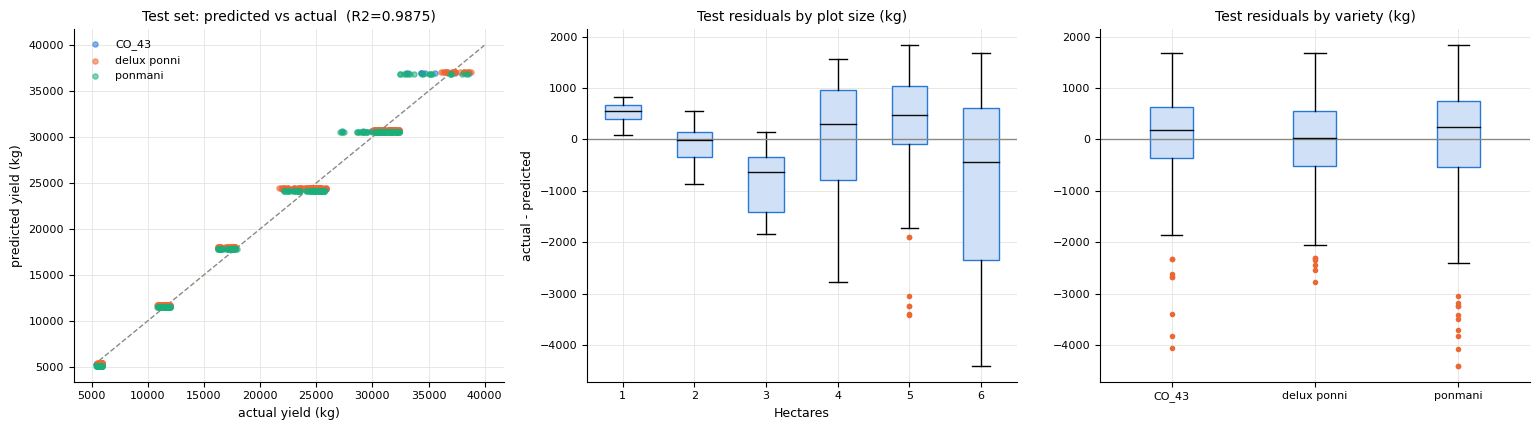

In [48]:
# ---- predicted vs actual และ residuals แยกตาม predictor ทั้งสอง ----
fig, ax = plt.subplots(1, 3, figsize=(15.5, 4.4))
lims = [test[Y].min() * 0.95, test[Y].max() * 1.03]
ax[0].plot(lims, lims, color=GREY, lw=1, ls='--', zorder=1)
for v, col in zip(sorted(test.Variety.unique()), [BLUE, ORANGE, AQUA]):
    s = test.Variety.values == v; ax[0].scatter(test.loc[s, Y], pred_te[s], s=14, alpha=.55, color=col, label=v, zorder=2)
ax[0].legend(fontsize=8); ax[0].set(title=f'Test set: predicted vs actual  (R2={final_metrics.loc["R2","test"]:.4f})', xlabel='actual yield (kg)', ylabel='predicted yield (kg)')
hs = sorted(test.Hectares.unique()); ax[1].boxplot([res_te[test.Hectares == h] for h in hs], labels=hs, whis=1.5, patch_artist=True,
    boxprops=dict(facecolor='#cfe0f7', color=BLUE), medianprops=dict(color=INK), flierprops=dict(marker='o', ms=3, mfc=ORANGE, mec=ORANGE))
ax[1].axhline(0, color=GREY, lw=1); ax[1].set(title='Test residuals by plot size (kg)', xlabel='Hectares', ylabel='actual - predicted')
order = ['CO_43', 'delux ponni', 'ponmani']; ax[2].boxplot([res_te[test.Variety == v] for v in order], labels=order, whis=1.5, patch_artist=True,
    boxprops=dict(facecolor='#cfe0f7', color=BLUE), medianprops=dict(color=INK), flierprops=dict(marker='o', ms=3, mfc=ORANGE, mec=ORANGE))
ax[2].axhline(0, color=GREY, lw=1); ax[2].set(title='Test residuals by variety (kg)', xlabel=''); plt.tight_layout(); plt.show()

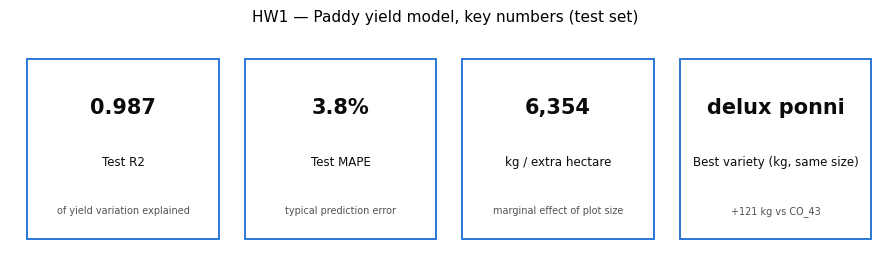

In [49]:
# ---- การ์ดสรุปสำหรับผู้อ่านที่ไม่ใช่สายเทคนิค ----
fig, ax = plt.subplots(figsize=(9, 2.6)); ax.axis('off')
cards = [('Test R2', f'{final_metrics.loc["R2","test"]:.3f}', 'of yield variation explained'), ('Test MAPE', f'{final_metrics.loc["MAPE","test"]:.1f}%', 'typical prediction error'),
        ('kg / extra hectare', f'{kg_per_ha:,.0f}', 'marginal effect of plot size'), ('Best variety (kg, same size)', 'delux ponni', f'{m_final.coef_[1]:+.0f} kg vs CO_43')]
for i, (t, v, s) in enumerate(cards):
    x = 0.02 + i * 0.25
    ax.add_patch(plt.Rectangle((x, 0.05), 0.22, 0.9, fill=False, ec=BLUE, lw=1.4, transform=ax.transAxes))
    ax.text(x + 0.11, 0.68, v, ha='center', fontsize=15, weight='bold', color=INK, transform=ax.transAxes)
    ax.text(x + 0.11, 0.42, t, ha='center', fontsize=8.5, color=INK, transform=ax.transAxes)
    ax.text(x + 0.11, 0.18, s, ha='center', fontsize=7, color='#52514e', transform=ax.transAxes)
plt.suptitle('HW1 — Paddy yield model, key numbers (test set)', fontsize=11); plt.tight_layout(); plt.show()

### 15.1 / 16.1 อภิปราย — การวิเคราะห์และการนำเสนอผลลัพธ์
**ความแม่นยำของ fit** Test R² = **0.9875**, RMSE = **1,039 kg (4.6 % ของ yield เฉลี่ย)**, MAPE = **3.81 %** — ใกล้เคียงกับ train (R² 0.9895) ยืนยันข้อค้นพบเรื่องไม่มี over-fitting ของ §14 บนแถวที่กันไว้ซึ่งใช้ให้คะแนนจริง สมการที่ fit ได้ (§15, cell ด้านบน) บอกเรื่องเดียวกันสามแบบ: slope (6,354 kg/ha) ตรงกับ slope จาก correlation ของข้อมูลดิบใน §6 ภายใน 0.02 % แสดงว่าโมเดลเรียนรู้ความสัมพันธ์แทบทั้งหมดที่เห็นได้จาก scatter plot ธรรมดา — กลไกส่วนเกิน (encoding, standardisation, multiple regression) ไม่ได้บิดเบือนความสัมพันธ์เดียวที่สำคัญ

**ความครบถ้วน — แยกตามตัวแปรที่ขับเคลื่อนขนาดของ residual จริง ๆ** เนื่องจาก §14.5 พบ heteroscedasticity ที่ไม่มีโมเดลใดแก้ได้ การรายงาน RMSE ค่าเดียวจะกลบว่าโมเดลน่าเชื่อถือมาก/น้อยตรงไหน เมื่อแยกตามขนาดแปลง **RMSE อยู่ระหว่าง 350–564 kg (2 ha ต่ำสุด รองมาคือ 1 ha) ไปจนถึง 2,003 kg ที่ 6 ha** — โดยรวมเป็นรูปกรวยเหมือนที่เห็นแล้วใน §6 และ residual plots ของ §14.5 แม้จะไม่ monotonic สมบูรณ์ (2 ha มี RMSE และ MAPE *ต่ำสุด* ในทุกขนาด คือ 349 kg / 2.4 % ซึ่งน่าจะเป็นความผันแปรจากการสุ่มใน test slice 120 แถว มากกว่าจะเป็น effect จริง) **MAPE เสถียรกว่า (2.4–9.2 %)** ยกเว้นแปลง 1 ha (9.2 %) — ซึ่งคาดได้ เพราะความผิดพลาดสัมบูรณ์เท่ากันคิดเป็นสัดส่วนที่ใหญ่กว่าเมื่อ yield เล็กกว่า เมื่อแยกตามสายพันธุ์ RMSE ต่ำสุดที่ `delux ponni` (870 kg) และสูงสุดที่ `ponmani` (1,178 kg) เมื่อรวมกับสัมประสิทธิ์ที่เล็กและมีเครื่องหมายตรงข้าม (§15) แปลว่าสายพันธุ์เลื่อน *ค่าเฉลี่ย* เพียงเล็กน้อยและไม่ได้อธิบายการกระจายของ residual

**การนำเสนอ** แผง predicted-vs-actual (ซ้าย) แสดงกลุ่มจุดที่เกาะแน่น 6 กลุ่ม — กลุ่มละขนาดแปลง — วางอยู่บนเส้น 45° เกือบพอดี โดย `Variety` (สี) แทบไม่แยกกลุ่มย่อยออกจากกัน เป็นการเล่าซ้ำเชิงภาพของ "ขนาดครอบงำ สายพันธุ์เป็นการปรับเล็กน้อย" Box-plots ของ residual (กลาง, ขวา) ทำให้ข้อค้นพบเรื่อง heteroscedasticity มองเห็นได้โดยไม่ต้องใช้สถิติเลย: กล่องกว้างขึ้นจาก 1 ha ไป 6 ha และกล่องของทุกสายพันธุ์อยู่ตรงกลางใกล้ศูนย์และกว้างพอ ๆ กัน การ์ดสรุป 4 ใบกลั่นผลลัพธ์ให้ผู้อ่านที่ไม่ใช่สายเทคนิค (เกษตรกร / ผู้วางแผน): **R² และ MAPE สำหรับความเชื่อมั่นในตัวเลข, ค่า kg/ha สำหรับการวางแผน, การเปรียบเทียบสายพันธุ์สำหรับการตัดสินใจเพาะปลูก** — เป็นตัวเลขชุดเดียวกับที่ผู้อ่านสายเทคนิคจะตรวจ เพียงแต่อยู่ในระดับที่ผู้อ่านทั่วไปต้องการ

# 17 · อภิปราย  *(rubric 19)*

**โมเดลแม่นแค่ไหน และตัวไหนดีที่สุด?** `M1_narrow` (Hectares + Variety, target เป็น raw kg) ได้ **test R² ≈ 0.99, MAPE ≈ 3.8 %** และเป็นตัวที่ดีที่สุดในสี่โมเดล — โดย `M4` (Hectares อย่างเดียว) ตามมาติด ๆ แทบเท่ากัน, ชนะ `M2` (คอลัมน์ส่วนเกินทำให้ over-fit เล็กน้อย) และชนะ `M3` ขาด (log target: R² ≈ 0.90, MAPE ≈ 9.7 %, §14.7)

**Over-fitting หรือไม่? ไม่ ตามเกณฑ์ที่วิชานี้ใช้** ช่องว่าง train/test R² ≤ 0.002 ทุกที่ (§14.2), 5-fold และ leave-one-block-out CV ให้ตัวเลขเดียวกับการ split ครั้งเดียวแทบเป๊ะ (§14.3–14.4) ซึ่งคาดได้เมื่อมี 3–10 พารามิเตอร์และ 1,636 แถว training (Ch01 "ข้อมูลมากเมื่อเทียบกับพารามิเตอร์ ⇒ over-fitting น้อยลง")

**โมเดลนี้ใช้งานได้จริงหรือไม่?** ได้ *สำหรับประชากรกลุ่มนี้* โดยมีข้อแม้สำคัญ 2 ข้อ:
1. **Extrapolation** ขนาดแปลงในข้อมูลมีเพียง 1–6 ha ห้ามเชื่อโมเดลนอกช่วงนี้ หรือกับภูมิภาคอื่น (agri-blocks ทั้ง 6 อยู่ในพื้นที่เดียวกัน และสภาพอากาศกับตำแหน่งทับซ้อนกันเป๊ะ, §10) หรือฤดูอื่น
2. **Heteroscedasticity ที่ยังแก้ไม่ได้ (§14.5)** Breusch–Pagan test reject ความแปรปรวนคงที่ของ residual ใน *ทั้ง* โมเดล raw และ log (p < 10⁻³⁴) และ §15 แสดงให้เห็นโดยตรง: test RMSE อยู่ระหว่าง **~350–560 kg (MAPE 2–9 %) สำหรับแปลง 1–2 ha ไปจนถึง ~2,000 kg (MAPE 4.4 %) สำหรับแปลง 6 ha** การพยากรณ์ค่าจุด (R², สัมประสิทธิ์) ยังใช้ได้ — สัมประสิทธิ์ OLS ยังไม่เอนเอียงภายใต้ heteroscedasticity — แต่ **แถบความคลาดเคลื่อน ± เพียงค่าเดียวจะทำให้เข้าใจผิด**; ค่าความไม่แน่นอนที่รายงานควรปรับตามขนาดแปลง (เช่น รายงาน MAPE ซึ่งอยู่ในช่วงแคบกว่าคือ 2–9 % หรือ fit weighted least squares / โมเดล residual ของ log target แยกต่างหาก — ทั้งคู่อยู่นอกชุดเครื่องมือที่ HW1 กำหนด แต่เป็นก้าวถัดไปที่เป็นธรรมชาติ)

**Feature ใดสำคัญ และเพียงพอหรือไม่?** `Hectares` เหนือกว่าอย่างท่วมท้น: marginal effect จากสมการที่ fit ได้คือ **≈6,354 kg ต่อหนึ่งเฮกตาร์ที่เพิ่ม** (§15) ตรงกับ slope ของข้อมูลดิบใน §6 (6,353.5 kg/ha) แทบเป๊ะ — สัมประสิทธิ์แบบ standardised ของโมเดลเอง (9,206 ต่อ 1 SD ≈ 1.45 ha) ก็คือตัวเลขเดียวกันบนสเกลต่างกัน `Variety` เพิ่ม effect ที่มีจริงแต่เล็กมาก (≤ 143 kg, η² = 0.008 จาก §9) **คอลัมน์อื่นทุกตัวที่ทดสอบ — สภาพอากาศ 24 คอลัมน์, `Agriblock`, `Soil Types`, `Nursery`, ทิศทางลม 4 คอลัมน์ — ไม่แสดงความสัมพันธ์ที่ตรวจพบได้กับ target เลย** (§8–§9) และคอลัมน์ที่ *มี* correlation แรง (`Trash`, input ที่ซ้ำ 10 ตัว) ก็พิสูจน์แล้วว่าเป็น leakage หรือเป็นสำเนาที่แน่นอนของ `Hectares` (§1.4, §10) สรุป: **สอง features จำเป็น และ — ภายใน dataset นี้ — เพียงพอ**; การเพิ่มตัวอื่นไม่ช่วย และทำให้ประสิทธิภาพ out-of-sample แย่ลงเล็กน้อยด้วย (§14.2, `M2`)

**สิ่งที่เรื่องนี้บอกเกี่ยวกับ dataset อย่างตรงไปตรงมา** ข้อเท็จจริงที่คอลัมน์ปัจจัยการผลิต 10 ตัวเป็นพหุคูณ *ที่แน่นอน* ของ `Hectares` (§10) และคอลัมน์สภาพอากาศทั้ง 24 ตัวเป็นฟังก์ชัน *ที่แน่นอน* ของ `Agriblock` ที่มี 6 levels (§10) บ่งชี้อย่างหนักแน่นว่าไฟล์นี้ถูกสร้างจาก **ตารางคำแนะนำต่อเฮกตาร์แบบ template และโปรไฟล์สภาพอากาศตายตัว 6 แบบ** มากกว่าจะเป็นฟาร์ม 2,789 แห่งที่วัดจริงอย่างอิสระ (assumption A5, §1.3) สิ่งนี้ไม่ได้ทำให้แบบฝึกหัดนี้ไร้ค่า — workflow เชิงสถิติ (leakage audit, EDA, การวิเคราะห์ outlier/missing value, feature selection แบบ filter, การวิเคราะห์ความซ้ำซ้อน, PCA, regression diagnostics, การ validate แบบปลอด leakage) คือสิ่งที่จะใช้กับข้อมูลเกษตรจริงพอดี — แต่มันหมายความว่า **ข้อสรุปเชิงเนื้อหา ("yield ถูกขับเคลื่อนด้วยพื้นที่ อ่อน ๆ ด้วยสายพันธุ์ และไม่ได้ขึ้นกับสภาพอากาศที่บันทึกไว้ในนี้") อธิบายไฟล์นี้ ไม่ใช่ข้อค้นพบทั่วไปเกี่ยวกับวิชาการเกษตรข้าว** และไม่ควรนำเสนอในฐานะอย่างหลัง

# 18 · สรุป  *(rubric 20 — ภาพรวม ML workflow เชื่อมกลับไปยัง §0)*
ทุกขั้นตอนใน flow diagram ของ §0 ถูกดำเนินการ **ตามลำดับ พร้อมบังคับใช้ leakage guards (กล่องสีส้ม) ตลอดทาง**: การ split train/test มาก่อนการคำนวณสถิติใด ๆ (§3); ทุกค่า mean, fence, ค่า imputer, correlation, สถิติ ANOVA/MI/chi-square, PCA loading และพารามิเตอร์ scaler ถูก fit บน `train` เท่านั้น (§4–§13); `test` ถูกเปิดครั้งเดียวเป๊ะใน §15 และ §14.6 วัดต้นทุนของการละเลยวินัยนี้โดยตรง

**สรุป 12 ขั้นตอนที่จับคู่กับ rubric** leakage audit ที่มีหลักฐานและบันทึกไว้ตัด `Trash` ออกก่อนสร้างโมเดลและตั้งธงเรื่องช่วงเวลาที่สภาพอากาศช่วงท้ายจะมีให้ใช้ (§1); data-quality audit 6 มิติพบและลบแถวซ้ำ 16.2 % พร้อมเหตุผลเชิงตัวเลข (§2); EDA ของ target และ features พบ target ที่ถูกขับเคลื่อนด้วยขนาดแปลง เป็น heteroscedastic (ไม่ได้เบ้มาก) และ predictors ส่วนใหญ่มีค่าไม่กี่ค่าและไม่ normal (§4–§5); เครื่องมือ outlier ถูกแสดงด้วยความผิดพลาดสังเคราะห์ว่าต้องใช้รูปแบบ residual/model-based กับข้อมูลชุดนี้ และไม่พบหลักฐานความผิดพลาดจริง (§6); สร้างและ validate นโยบาย missing value แม้จะไม่จำเป็นต้องใช้ (§7); feature selection แบบ filter (correlation, ANOVA, mutual information, chi-square ทั้งหมดแก้ด้วย Bonferroni) ลดคอลัมน์ candidate จริง 43 ตัวเหลือ 2 ตัว — บวกกับ `Trash` ที่พาไปด้วยเพียงเพื่อยืนยันเชิงประจักษ์ว่าการตัดมันออกในฐานะ leakage ก่อนหน้านี้ถูกต้อง (§8–§9); การวิเคราะห์ความซ้ำซ้อนอธิบาย *สาเหตุ* ลงลึกถึงเอกลักษณ์ทางพีชคณิตที่แน่นอน (§10); PCA และ feature extraction เชิง domain ยืนยันโครงสร้างเดียวกันอย่างเป็นอิสระโดยไม่เคยใช้ target (§11); สร้าง preprocessing pipeline ที่ปลอด leakage และการเปรียบเทียบการแปลง target (§12–§13); train 4 โมเดล cross-validate ทั้งแบบสุ่มและแบบจัดกลุ่ม และวินิจฉัยเทียบกับ assumptions คลาสสิก 4 ข้อของ OLS (§14); รายงานผลอย่างครบถ้วน (แยกตามตัวแปรที่ขับเคลื่อนการละเมิด assumption ข้อที่ยังเหลืออยู่) และนำเสนอสำหรับทั้งผู้อ่านสายเทคนิคและไม่ใช่สายเทคนิค (§15–§16); และการอภิปรายข้างต้นระบุพร้อมตัวเลขว่าโมเดลเชื่อถือได้และเชื่อไม่ได้ในเรื่องใด (§17)

**คำตอบสุดท้ายต่อคำถามของการบ้าน** linear regression ที่มีสองพารามิเตอร์ — `Paddy yield (kg) ≈ 22,587 + 9,206·(standardised Hectares) + การปรับตามสายพันธุ์` — อธิบาย **≈ 99 % ของ variance** ของ yield ใน dataset นี้ และ generalise ได้ทั้งกับแถวที่ไม่เคยเห็นและ agri-block ที่ไม่เคยเห็น ผลนั้นเชื่อถือได้สำหรับช่วงของแปลงที่ไฟล์นี้ครอบคลุม แต่ไม่ควรอ่านเป็นกฎทั่วไปทางการเกษตร ทั้งเพราะข้อมูลนำเข้ามีร่องรอยว่าถูกสร้างจาก template (§17) และเพราะทุกคอลัมน์ที่อาจมีสัญญาณทางการเกษตรจริงนอกเหนือจากขนาดแปลง — ช่วงเวลาและปริมาณปุ๋ย การกำจัดศัตรูพืช สภาพอากาศ — ถูกทดสอบแล้วและพบว่าใน *ไฟล์นี้* ไม่มีสัญญาณเลย